# Projekt 1 - model ratingowy z interpretowalnością, wyjaśnialnością i kalibracją do 4%

**Zbiór:** `zbior_13.csv` - sprawozdania finansowe 3000 spółek z o.o. i flaga `default`.

**Dwa modele:**
- **interpretowalny** - karta scoringowa: binning monotoniczny → WoE → regresja logistyczna (Lab 1),
- **black-box** - XGBoost strojony w walidacji krzyżowej (Lab 3, krok 3).

**Kolejność kroków** (Lab 3, sześć kroków Projektu 1):

| Sekcja | Krok |
|---|---|
| 1-2 | dane, jakość danych, przeciek, podział |
| 3 | EDA |
| 4-5 | cechy i model interpretowalny |
| 6 | black-box i porównanie |
| 7-9 | wyjaśnienia globalne (SHAP, ważność grup cech - 7.3.1) i lokalne, PDP / ICE / ALE, interakcje (8.4), LIME |
| 10 | wierność i stabilność wyjaśnień |
| 11 | kalibracja statystyczna i dostosowanie do 4% |
| 12 | ratingi, próg decyzyjny, firma graniczna modelu końcowego (12.3.1), porównanie decyzji, global surrogate (12.6) |
| 13 | analiza kontrfaktyczna |
| 14 | audyt podgrup, monitoring, podsumowanie |

**Konwencje:** `default = 1` to zdarzenie ryzyka, model zwraca PD = P(default = 1). **train** - uczenie modeli i wszystkich
przekształceń, **valid** - kalibracja, wybór metody kalibracji i progu, **test** - wyłącznie ocena końcowa.
Fragmenty kodu przeniesione z laboratoriów są oznaczone komentarzem `# z Lab N` (regulamin pkt 10.5).

## 0. Środowisko i parametry

In [1]:
import sys, warnings, json, itertools
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, xgboost, shap, lime
from scipy.special import logit, expit
from scipy.stats import spearmanr, binomtest, beta as beta_dist
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             log_loss, brier_score_loss)
from sklearn.model_selection import train_test_split, StratifiedKFold

print("Python:", sys.version.split()[0], "| numpy:", np.__version__, "| pandas:", pd.__version__,
      "| scikit-learn:", sklearn.__version__, "| xgboost:", xgboost.__version__, "| shap:", shap.__version__,
      "| matplotlib:", matplotlib.__version__)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.figsize"] = (7, 4.5)
KOL = {"train": "#3E5C76", "valid": "#C9A227", "test": "#A3262C", "logit": "#3E5C76", "black-box": "#A3262C"}   # z Lab 3
EPS = 1e-6
RNG_SEED = 42
TARGET_PD = 0.04                    # wymóg Projektu 1: tendencja centralna PD = 4%
MARGIN, LGD = 0.10, 0.45            # ekonomia decyzji (sekcja 12)
TARGET = "default"

Python: 3.11.17 | numpy: 2.4.6 | pandas: 3.1.1 | scikit-learn: 1.9.1 | xgboost: 3.2.0 | shap: 0.51.0 | matplotlib: 3.11.2


## 1. Dane i jakość danych

### 1.1 Definicja PD i słownik danych

- **Zdarzenie:** flaga `default` - zdarzenie ryzyka w przyjętym horyzoncie (zgodnie z opisem projektu).
- **Moment decyzji:** ocena firmy na podstawie ostatniego sprawozdania finansowego. Wszystkie cechy to pozycje
  bilansu, rachunku zysków i strat, przepływów pieniężnych i wskaźniki z nich liczone oraz dane rejestrowe
  (forma prawna, forma własności, PKD) oraz trzy wskaźniki branżowe `wsk_index_*` (spoza słownika danych;
  prowadzący potwierdził, że nie zawierają informacji z przyszłości) - są znane w dniu oceny.
- **Dane przekrojowe:** brak daty oceny i identyfikatora firmy, więc podział jest losowy, stratyfikowany po `default`
  i grupowy - obserwacje, które mogą być tą samą firmą w kolejnych latach, trafiają do jednego zbioru (1.2, 1.4).

In [2]:
df = pd.read_csv("dane/zbior_13.csv")
print(f"n = {len(df):,} | cech: {df.shape[1] - 1} | defaultów: {df[TARGET].sum()} | DR = {df[TARGET].mean():.2%}")

opis = pd.read_csv("dane/opis_zmiennych.csv")          # słownik z Dane_Opis_zmiennych.pdf: zmienna -> obszar
obszar = dict(zip(opis["zmienna"].str.replace("dlugu", "długu"), opis["obszar"]))       # w danych: wsk_koszt_długu_*
print(pd.Series([obszar.get(c, "brak w słowniku") for c in df.columns if c != TARGET]).value_counts().to_string())
print("Zmienne spoza słownika:", [c for c in df.columns if c != TARGET and c not in obszar])
df.head(3)

n = 3,000 | cech: 222 | defaultów: 445 | DR = 14.83%
wskaźnik finansowy         136
pozycja bilansu             54
pozycja RZiS                22
brak w słowniku              5
rachunek przepływów          2
szczególna forma prawna      1
forma własności              1
PKD                          1
Zmienne spoza słownika: ['wsk_index_aktywne', 'wsk_index_skr_zaw', 'wsk_index_nowe', 'schemat_wsk_bilans', 'schemat_wsk_rzis']


,szczegolnaFormaPrawna_Symbol,formaWlasnosci_Symbol,pkdKod,wsk_index_aktywne,wsk_index_skr_zaw,wsk_index_nowe,wsk_liczba_dni_istnienia,Aktywa,Aktywa_trwale,Wartosci_niematerialne_prawne,...,wsk_struktura_kap_wlasnego_s_1,wsk_struktura_kap_wlasnego_s_2,wsk_zadluzenia,wsk_zob_dlugoterminowe_aktywa_rzeczowe,wsk_zob_oprocentowanych,wsk_zob_oprocentowanych_aktywa_rzeczowe,wsk_struktura_kap_obcego_s,wsk_zob_s_aktywa_rzeczowe,wsk_fin_majatku_kapitalem,default
0,117,214,3811,-0.024322,0.343511,0.196646,8215,817000.00,134000.00,0.00,...,0.209302,0.212159,3.777778,0.410037,0.0,0.0,0.790698,0.777234,0.054173,1
1,117,215,3821,0.027073,0.354839,0.435294,2105,40604.45,0.00,0.00,...,0.431132,2.706957,1.319474,0.517185,0.0,0.0,0.568868,-0.271864,0.431132,1
2,117,215,7311,0.053428,0.351690,0.417817,1458,1269563.78,323411.06,226537.02,...,0.444981,0.462152,0.559528,0.022711,0.0,0.0,0.555019,0.517866,0.518583,1


### 1.2 Kontrola jakości danych (Data Quality)

Sprawdzamy: wartości nieskończone (dzielenie przez zero we wskaźnikach), braki, kolumny stałe i zduplikowane,
duplikaty obserwacji. Decyzje o usunięciu kolumn zależą tylko od opisu danych albo od zbioru train (1.4).

In [3]:
num_all = df.drop(columns=TARGET).select_dtypes("number")
inf_kol = num_all.columns[np.isinf(num_all).any()].tolist()
print("Kolumny z wartościami ±inf:", {c: int(np.isinf(df[c]).sum()) for c in inf_kol})
df[inf_kol] = df[inf_kol].replace([np.inf, -np.inf], np.nan)        # ±inf traktujemy jak brak (wskaźnik nieokreślony)

braki = df.isna().mean().sort_values(ascending=False)
display(braki[braki > 0].to_frame("udział braków").round(3))
print("Duplikaty wierszy:", df.duplicated().sum(), "| duplikaty bez flagi default:", df.drop(columns=TARGET).duplicated().sum())
print("Kolumny stałe:", [c for c in df.columns if df[c].nunique(dropna=False) <= 1])
print("schemat_wsk_bilans = schemat_wsk_rzis w", f"{(df['schemat_wsk_bilans'] == df['schemat_wsk_rzis']).mean():.1%} obserwacji")

Kolumny z wartościami ±inf: {'wsk_kapital_do_aktywa': 13, 'wsk_plynnosc_biez_1': 920, 'wsk_struktura_kap_wlasnego_s_2': 93}


,udział braków
RP_przeplywy_operacyjne,0.986
wsk_zadluzenia_gotowki_2,0.986
wsk_pokrycie_wyd_fin_gotowkowe_2,0.986
wsk_zysk_CF_operacyjny,0.986
wsk_pokrycie_zob_kr_gotowkowe_2,0.986
wsk_akt_generowania_got_2,0.986
RP_amortyzacja,0.948
wsk_plynnosc_biez_1,0.339
wsk_struktura_kap_wlasnego_s_2,0.044
wsk_kapital_do_aktywa,0.017


Duplikaty wierszy: 0 | duplikaty bez flagi default: 0
Kolumny stałe: ['szczegolnaFormaPrawna_Symbol', 'Naleznosci_dostaw_uslug_pow12m_kapitale']
schemat_wsk_bilans = schemat_wsk_rzis w 97.6% obserwacji


**Powtarzające się podmioty.** Zbiór nie ma identyfikatora firmy. Sprawdzamy, czy ta sama firma nie występuje
kilka razy (np. w kolejnych latach): szukamy par z tym samym PKD, formą własności i kapitałem podstawowym,
których wiek różni się o pełną liczbę lat (±3 dni). Jeśli takich par jest tyle, ile wynika z przypadku, nie ma
podstaw do podziału grupowego.

In [4]:
def pary_rok_pozniej(dane):
    # pary firm z tym samym PKD, formą własności i kapitałem, których wiek różni się o 1-6 pełnych lat (±3 dni)
    pary = []
    for _, g in dane.groupby(["pkdKod", "formaWlasnosci_Symbol", "Kapital_podstawowy"]):
        for a, b in itertools.combinations(g.index, 2):
            d = abs(dane.at[a, "wsk_liczba_dni_istnienia"] - dane.at[b, "wsk_liczba_dni_istnienia"]); k = round(d / 365.25)
            if 1 <= k <= 6 and abs(d - k * 365.25) <= 3:
                pary.append((a, b))
    return pary

PARY = pary_rok_pozniej(df)
rng = np.random.default_rng(RNG_SEED)                       # poziom przypadku: wiek firm losowo przemieszany
losowe = [len(pary_rok_pozniej(df.assign(wsk_liczba_dni_istnienia=rng.permutation(df["wsk_liczba_dni_istnienia"].to_numpy()))))
          for _ in range(5)]
print(f"Pary „ta sama firma rok później”: w danych {len(PARY)} | po losowym przemieszaniu wieku: "
      f"średnio {np.mean(losowe):.0f} (min {min(losowe)}, max {max(losowe)})")
print("Wartości wsk_index_skr_zaw na kod PKD (średnio):", round(df.groupby("pkdKod")["wsk_index_skr_zaw"].nunique().mean(), 2))

Pary „ta sama firma rok później”: w danych 61 | po losowym przemieszaniu wieku: średnio 35 (min 31, max 38)
Wartości wsk_index_skr_zaw na kod PKD (średnio): 2.98


**Wnioski:**
- Par „rok później” jest wyraźnie więcej niż przy losowym wieku (różnica rzędu kilkudziesięciu par). Do tego wskaźniki
  `wsk_index_*` mają ok. 3 różne wartości na kod PKD - wyglądają na wskaźniki **branżowe liczone dla kilku okresów**.
  Dane pochodzą więc najpewniej z kilku lat i część firm może występować kilka razy.
- Pełnych duplikatów nie ma, a identyfikatora brak, więc stosujemy **ostrożny podział grupowy**: firmy z każdej pary
  kandydatów (i łańcuchów takich par) tworzą jedną grupę. Grupa trafia w całości do jednego zbioru (train, valid albo
  test) i do jednego foldu CV. Kosztem jest kilkadziesiąt „fałszywych” grup różnych firm - to nie szkodzi ocenie.

In [5]:
grupa = pd.Series(np.arange(len(df)), index=df.index)        # union-find: wspólna grupa dla każdej pary kandydatów
def korzen(i):
    while grupa[i] != i:
        i = grupa[i]
    return i
for a, b in PARY:
    ra, rb = korzen(a), korzen(b)
    if ra != rb:
        grupa[max(ra, rb)] = min(ra, rb)
df["grupa"] = [korzen(i) for i in df.index]
rozmiar = df["grupa"].value_counts()
print(f"Grup: {len(rozmiar):,} | grup wieloelementowych: {(rozmiar > 1).sum()} (obserwacji w nich: {rozmiar[rozmiar > 1].sum()})")
#
# ### 1.3 Cechy pochodne i kategorie
#
# - `pkdKod` (400 kodów) → **sekcja PKD** (litera A-U) - stały słownik GUS, bez dopasowania do danych,
# - `formaWlasnosci_Symbol` i `schemat_wsk_bilans` (wielkość jednostki: SFJMI - mikro, SFJMA - mała, SFJIN - pozostałe) jako kategorie,
# - usuwamy: `szczegolnaFormaPrawna_Symbol` (stała - same spółki z o.o.), `schemat_wsk_rzis` (powiela `schemat_wsk_bilans`),
#   `pkdKod` (zastąpiony sekcją).

Grup: 2,942 | grup wieloelementowych: 51 (obserwacji w nich: 109)


/var/folders/n7/4zsqd2sx705658c_kkhmx0c80000gn/T/ipykernel_45653/2624570969.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["grupa"] = [korzen(i) for i in df.index]


In [6]:
SEKCJE = [("A", 1, 3), ("B", 5, 9), ("C", 10, 33), ("D", 35, 35), ("E", 36, 39), ("F", 41, 43), ("G", 45, 47),
          ("H", 49, 53), ("I", 55, 56), ("J", 58, 63), ("K", 64, 66), ("L", 68, 68), ("M", 69, 75), ("N", 77, 82),
          ("O", 84, 84), ("P", 85, 85), ("Q", 86, 88), ("R", 90, 93), ("S", 94, 96), ("T", 97, 98), ("U", 99, 99)]

def sekcja_pkd(kod):
    dzial = int(kod) // 100
    return next((s for s, a, b in SEKCJE if a <= dzial <= b), "INNE")

df = df.copy()
df["sekcja_pkd"] = df["pkdKod"].map(sekcja_pkd)
df["forma_wlasnosci"] = "F" + df["formaWlasnosci_Symbol"].astype(str)
df["wielkosc"] = df["schemat_wsk_bilans"].map({"SFJMI": "mikro", "SFJMA": "mała", "SFJIN": "pozostałe"})
df = df.drop(columns=["szczegolnaFormaPrawna_Symbol", "schemat_wsk_rzis", "schemat_wsk_bilans", "pkdKod", "formaWlasnosci_Symbol"])
display(df.groupby("sekcja_pkd")[TARGET].agg(n="size", DR="mean").sort_values("n", ascending=False).head(10).round(3))

,n,DR
sekcja_pkd,,
G,555,0.133
M,454,0.152
C,369,0.125
F,322,0.152
L,238,0.126
J,228,0.171
N,147,0.211
H,139,0.122
K,94,0.117


### 1.4 Podział stratyfikowany train / valid / test (60 / 20 / 20) i walidacja krzyżowa

```
              ┌──────────── train 60% ────────────┐┌─ valid 20% ─┐┌─ test 20% ─┐
dane (3000) → │ uczenie modeli, binning/WoE,       ││ kalibracja,  ││ wyłącznie  │
              │ selekcja cech, tuning:             ││ wybór metody,││ ocena      │
              │ StratifiedKFold(5) wewnątrz train  ││ δ do 4%, próg││ końcowa    │
              └────────────────────────────────────┘└──────────────┘└────────────┘
```

- podział losowy, **stratyfikowany po `default` i grupowy** (`StratifiedGroupKFold`): dzielimy dane na 5 równych części
  z zachowaniem DR i grup z 1.2; 3 części → train, 1 → valid, 1 → test,
- **5-krotna stratyfikowana grupowa CV na train**: wybór liczby cech karty, strojenie black-boxa, stabilność metryk i wyjaśnień,
- każda transformacja wymagająca dopasowania (mediany, binning, WoE, selekcja cech, kodowanie kategorii) jest
  liczona tylko na train (albo na foldach treningowych w CV),
- kalibracja i próg - tylko na valid, test - tylko do raportu. Podział zapisujemy do `wyniki/podzial.csv`.

In [7]:
from sklearn.model_selection import StratifiedGroupKFold

czesci = [b for _, b in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RNG_SEED).split(df, df[TARGET], groups=df["grupa"])]
zbior = pd.Series("train", index=df.index); zbior.iloc[czesci[3]] = "valid"; zbior.iloc[czesci[4]] = "test"
zbior.rename("zbior").to_frame().assign(grupa=df["grupa"]).to_csv("wyniki/podzial.csv", index_label="wiersz")   # zapis podziału
df_train, df_valid, df_test = (df[zbior == s].copy() for s in ["train", "valid", "test"])
for nazwa, part in [("train", df_train), ("valid", df_valid), ("test", df_test)]:
    print(f"{nazwa:5s} n = {len(part):5,d}   defaulty = {part[TARGET].sum():4d}   DR = {part[TARGET].mean():.2%}")
wspolne = [len(set(a["grupa"]) & set(b["grupa"])) for a, b in [(df_train, df_valid), (df_train, df_test), (df_valid, df_test)]]
print("Wspólne grupy train-valid, train-test, valid-test:", wspolne)
CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RNG_SEED)
FOLDY = list(CV.split(df_train, df_train[TARGET], groups=df_train["grupa"]))          # te same foldy w całym notebooku

train n = 1,801   defaulty =  267   DR = 14.83%
valid n =   600   defaulty =   89   DR = 14.83%
test  n =   599   defaulty =   89   DR = 14.86%
Wspólne grupy train-valid, train-test, valid-test: [0, 0, 0]


### 1.5 Usunięcie cech na podstawie train

Na train: usuwamy cechy z > 50% braków (przepływy pieniężne - prawie zawsze puste), prawie stałe (> 99% jednej
wartości) i zduplikowane (identyczne kolumny - zostawiamy pierwszą).

In [8]:
cat_cols = ["sekcja_pkd", "forma_wlasnosci", "wielkosc"]
kandydaci = [c for c in df.columns if c not in [TARGET, "grupa"] + cat_cols]
usun_braki = [c for c in kandydaci if df_train[c].isna().mean() > 0.5]
usun_stale = [c for c in kandydaci if df_train[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.99]
pozostale = [c for c in kandydaci if c not in usun_braki + usun_stale]
usun_duplikaty = df_train[pozostale].T.duplicated().pipe(lambda s: s[s].index.tolist())
print("Braki > 50%:", usun_braki)
print("Prawie stałe:", usun_stale)
print("Duplikaty innych kolumn:", usun_duplikaty)
num_cols = [c for c in pozostale if c not in usun_duplikaty]
print(f"Cechy liczbowe: {len(num_cols)} | kategoryczne: {cat_cols}")

Braki > 50%: ['RP_przeplywy_operacyjne', 'RP_amortyzacja', 'wsk_akt_generowania_got_2', 'wsk_pokrycie_wyd_fin_gotowkowe_2', 'wsk_pokrycie_zob_kr_gotowkowe_2', 'wsk_zadluzenia_gotowki_2', 'wsk_zysk_CF_operacyjny']
Prawie stałe: ['Wartosc_firmy', 'Naleznosci_dostaw_uslug_pow12m_powiazane', 'Naleznosci_dostaw_uslug_pow12m_kapitale', 'Pozostale_rezerwy', 'Zobowiazania_dostaw_uslug_pow12m_powiazane', 'Zobowiazania_dostaw_uslug_12m_kapitale', 'Zobowiazania_dostaw_uslug_pow12m_kapitale', 'Ujemna_wartosc_firmy', 'Naleznosci_dostaw_uslug_pow12m', 'Zobowiazania_dostaw_uslug_pow12m']
Duplikaty innych kolumn: ['wsk_rent_sprzedazy', 'wsk_zysk_operacyjny_zob_1', 'wsk_zadluzenie_gotowka', 'wsk_ebitda_zobowiazan_odsetki_1', 'wsk_ebitda_zobowiazan_odsetki_2', 'wsk_poziom_kosztow_operacyjnych', 'wsk_poziom_kosztow_finansowych', 'wsk_struktura_kap_wlasnego_1']
Cechy liczbowe: 192 | kategoryczne: ['sekcja_pkd', 'forma_wlasnosci', 'wielkosc']


### 1.6 Kontrola przecieku (anty-leak)

Test z Lab 3: **AUC każdej cechy osobno** na train. Cecha silniejsza niż cały sensowny model (AUC > 0,85) to sygnał,
że może zawierać informację z przyszłości.

In [9]:
rows = []                                                     # z Lab 3 (1.4)
for c in num_cols:
    m = df_train[c].notna()
    auc = roc_auc_score(df_train.loc[m, TARGET], df_train.loc[m, c])
    rows.append({"cecha": c, "obszar": obszar.get(c, "-"), "AUC jednowymiarowe": max(auc, 1 - auc),
                 "kierunek": "+" if auc >= 0.5 else "-", "braki": 1 - m.mean()})
tab_auc = pd.DataFrame(rows).set_index("cecha").sort_values("AUC jednowymiarowe", ascending=False)
display(tab_auc.head(15).round(3))
podejrzane = tab_auc.index[tab_auc["AUC jednowymiarowe"] > 0.85].tolist()
print("Podejrzanie silne cechy (AUC > 0,85):", podejrzane)

,obszar,AUC jednowymiarowe,kierunek,braki
cecha,,,,
wsk_index_nowe,-,0.718,+,0.0
wsk_index_skr_zaw,-,0.708,+,0.0
Kapital_wlasny,pozycja bilansu,0.658,-,0.0
podatek_dochodowy,pozycja RZiS,0.649,-,0.0
zysk_netto,pozycja RZiS,0.634,-,0.0
zysk_brutto,pozycja RZiS,0.633,-,0.0
wsk_ebitda_1,wskaźnik finansowy,0.631,-,0.0
wsk_ebitda_2,wskaźnik finansowy,0.628,-,0.0
wsk_ROA,wskaźnik finansowy,0.627,-,0.0


Podejrzanie silne cechy (AUC > 0,85): []


Żadna cecha nie przekracza progu 0,85, ale **AUC to tylko sygnał - decyzję podejmujemy na podstawie opisu danych**
(Lab 3). Trzy cechy wymagały wyjaśnienia:

| Cecha | Co wiemy | Ryzyko i rozstrzygnięcie |
|---|---|---|
| `wsk_index_skr_zaw`, `wsk_index_nowe`, `wsk_index_aktywne` | **jedyne cechy merytoryczne spoza słownika danych** (poza technicznym typem sprawozdania `schemat_wsk_*`); ok. 3 wartości na kod PKD - wskaźniki **branżowe dla okresu** (dynamika firm skreślonych / zawieszonych, nowych, aktywnych) | gdyby obejmowały okres po dacie oceny, zawierałyby **informację z przyszłości**; `wsk_index_*` mają najwyższe AUC jednowymiarowe ze wszystkich cech. **Prowadzący potwierdził, że cechy można stosować i nie ma w nich przecieku** |

Wszystkie pozostałe cechy pochodzą ze sprawozdania finansowego albo rejestru, więc są znane w dniu oceny.
**Decyzja:** zostawiamy trzy cechy `wsk_index_*` w zbiorze kandydatów obu modeli. Poniżej sprawdzamy, ile wnoszą - jak w Zadaniu 1 z Lab 3.

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

WSK_INDEX = ["wsk_index_skr_zaw", "wsk_index_nowe", "wsk_index_aktywne"]     # wskaźniki branżowe - nie zależą od decyzji firmy

def gini_prostego_logitu(cechy):                              # z Lab 3 (Zadanie 1); logit na rangach cech (odporny na skrajne wartości)
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000))
    rangi = lambda d: d[cechy].rank(pct=True)
    m.fit(rangi(df_train), df_train[TARGET])
    return {f"Gini {s}": 2 * roc_auc_score(cz[TARGET], m.predict_proba(rangi(cz))[:, 1]) - 1 for s, cz in [("valid", df_valid), ("test", df_test)]}

from sklearn.linear_model import LogisticRegression
bez = [c for c in num_cols if c not in WSK_INDEX]
display(pd.DataFrame({"bez wsk_index_*": gini_prostego_logitu(bez), "z wsk_index_*": gini_prostego_logitu(num_cols)}).T.round(3))
WSK_INDEX = [c for c in WSK_INDEX if c in num_cols]               # zostają w modelach

,Gini valid,Gini test
bez wsk_index_*,0.397,0.373
z wsk_index_*,0.586,0.534


Trzy wskaźniki branżowe podnoszą Gini prostego logitu o kilkanaście punktów - więcej niż cała reszta polityki cech.
Ryzyko firmy zależy więc wyraźnie od kondycji jej branży w danym okresie (odsetek skreśleń i zawieszeń, napływ nowych firm).
Po potwierdzeniu, że wskaźniki są znane w dniu oceny, **używamy ich w obu modelach**. Ograniczenie: są wspólne dla całej
branży i okresu, więc firma nie ma na nie wpływu (w analizie kontrfaktycznej traktujemy je jako niezmienne, sekcja 13),
a po wdrożeniu trzeba je aktualizować dla bieżącego okresu.

## 2. Zmienne objaśniające - zestaw do modelowania

In [11]:
FEATURES = num_cols + cat_cols
X_tr, y_tr = df_train[FEATURES], df_train[TARGET].to_numpy()
X_va, y_va = df_valid[FEATURES], df_valid[TARGET].to_numpy()
X_te, y_te = df_test[FEATURES], df_test[TARGET].to_numpy()
Y = {"train": y_tr, "valid": y_va, "test": y_te}
X = {"train": X_tr, "valid": X_va, "test": X_te}
json.dump({"num_cols": num_cols, "cat_cols": cat_cols, "usuniete": usun_braki + usun_stale + usun_duplikaty},
          open("wyniki/cechy_v1.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)       # wersjonowanie cech
print(f"Zestaw cech v1: {len(FEATURES)} cech")

Zestaw cech v1: 195 cech


## 3. EDA: rozkłady, obserwacje odstające, korelacje, zależność z targetem (train)

### 3.1 Rozkłady i obserwacje odstające

Wskaźniki finansowe mają bardzo ciężkie ogony (dzielenie przez małe mianowniki). Mierzymy skośność i udział
obserwacji poza przedziałem [Q1 - 3·IQR, Q3 + 3·IQR].

In [12]:
opisowe = df_train[num_cols].describe(percentiles=[0.01, 0.5, 0.99]).T
opisowe["skośność"] = df_train[num_cols].skew()
q1, q3 = df_train[num_cols].quantile(0.25), df_train[num_cols].quantile(0.75)
opisowe["odstające (3·IQR)"] = ((df_train[num_cols] < q1 - 3 * (q3 - q1)) | (df_train[num_cols] > q3 + 3 * (q3 - q1))).mean()
print(f"Cechy ze skośnością |s| > 2: {(opisowe['skośność'].abs() > 2).sum()} z {len(num_cols)} | "
      f"mediana udziału obserwacji odstających: {opisowe['odstające (3·IQR)'].median():.1%}")
display(opisowe.loc[tab_auc.index[:8], ["mean", "1%", "50%", "99%", "skośność", "odstające (3·IQR)"]].round(3))

Cechy ze skośnością |s| > 2: 182 z 192 | mediana udziału obserwacji odstających: 12.7%


,mean,1%,50%,99%,skośność,odstające (3·IQR)
wsk_index_nowe,0.278,0.100,0.257,5.840000e-01,1.232,0.003
wsk_index_skr_zaw,0.280,0.081,0.283,4.830000e-01,1.254,0.001
Kapital_wlasny,2320978.174,0.000,233841.170,3.123868e+07,27.012,0.092
podatek_dochodowy,30889.528,-879.000,112.000,5.786742e+05,-7.057,0.135
zysk_netto,107548.107,-1448857.830,0.000,2.557294e+06,-5.380,0.166
zysk_brutto,142650.762,-1583591.760,0.000,3.097777e+06,-1.872,0.165
wsk_ebitda_1,346036.460,-621856.560,10528.020,5.511441e+06,11.016,0.133
wsk_ebitda_2,383950.352,-621856.560,11709.120,6.159873e+06,10.191,0.133


**Polityka obserwacji odstających:** nie usuwamy firm - skrajne wskaźniki to często prawdziwe sygnały ryzyka
(np. ujemny kapitał własny). Model interpretowalny używa **binningu kwantylowego i WoE**, który jest odporny na
wartości skrajne (skrajne wartości trafiają do skrajnego przedziału). Drzewa w XGBoost są niezmiennicze na
monotoniczne przekształcenia i nie wymagają cappingu. Siatki PDP / ICE ograniczamy do kwantyli 2-98% z train.

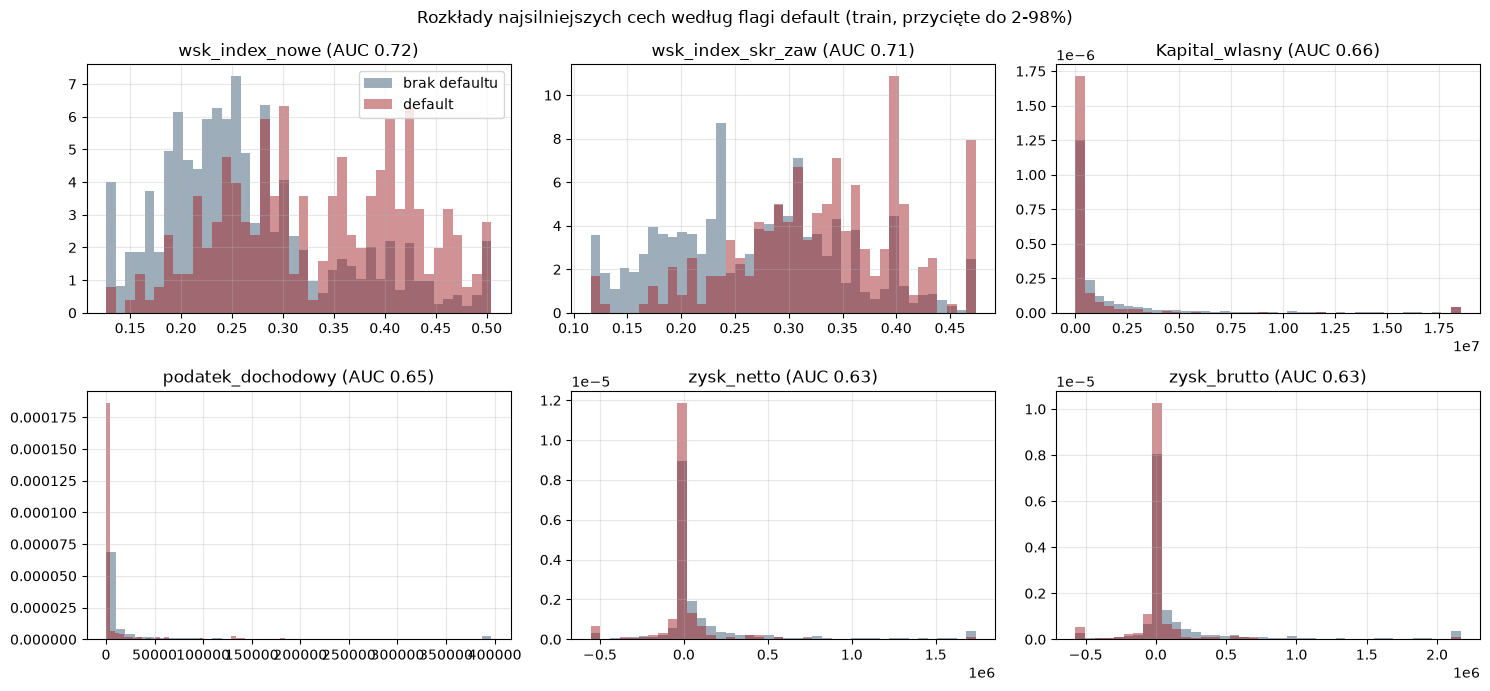

In [13]:
TOP_EDA = tab_auc.index[:6].tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.flat, TOP_EDA):
    lo, hi = df_train[c].quantile([0.02, 0.98])
    for k, kol, lab in [(0, KOL["train"], "brak defaultu"), (1, KOL["test"], "default")]:
        ax.hist(df_train.loc[df_train[TARGET] == k, c].clip(lo, hi), bins=40, density=True, alpha=0.5, color=kol, label=lab)
    ax.set_title(f"{c} (AUC {tab_auc.loc[c, 'AUC jednowymiarowe']:.2f})"); ax.grid(alpha=0.3)
axes[0, 0].legend(); plt.suptitle("Rozkłady najsilniejszych cech według flagi default (train, przycięte do 2-98%)")
plt.tight_layout(); plt.savefig("wykresy/eda_rozklady.png", dpi=120); plt.show()

### 3.2 Zmienne kategoryczne a DR

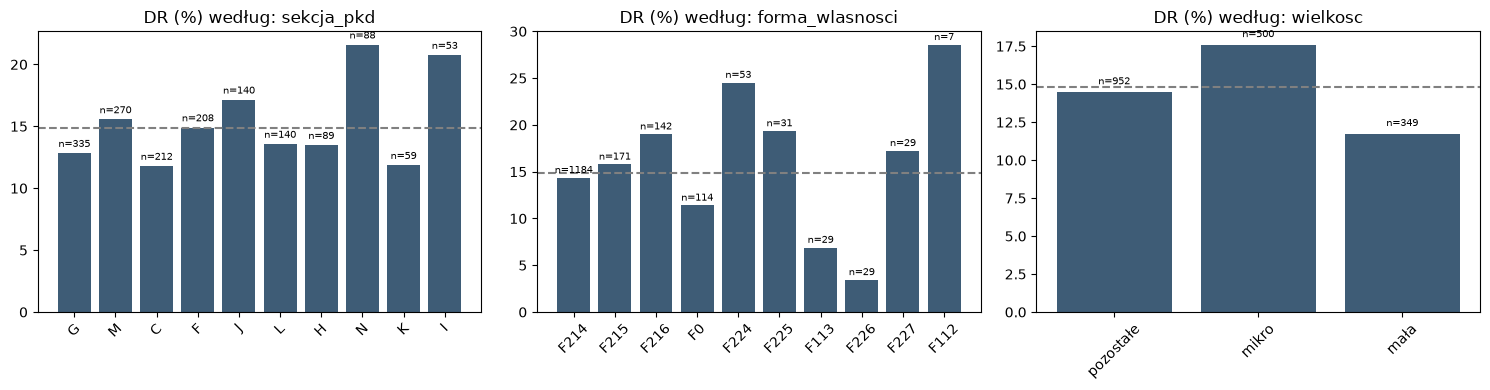

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, cat_cols):
    t = df_train.groupby(c)[TARGET].agg(n="size", DR="mean").sort_values("n", ascending=False).head(10)
    ax.bar(t.index.astype(str), 100 * t["DR"], color=KOL["logit"])
    for i, (n_, dr) in enumerate(zip(t["n"], t["DR"])):
        ax.text(i, 100 * dr + 0.5, f"n={n_}", ha="center", fontsize=7)
    ax.axhline(100 * y_tr.mean(), ls="--", color="gray"); ax.set_title(f"DR (%) według: {c}"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig("wykresy/eda_kategorie.png", dpi=120); plt.show()

### 3.3 Korelacje

Wiele wskaźników to warianty tej samej miary (np. kilka definicji EBITDA czy zadłużenia), więc korelacje są
bardzo wysokie. To ważne dla: (a) selekcji cech do modelu interpretowalnego, (b) interpretacji SHAP i PDP
(rozdzielanie wpływu między skorelowane cechy), (c) analizy kontrfaktycznej.

Par cech z |ρ Spearmana| > 0,9: 219 | > 0,7: 937 (z 36,864)


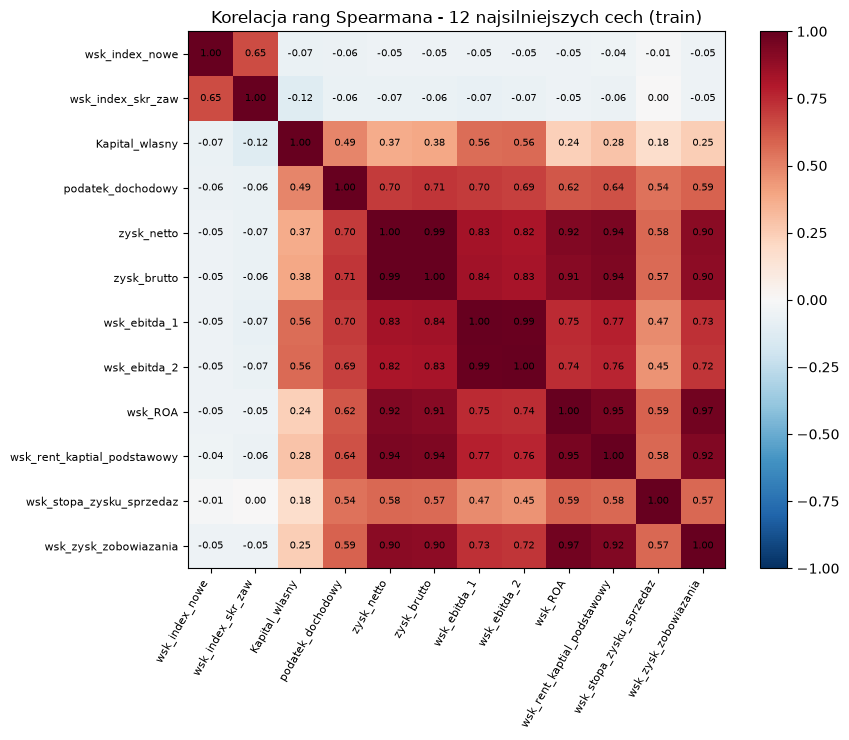

In [15]:
kor = df_train[num_cols].corr(method="spearman").abs()
gorne = kor.where(np.triu(np.ones(kor.shape, dtype=bool), k=1)).stack()
print(f"Par cech z |ρ Spearmana| > 0,9: {(gorne > 0.9).sum()} | > 0,7: {(gorne > 0.7).sum()} (z {len(gorne):,})")
TOP_KOR = tab_auc.index[:12].tolist()
k12 = df_train[TOP_KOR].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(k12.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
for (a, b), val in np.ndenumerate(k12.to_numpy()):
    ax.text(b, a, f"{val:.2f}", ha="center", va="center", fontsize=7)
ax.set_xticks(range(len(TOP_KOR))); ax.set_xticklabels(TOP_KOR, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(TOP_KOR))); ax.set_yticklabels(TOP_KOR, fontsize=8)
ax.set_title("Korelacja rang Spearmana - 12 najsilniejszych cech (train)"); plt.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.savefig("wykresy/eda_korelacje.png", dpi=120); plt.show()

## 4. Przygotowanie cech: binning monotoniczny i WoE (tylko train)

Klasa `WoEBinner` z Lab 1: przedziały kwantylowe łączone do monotonicznego WoE, każdy przedział ≥ 5% obserwacji,
najwyżej 5 przedziałów; rzadkie kategorie → `INNE`. Konwencja: **WoE = ln(%dobrych / %złych)**, WoE > 0 - niższe ryzyko.
Rozszerzenie względem Lab 1: braki danych tworzą **osobny przedział `BRAK`** (brak wskaźnika, np. przez zerowy mianownik,
to też informacja).

In [16]:
from sklearn.base import BaseEstimator, TransformerMixin

class WoEBinner(BaseEstimator, TransformerMixin):
    # z Lab 1 (sekcja 7) - binning + WoE; dodany osobny przedział dla braków danych
    # Konwencja: WoE = ln(%dobrych / %złych), y = 1 oznacza złego klienta.
    def __init__(self, max_bins=5, init_bins=10, min_share=0.05, smoothing=0.5):
        self.max_bins, self.init_bins, self.min_share, self.smoothing = max_bins, init_bins, min_share, smoothing

    def _stats(self, codes, y, k):
        n = np.bincount(codes, minlength=k).astype(float)
        bad = np.bincount(codes, weights=y, minlength=k)
        return n, bad

    def _num_cuts(self, x, y):
        cuts = list(np.unique(np.quantile(x, np.linspace(0, 1, self.init_bins + 1)[1:-1])))
        rho = pd.Series(x).corr(pd.Series(y), method="spearman")
        direction = 1.0 if (not np.isfinite(rho) or rho == 0) else float(np.sign(rho))
        N = len(x)
        while cuts:
            codes = np.searchsorted(cuts, x, side="right"); k = len(cuts) + 1
            n, bad = self._stats(codes, y, k)
            br = bad / np.maximum(n, 1)
            small = np.where(n / N < self.min_share)[0]
            if len(small):
                i = small[0]
                j = i - 1 if i == k - 1 else (i if i == 0 else (i - 1 if abs(br[i] - br[i - 1]) < abs(br[i] - br[i + 1]) else i))
                cuts.pop(j); continue
            viol = np.where(np.diff(br) * direction < 0)[0]
            if len(viol):
                cuts.pop(viol[0]); continue
            if k > self.max_bins:
                cuts.pop(int(np.argmin(np.abs(np.diff(br))))); continue
            break
        return cuts

    def _table(self, codes, y, labels):
        k = len(labels); n, bad = self._stats(codes, y, k); good = n - bad; s = self.smoothing
        pg = (good + s) / (good.sum() + s * k); pb = (bad + s) / (bad.sum() + s * k)
        woe = np.log(pg / pb)
        return pd.DataFrame({"przedział": labels, "N": n.astype(int), "udział": n / n.sum(), "złe": bad.astype(int),
                             "stopa złych": bad / np.maximum(n, 1), "% dobrych": pg, "% złych": pb,
                             "WoE": woe, "IV": (pg - pb) * woe})

    def fit(self, X, y):
        X = pd.DataFrame(X); y = np.asarray(y).astype(float)
        self.cuts_, self.groups_, self.tables_, self.woe_, self.iv_, self.nan_ = {}, {}, {}, {}, {}, {}
        for c in X.columns:
            if pd.api.types.is_numeric_dtype(X[c]):
                x = X[c].to_numpy(dtype=float); ok = ~np.isnan(x)
                cuts = self._num_cuts(x[ok], y[ok]); self.cuts_[c] = cuts
                edges = [-np.inf] + cuts + [np.inf]
                labels = [f"[{edges[i]:.4g}; {edges[i+1]:.4g})" for i in range(len(edges) - 1)]
                self.nan_[c] = bool((~ok).any())                    # osobny przedział BRAK, gdy w train są braki
                if self.nan_[c]:
                    labels = labels + ["BRAK"]
                codes = np.where(ok, np.searchsorted(cuts, np.nan_to_num(x), side="right"), len(cuts) + 1)
            else:
                share = X[c].value_counts(normalize=True)
                groups = {v: (v if share[v] >= self.min_share else "INNE") for v in share.index}
                labels = sorted(set(groups.values()), key=lambda g: (g == "INNE", g))
                self.groups_[c] = (groups, labels)
                codes = X[c].map(groups).map({g: i for i, g in enumerate(labels)}).to_numpy()
            tab = self._table(codes, y, labels)
            self.tables_[c] = tab; self.woe_[c] = tab["WoE"].to_numpy(); self.iv_[c] = float(tab["IV"].sum())
        self.feature_names_in_ = np.array(X.columns)
        return self

    def codes(self, X):
        X = pd.DataFrame(X); out = {}
        for c in self.feature_names_in_:
            if c in self.cuts_:
                x = X[c].to_numpy(dtype=float); k = len(self.cuts_[c])
                kod = np.searchsorted(self.cuts_[c], np.nan_to_num(x), side="right")
                out[c] = np.where(np.isnan(x), k + 1 if self.nan_[c] else -1, kod)    # brak bez przedziału BRAK -> WoE 0
            else:
                groups, labels = self.groups_[c]; idx = {g: i for i, g in enumerate(labels)}
                out[c] = X[c].map(lambda v: idx[groups[v]] if v in groups else (idx["INNE"] if "INNE" in idx else -1)).to_numpy()
        return pd.DataFrame(out, index=X.index)

    def transform(self, X):
        cd = self.codes(X)
        return pd.DataFrame({c: np.where(cd[c] >= 0, self.woe_[c][np.clip(cd[c], 0, None)], 0.0)
                             for c in self.feature_names_in_}, index=cd.index)

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

### 4.1 Information Value - ranking cech (train)

In [17]:
def sila_iv(v):                                              # z Lab 1
    return ("bezużyteczna" if v < 0.02 else "słaba" if v < 0.1 else "średnia" if v < 0.3
            else "silna" if v < 0.5 else "podejrzanie silna – sprawdź przeciek")

binner_all = WoEBinner(max_bins=5, min_share=0.05).fit(X_tr, y_tr)
iv_tab = pd.DataFrame({"cecha": list(binner_all.iv_), "IV": list(binner_all.iv_.values())}).sort_values("IV", ascending=False)
iv_tab["siła"] = iv_tab["IV"].map(sila_iv)
iv_tab["obszar"] = iv_tab["cecha"].map(lambda c: obszar.get(c, "kategoria"))
print(iv_tab["siła"].value_counts().to_string())
display(iv_tab.head(20).set_index("cecha").round(3))

siła
średnia                                 80
słaba                                   74
bezużyteczna                            36
silna                                    3
podejrzanie silna – sprawdź przeciek     2


,IV,siła,obszar
cecha,,,
wsk_index_nowe,0.610,podejrzanie silna – sprawdź przeciek,kategoria
wsk_index_skr_zaw,0.576,podejrzanie silna – sprawdź przeciek,kategoria
podatek_dochodowy,0.366,silna,pozycja RZiS
Kapital_wlasny,0.322,silna,pozycja bilansu
zysk_netto,0.304,silna,pozycja RZiS
zysk_brutto,0.293,średnia,pozycja RZiS
wsk_ogolnego_zadluzenia_1,0.291,średnia,wskaźnik finansowy
wsk_ogolnego_zadluzenia_2,0.284,średnia,wskaźnik finansowy
wsk_kapital_do_aktywa,0.283,średnia,wskaźnik finansowy


### 4.2 Selekcja cech do karty scoringowej

Baseline nie może być „za bogaty” (Lab 3). Procedura na train:
1. kandydaci: IV ≥ 0,1 (co najmniej średnia siła),
2. zachłannie według IV: cechę dodajemy, jeśli |ρ Spearmana| jej WoE z każdą już wybraną < 0,6 (unikamy wariantów tej samej miary),
3. liczbę cech k wybieramy 5-krotną CV na train (AUC): bierzemy k z najwyższym średnim AUC. Reguła „1 błędu standardowego”
   dałaby 3 cechy, ale przy dużym rozrzucie między foldami (odch. std. ok. 0,05) jest zbyt agresywna, a karta z 3 cechami
   pomija całe obszary oceny (zadłużenie, rentowność sprzedaży),
4. kontrola znaków β i VIF (4.3).

In [18]:
W_tr_all = binner_all.transform(X_tr)
kand = iv_tab.loc[iv_tab["IV"] >= 0.1, "cecha"].tolist()
wybrane_kol = []
for c in kand:
    if all(abs(spearmanr(W_tr_all[c], W_tr_all[w])[0]) < 0.6 for w in wybrane_kol):
        wybrane_kol.append(c)
print(f"Kandydaci IV ≥ 0,1: {len(kand)} | po filtrze korelacji: {len(wybrane_kol)}")
print(wybrane_kol)

Kandydaci IV ≥ 0,1: 85 | po filtrze korelacji: 12
['wsk_index_nowe', 'podatek_dochodowy', 'Kapital_wlasny', 'wsk_ogolnego_zadluzenia_1', 'wsk_zysk_zobowiazania', 'wsk_stopa_zysku_sprzedaz', 'wsk_sytuacji_fin', 'pozostale_przychody_oper', 'wsk_rotacja_wartosci_niewaterialnych', 'wsk_ebitda_zobowiazan_odsetki_3', 'wsk_plynnosc_biez_1', 'wsk_struktury_finansowania']


k,2,3,4,5,6,7,8,9,10,11,12
AUC CV,0.7429,0.7548,0.7722,0.7713,0.7725,0.7720,0.7728,0.7697,0.7667,0.7666,0.7656
odch. std.,0.0486,0.0540,0.0506,0.0457,0.0462,0.0489,0.0471,0.0450,0.0459,0.0454,0.0453
błąd std.,0.0217,0.0241,0.0226,0.0204,0.0207,0.0219,0.0211,0.0201,0.0205,0.0203,0.0203


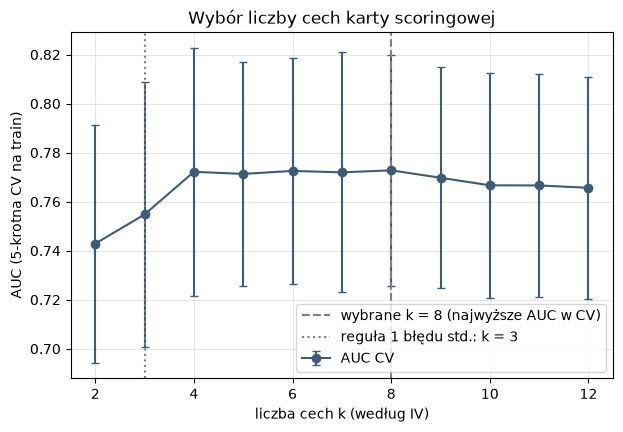

Najlepsze AUC dla k = 8; reguła 1 błędu std. dałaby k = 3; wybieramy k = 8


In [19]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

def lr_bez_kary(**kw):                                       # z Lab 1
    wersja = tuple(int(v) for v in sklearn.__version__.split(".")[:2])
    return LogisticRegression(C=np.inf, **kw) if wersja >= (1, 8) else LogisticRegression(penalty=None, **kw)

def karta(cechy):
    return Pipeline([("woe", WoEBinner(max_bins=5, min_share=0.05)), ("lr", lr_bez_kary(max_iter=5000))])

wiersze = []
for k in range(2, len(wybrane_kol) + 1):
    auc_f = []
    for a, b in FOLDY:                                         # binning dopasowany w każdym foldzie od nowa
        m = karta(wybrane_kol[:k]).fit(X_tr.iloc[a][wybrane_kol[:k]], y_tr[a])
        auc_f.append(roc_auc_score(y_tr[b], m.predict_proba(X_tr.iloc[b][wybrane_kol[:k]])[:, 1]))
    wiersze.append({"k": k, "AUC CV": np.mean(auc_f), "odch. std.": np.std(auc_f), "błąd std.": np.std(auc_f) / np.sqrt(5)})
wybor_k = pd.DataFrame(wiersze).set_index("k")
najl = wybor_k["AUC CV"].idxmax()
K_1SE = int(wybor_k.index[wybor_k["AUC CV"] >= wybor_k.loc[najl, "AUC CV"] - wybor_k.loc[najl, "błąd std."]].min())
K_CECH = int(najl)
display(wybor_k.round(4).T)
ax = wybor_k["AUC CV"].plot(marker="o", yerr=wybor_k["odch. std."], capsize=3, color=KOL["logit"])
ax.axvline(K_CECH, ls="--", color="gray", label=f"wybrane k = {K_CECH} (najwyższe AUC w CV)")
ax.axvline(K_1SE, ls=":", color="gray", label=f"reguła 1 błędu std.: k = {K_1SE}")
ax.set_xlabel("liczba cech k (według IV)"); ax.set_ylabel("AUC (5-krotna CV na train)"); ax.legend(); ax.grid(alpha=0.3)
plt.title("Wybór liczby cech karty scoringowej"); plt.show()
print(f"Najlepsze AUC dla k = {najl}; reguła 1 błędu std. dałaby k = {K_1SE}; wybieramy k = {K_CECH}")

## 5. Model interpretowalny: karta scoringowa (WoE + regresja logistyczna)

### 5.1 Estymacja i kontrola znaków

W konwencji WoE = ln(%dobrych/%złych) wyższe WoE oznacza niższe ryzyko, więc **oczekujemy β < 0** dla każdej cechy
(typowo β ≈ -1). Dodatni współczynnik to sygnał współliniowości albo niestabilnego binningu (Lab 1, 7.3) - taką cechę usuwamy.

In [20]:
CECHY_L = wybrane_kol[:K_CECH]
while True:
    baseline = karta(CECHY_L).fit(X_tr[CECHY_L], y_tr)
    beta_l = pd.Series(baseline.named_steps["lr"].coef_.ravel(), index=CECHY_L)
    if (beta_l < 0).all():
        break
    print(f"Usuwam {beta_l.idxmax()} (β = {beta_l.max():+.3f} ≥ 0)")
    CECHY_L = [c for c in CECHY_L if c != beta_l.idxmax()]

woe_l = baseline.named_steps["woe"]; lr_l = baseline.named_steps["lr"]
W_tr = woe_l.transform(X_tr[CECHY_L])
vif = pd.Series(np.diag(np.linalg.inv(np.corrcoef(W_tr.to_numpy(), rowvar=False))), index=CECHY_L)       # z Lab 3 (Zadanie 2)
tab_beta = pd.DataFrame({"obszar": [obszar.get(c, "kategoria") for c in CECHY_L], "IV": [woe_l.iv_[c] for c in CECHY_L],
                         "β": beta_l, "kontrola znaku": np.where(beta_l < 0, "OK (β < 0)", "UWAGA: β ≥ 0"), "VIF": vif,
                         "liczba przedziałów": [len(woe_l.tables_[c]) for c in CECHY_L]})
import statsmodels.api as sm
sm_l = sm.Logit(y_tr, sm.add_constant(W_tr)).fit(disp=0)                 # wykład 2: istotność β (te same WoE, bez kary)
tab_beta["p-value"] = sm_l.pvalues[CECHY_L]
display(tab_beta.round(3))
print(f"Wyraz wolny: {lr_l.intercept_[0]:.3f} | liczba parametrów: {len(CECHY_L) + 1} | maks. VIF = {vif.max():.2f}")
json.dump({"karta_scoringowa": CECHY_L}, open("wyniki/cechy_karty.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

,obszar,IV,β,kontrola znaku,VIF,liczba przedziałów,p-value
wsk_index_nowe,kategoria,0.610,-0.938,OK (β < 0),1.031,5,0.000
podatek_dochodowy,pozycja RZiS,0.366,-0.512,OK (β < 0),2.189,5,0.004
Kapital_wlasny,pozycja bilansu,0.322,-0.434,OK (β < 0),1.789,5,0.009
wsk_ogolnego_zadluzenia_1,wskaźnik finansowy,0.291,-0.725,OK (β < 0),1.217,3,0.000
wsk_zysk_zobowiazania,wskaźnik finansowy,0.246,-0.147,OK (β < 0),1.760,5,0.449
wsk_stopa_zysku_sprzedaz,wskaźnik finansowy,0.220,-0.403,OK (β < 0),1.705,5,0.040
wsk_sytuacji_fin,wskaźnik finansowy,0.176,-0.185,OK (β < 0),1.265,5,0.324
pozostale_przychody_oper,pozycja RZiS,0.174,-0.248,OK (β < 0),1.484,4,0.237


Wyraz wolny: -1.751 | liczba parametrów: 9 | maks. VIF = 2.19


### 5.2 Ocena jakości: AUC, Gini, KS, PR-AUC, log-loss, Brier

Funkcje metryk z Lab 3 (`metryki`) i Lab 2 (`cox`: calibration intercept *a* i slope *b*). Wszystkie liczymy na train,
valid i test; decyzje podejmujemy na train / valid, test tylko raportujemy.

In [21]:
from scipy.optimize import brentq

def ks(y, p):                                                 # z Lab 3
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

def ece(y, p, n_bins=10):                                     # z Lab 3 - przedziały równej szerokości
    edges = np.linspace(0, 1, n_bins + 1); idx = np.clip(np.digitize(p, edges[1:-1]), 0, n_bins - 1)
    return float(sum(np.mean(idx == m) * abs(y[idx == m].mean() - p[idx == m].mean()) for m in range(n_bins) if np.any(idx == m)))

def ace(y, p, n_bins=10):                                     # z Lab 3 - przedziały równoliczne
    edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    idx = np.clip(np.digitize(p, edges[1:-1], right=True), 0, len(edges) - 2)
    return float(sum(np.mean(idx == m) * abs(y[idx == m].mean() - p[idx == m].mean()) for m in range(len(edges) - 1) if np.any(idx == m)))

def _z(p):
    return logit(np.clip(p, EPS, 1 - EPS))

def cox(y, p):                                                # z Lab 2 - calibration intercept (CITL, przy nachyleniu 1) i slope
    z = _z(p)
    a = brentq(lambda d: expit(z + d).mean() - y.mean(), -15, 15)
    b = LogisticRegression(C=1e6, max_iter=1000).fit(z.reshape(-1, 1), y).coef_[0, 0]
    return a, b

def metryki(y, p):                                            # z Lab 3, rozszerzone o CITL i slope z Lab 2
    y, p = np.asarray(y), np.asarray(p); auc = roc_auc_score(y, p); a, b = cox(y, p)
    return {"n": len(y), "DR": y.mean(), "średnie PD": p.mean(), "AUC": auc, "Gini": 2 * auc - 1, "KS": ks(y, p),
            "PR-AUC": average_precision_score(y, p), "log-loss": log_loss(y, np.clip(p, EPS, 1 - EPS)),
            "Brier": brier_score_loss(y, p), "ECE": ece(y, p), "ACE": ace(y, p), "CITL a": a, "slope b": b}

P = {"logit": {s: baseline.predict_proba(X[s][CECHY_L])[:, 1] for s in X}}
display(pd.DataFrame({s: metryki(Y[s], P["logit"][s]) for s in X}).T.round(4))

,n,DR,średnie PD,AUC,Gini,KS,PR-AUC,log-loss,Brier,ECE,ACE,CITL a,slope b
train,1801.0,0.1483,0.1482,0.7991,0.5982,0.4614,0.4165,0.3430,0.1056,0.0198,0.0148,0.0004,0.9998
valid,600.0,0.1483,0.1346,0.7972,0.5944,0.4819,0.4577,0.3402,0.1031,0.0291,0.0341,0.1349,1.0578
test,599.0,0.1486,0.1468,0.7810,0.5620,0.4397,0.4300,0.3499,0.1050,0.0153,0.0299,0.0167,0.9456


**Wnioski:** karta z 8 cechami ma Gini 0,598 na train, 0,594 na valid i 0,562 na teście - brak wyraźnego przeuczenia (różnica
train - test jest mała wobec rozrzutu w CV, 5.5). Średnie PD jest bliskie DR na train i teście (CITL a ≈ 0,00-0,02), na valid nieco
niższe (13,5% przy DR 14,8%, CITL 0,13); nachylenie kalibracji 0,95-1,06. Model jest skalibrowany do częstości w próbie, co sprawdzimy w 11.

### 5.3 Profile przedziałów WoE (interpretacja globalna)

Dla każdej cechy karty: stopa defaultu i WoE w przedziałach na train oraz **stopa defaultu na valid** w tych samych
przedziałach - sprawdzamy, czy monotoniczny kierunek utrzymuje się na nowych danych (test monotoniczności).

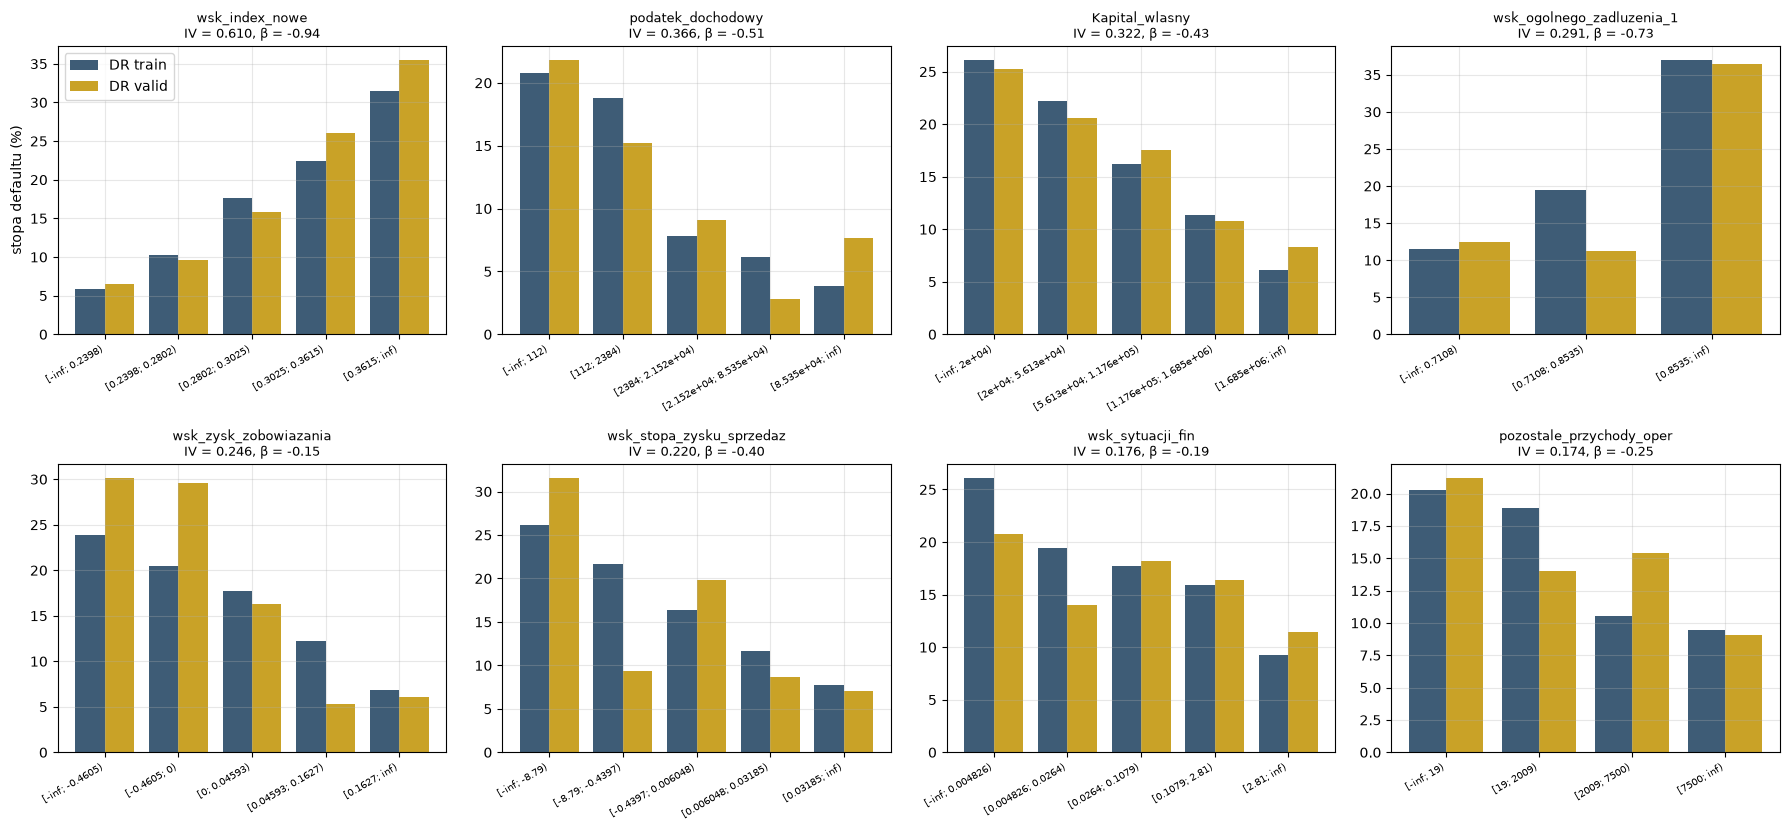

,przedziałów,kierunek na train,zgodnych zmian na valid
wsk_index_nowe,5,rosnący,4 / 4
podatek_dochodowy,5,malejący,3 / 4
Kapital_wlasny,5,malejący,4 / 4
wsk_ogolnego_zadluzenia_1,3,rosnący,1 / 2
wsk_zysk_zobowiazania,5,malejący,3 / 4
wsk_stopa_zysku_sprzedaz,5,malejący,3 / 4
wsk_sytuacji_fin,5,malejący,3 / 4
pozostale_przychody_oper,4,malejący,2 / 3


In [22]:
kody_va = woe_l.codes(X_va[CECHY_L])
n_kol = 4; n_wier = int(np.ceil(len(CECHY_L) / n_kol))
fig, axes = plt.subplots(n_wier, n_kol, figsize=(18, 4.2 * n_wier)); axes = np.atleast_2d(axes)
monot = {}
for ax, c in zip(axes.flat, CECHY_L):
    tab = woe_l.tables_[c].copy()
    tab["stopa złych (valid)"] = [y_va[kody_va[c].to_numpy() == i].mean() if np.any(kody_va[c].to_numpy() == i) else np.nan for i in range(len(tab))]
    x_ = np.arange(len(tab))
    ax.bar(x_ - 0.2, 100 * tab["stopa złych"], 0.4, color=KOL["train"], label="DR train")
    ax.bar(x_ + 0.2, 100 * tab["stopa złych (valid)"], 0.4, color=KOL["valid"], label="DR valid")
    ax.set_xticks(x_); ax.set_xticklabels(tab["przedział"], rotation=30, ha="right", fontsize=7)
    ax.set_title(f"{c}\nIV = {woe_l.iv_[c]:.3f}, β = {beta_l[c]:+.2f}", fontsize=9); ax.grid(alpha=0.3)
    br = tab.loc[tab["przedział"] != "BRAK"]
    kier_tr, kier_va = np.sign(np.diff(br["stopa złych"])), np.sign(np.diff(br["stopa złych (valid)"]))
    monot[c] = {"przedziałów": len(br), "kierunek na train": "rosnący" if kier_tr.sum() > 0 else "malejący",
                "zgodnych zmian na valid": f"{int((kier_tr == kier_va).sum())} / {len(kier_tr)}"}
for ax in axes.flat[len(CECHY_L):]:
    ax.axis("off")
axes.flat[0].legend(); axes.flat[0].set_ylabel("stopa defaultu (%)")
plt.tight_layout(); plt.savefig("wykresy/karta_woe_profile.png", dpi=120); plt.show()
display(pd.DataFrame(monot).T)

**Wnioski:** kierunki zgadzają się z intuicją ekonomiczną: wyższy podatek dochodowy (proxy zysku), kapitał własny, rentowność sprzedaży,
zysk względem zobowiązań, wskaźnik sytuacji finansowej i pozostałe przychody operacyjne → niższe ryzyko; wyższe zadłużenie ogólne →
wyższe ryzyko (skok powyżej ok. 0,85). Wyższy wskaźnik branżowy `wsk_index_nowe` → wyższe ryzyko; jego profil jest najczystszy -
DR rośnie przez wszystkie 5 przedziałów także na valid (4 / 4 zgodne zmiany). Na valid 23 z 29 zmian między sąsiednimi przedziałami
ma ten sam kierunek co na train; niezgodności dotyczą środkowych przedziałów słabszych cech, w których na valid jest kilka-kilkanaście defaultów.

### 5.4 Karta punktowa (PDO) i dekompozycja wyniku

Skalowanie z Lab 1: 600 pkt przy szansach dobry:zły 50:1, PDO = 20 (co 20 pkt szanse się podwajają).
$\text{Punkty}_{ij} = \text{Factor}\cdot(-\beta_j\,\text{WoE}_{ij} - \beta_0/k) + \text{Offset}/k$. Suma punktów firmy
odpowiada logitowi modelu - to **bezpośrednia, dokładna dekompozycja wyniku na wkłady cech** (interpretacja lokalna 9.1).

In [23]:
PDO, SCORE_REF, ODDS_REF = 20, 600, 50                        # z Lab 1 (sekcja 8)
factor = PDO / np.log(2)
offset = SCORE_REF - factor * np.log(ODDS_REF)
b0, betas, k_ = lr_l.intercept_[0], dict(zip(CECHY_L, lr_l.coef_.ravel())), len(CECHY_L)
wiersze = []
for c in CECHY_L:
    tab = woe_l.tables_[c]
    for lab, w in zip(tab["przedział"], tab["WoE"]):
        wiersze.append({"cecha": c, "atrybut": lab, "WoE": w, "punkty": factor * (-betas[c] * w - b0 / k_) + offset / k_})
karta_pkt = pd.DataFrame(wiersze)
karta_pkt["punkty (zaokr.)"] = karta_pkt["punkty"].round().astype(int)
print(f"Factor = {factor:.3f}, Offset = {offset:.2f}")
display(karta_pkt[["cecha", "atrybut", "WoE", "punkty (zaokr.)"]].round(3))

def punkty_firmy(Xw):
    # punkty każdej cechy dla firm z Xw (wiersze) - dekompozycja wyniku karty
    W = woe_l.transform(Xw[CECHY_L])
    return pd.DataFrame({c: factor * (-betas[c] * W[c] - b0 / k_) + offset / k_ for c in CECHY_L}, index=Xw.index)

wynik_model = offset + factor * (-baseline.decision_function(X_te[CECHY_L]))
print("Suma punktów zgodna z modelem:", np.allclose(punkty_firmy(X_te).sum(axis=1), wynik_model),
      f"| wynik na teście: min {wynik_model.min():.0f}, mediana {np.median(wynik_model):.0f}, max {wynik_model.max():.0f}")

Factor = 28.854, Offset = 487.12


,cecha,atrybut,WoE,punkty (zaokr.)
0,wsk_index_nowe,[-inf; 0.2398),1.025,95
1,wsk_index_nowe,[0.2398; 0.2802),0.418,79
2,wsk_index_nowe,[0.2802; 0.3025),-0.207,62
3,wsk_index_nowe,[0.3025; 0.3615),-0.511,53
4,wsk_index_nowe,[0.3615; inf),-0.967,41
5,podatek_dochodowy,[-inf; 112),-0.404,61
6,podatek_dochodowy,[112; 2384),-0.288,63
7,podatek_dochodowy,[2384; 2.152e+04),0.713,78
8,podatek_dochodowy,[2.152e+04; 8.535e+04),0.950,81
9,podatek_dochodowy,[8.535e+04; inf),1.406,88


Suma punktów zgodna z modelem: True | wynik na teście: min 463, mediana 554, max 623


### 5.5 Stabilność modelu interpretowalnego w 5-krotnej CV (train)

W każdym foldzie od nowa: binning, WoE i regresja. Raportujemy rozrzut metryk i współczynników - czy znaki β są
stabilne między foldami.

In [24]:
def metryki_cv(budowa, cechy):
    wiersze, bety = [], []
    for k, (a, b) in enumerate(FOLDY, start=1):
        m = budowa().fit(X_tr.iloc[a][cechy], y_tr[a])
        p = m.predict_proba(X_tr.iloc[b][cechy])[:, 1]
        w = metryki(y_tr[b], p); w["fold"] = k; wiersze.append(w)
        if "lr" in m.named_steps:
            bety.append(pd.Series(m.named_steps["lr"].coef_.ravel(), index=cechy))
    return pd.DataFrame(wiersze).set_index("fold"), (pd.DataFrame(bety) if bety else None)

cv_logit, bety_cv = metryki_cv(lambda: karta(CECHY_L), CECHY_L)
KOL_CV = ["AUC", "Gini", "KS", "PR-AUC", "log-loss", "Brier"]
display(cv_logit[KOL_CV].round(4))
print("Średnia ± odch. std.:", {c: f"{cv_logit[c].mean():.3f} ± {cv_logit[c].std():.3f}" for c in ["Gini", "KS", "log-loss"]})
display(pd.DataFrame({"β (cały train)": beta_l, "β CV średnia": bety_cv.mean(), "β CV odch. std.": bety_cv.std(),
                      "znak ujemny w foldach": (bety_cv < 0).sum().astype(str) + " / 5"}).round(3))

,AUC,Gini,KS,PR-AUC,log-loss,Brier
fold,,,,,,
1,0.7166,0.4333,0.3712,0.3225,0.3832,0.1170
2,0.8298,0.6595,0.5670,0.5138,0.3233,0.0971
3,0.8034,0.6067,0.4970,0.4243,0.3439,0.1068
4,0.7166,0.4333,0.3358,0.3374,0.3981,0.1210
5,0.7975,0.5950,0.4642,0.4180,0.3442,0.1068


Średnia ± odch. std.: {'Gini': '0.546 ± 0.105', 'KS': '0.447 ± 0.094', 'log-loss': '0.359 ± 0.031'}


,β (cały train),β CV średnia,β CV odch. std.,znak ujemny w foldach
wsk_index_nowe,-0.938,-0.938,0.024,5 / 5
podatek_dochodowy,-0.512,-0.493,0.086,5 / 5
Kapital_wlasny,-0.434,-0.470,0.051,5 / 5
wsk_ogolnego_zadluzenia_1,-0.725,-0.732,0.055,5 / 5
wsk_zysk_zobowiazania,-0.147,-0.152,0.150,4 / 5
wsk_stopa_zysku_sprzedaz,-0.403,-0.433,0.117,5 / 5
wsk_sytuacji_fin,-0.185,-0.155,0.078,5 / 5
pozostale_przychody_oper,-0.248,-0.240,0.118,5 / 5


**Wnioski:** Gini w foldach waha się od 0,43 do 0,66 (0,546 ± 0,105). Rozrzut jest duży, bo w foldzie walidacyjnym jest tylko ok. 53
defaultów - pojedyncza ocena na małym zbiorze jest niepewna, dlatego raportujemy przedziały bootstrap (6.2). **Znaki β są stabilne:**
39 z 40 współczynników w foldach jest ujemnych; wyjątek to najsłabsza cecha `wsk_zysk_zobowiazania` (β = -0,15 ± 0,15). Najstabilniejszy
jest `wsk_index_nowe` (β = -0,94 ± 0,02). Pięć z ośmiu β jest istotnych (p < 0,05, 5.1); `wsk_zysk_zobowiazania`, `wsk_sytuacji_fin`
i `pozostale_przychody_oper` mają p-value 0,24-0,45 - zostają, bo mają poprawny znak, a k = 8 ma najwyższe AUC w CV (4.2), choć
przewaga nad k = 4-7 jest w trzecim miejscu po przecinku. Ich wkład jest niepewny.

## 6. Model black-box: XGBoost

### 6.1 Przygotowanie cech i strojenie z kontrolą przeuczenia

- wszystkie cechy liczbowe (192) bez przekształceń - drzewa obsługują braki i są odporne na skrajne wartości,
- kategorie: one-hot, rzadkie poziomy (< 20 firm w train) łączone w „infrequent”,
- **losowe przeszukiwanie (40 konfiguracji) w 5-krotnej CV na train**, kryterium: log-loss (dyskryminacja i kalibracja naraz),
- kontrola przeuczenia: płytkie drzewa, minimalna waga liścia, losowanie wierszy i kolumn, regularyzacja L2 i γ;
  porównujemy wyniki na foldach treningowych i walidacyjnych CV,
- bez wag klas i bez oversamplingu - wtedy PD nie wymaga korekty a priori (Lab 2).

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

def preprocessing_drzewa(num=None):
    return ColumnTransformer([("num", "passthrough", num_cols if num is None else num),
                              ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), cat_cols)])

def model_black_box(num=None, **parametry):
    ustawienia = dict(n_estimators=300, learning_rate=0.05, max_depth=3, min_child_weight=5, subsample=0.8,
                      colsample_bytree=0.5, reg_lambda=5.0, gamma=0.0, tree_method="hist", eval_metric="logloss",
                      n_jobs=-1, random_state=RNG_SEED)
    ustawienia.update(parametry)
    return Pipeline([("pre", preprocessing_drzewa(num)), ("clf", XGBClassifier(**ustawienia))])

siatka_xgb = {"clf__n_estimators": [100, 200, 300, 500, 800], "clf__learning_rate": [0.01, 0.02, 0.05, 0.1],
              "clf__max_depth": [2, 3, 4, 5], "clf__min_child_weight": [1, 5, 10, 20],
              "clf__subsample": [0.6, 0.8, 1.0], "clf__colsample_bytree": [0.2, 0.35, 0.5, 0.8],
              "clf__reg_lambda": [1.0, 5.0, 10.0, 30.0], "clf__gamma": [0.0, 0.5, 2.0]}
szukaj = RandomizedSearchCV(model_black_box(), siatka_xgb, n_iter=40, scoring={"log-loss": "neg_log_loss", "AUC": "roc_auc"},
                            refit="log-loss", cv=FOLDY, random_state=RNG_SEED, return_train_score=True, n_jobs=1)
szukaj.fit(X_tr, y_tr)
wyn = pd.DataFrame(szukaj.cv_results_)
tab_tuning = pd.DataFrame({"log-loss CV": -wyn["mean_test_log-loss"], "log-loss train": -wyn["mean_train_log-loss"],
                           "AUC CV": wyn["mean_test_AUC"], "AUC CV odch. std.": wyn["std_test_AUC"], "AUC train": wyn["mean_train_AUC"]})
tab_tuning = pd.concat([wyn[[c for c in wyn if c.startswith("param_")]].rename(columns=lambda c: c.replace("param_clf__", "")), tab_tuning], axis=1)
tab_tuning["luka AUC (train - CV)"] = tab_tuning["AUC train"] - tab_tuning["AUC CV"]
display(tab_tuning.sort_values("log-loss CV").head(8).round(4))
PARAM_BB = {k.replace("clf__", ""): v for k, v in szukaj.best_params_.items()}
print("Wybrane hiperparametry:", PARAM_BB)
json.dump(PARAM_BB, open("wyniki/xgboost_parametry.json", "w"), indent=1)

,subsample,reg_lambda,n_estimators,min_child_weight,max_depth,learning_rate,gamma,colsample_bytree,log-loss CV,log-loss train,AUC CV,AUC CV odch. std.,AUC train,luka AUC (train - CV)
33,0.6,5.0,800,5,5,0.01,2.0,0.50,0.3502,0.2111,0.7905,0.0369,0.9685,0.1780
8,1.0,1.0,100,10,5,0.05,2.0,0.35,0.3503,0.2283,0.7823,0.0379,0.9615,0.1792
20,0.8,1.0,200,10,5,0.02,0.5,0.50,0.3505,0.2491,0.7845,0.0407,0.9433,0.1588
9,0.8,10.0,300,20,5,0.02,2.0,0.80,0.3507,0.2903,0.7895,0.0391,0.8886,0.0991
31,0.6,5.0,500,20,5,0.02,0.0,0.20,0.3509,0.2917,0.7864,0.0393,0.8867,0.1003
26,1.0,30.0,100,20,2,0.10,0.5,0.35,0.3512,0.3007,0.7875,0.0356,0.8728,0.0854
14,0.6,30.0,300,1,4,0.05,0.0,0.20,0.3515,0.2225,0.7864,0.0367,0.9635,0.1771
30,0.8,1.0,200,1,3,0.02,0.0,0.80,0.3518,0.2469,0.7841,0.0393,0.9441,0.1600


Wybrane hiperparametry: {'subsample': 0.6, 'reg_lambda': 5.0, 'n_estimators': 800, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.01, 'gamma': 2.0, 'colsample_bytree': 0.5}


**Wnioski:** wybrana konfiguracja to 800 drzew o głębokości ≤ 5 z małym `learning_rate` 0,01, losowaniem 50% cech
na drzewo i 60% wierszy, minimalną wagą liścia 5, γ = 2 i λ = 5. Ma najniższy log-loss w CV (0,350) i AUC w CV 0,791 przy AUC 0,969 na foldach
treningowych - luka 0,18 jest jedną z dwóch największych wśród 8 najlepszych konfiguracji (pozostałe 0,09-0,18). Przy 1 800 firmach i 195 cechach
boosting łatwo zapamiętuje dane, dlatego o wyborze decyduje wyłącznie wynik w CV. Różnice log-loss między 8 najlepszymi
konfiguracjami są w trzecim miejscu po przecinku.

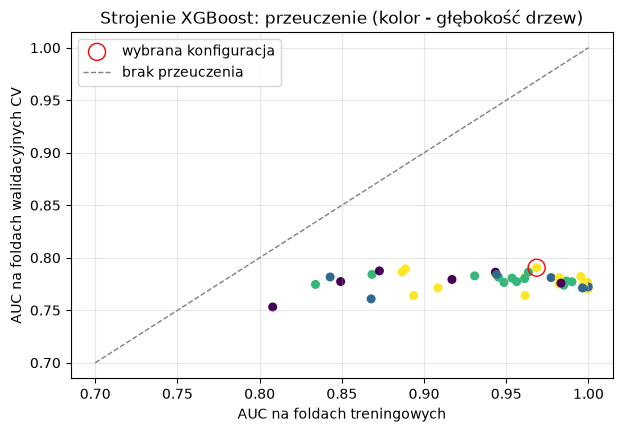

In [26]:
ax = plt.gca()
ax.scatter(tab_tuning["AUC train"], tab_tuning["AUC CV"], c=tab_tuning["max_depth"].astype(float), cmap="viridis", s=30)
najl_i = szukaj.best_index_
ax.scatter(tab_tuning.loc[najl_i, "AUC train"], tab_tuning.loc[najl_i, "AUC CV"], s=150, facecolors="none", edgecolors="red", label="wybrana konfiguracja")
ax.plot([0.7, 1], [0.7, 1], "--", color="gray", lw=1, label="brak przeuczenia")
ax.set_xlabel("AUC na foldach treningowych"); ax.set_ylabel("AUC na foldach walidacyjnych CV")
ax.set_title("Strojenie XGBoost: przeuczenie (kolor - głębokość drzew)"); ax.legend(); ax.grid(alpha=0.3); plt.show()

Wybieramy konfigurację z najniższym log-loss w CV. Konfiguracje z głębokimi drzewami i bez regularyzacji mają AUC na
foldach treningowych bliskie 1 przy gorszym AUC w CV - to przeuczenie. Wybrana konfiguracja też ma wysokie AUC treningowe, ale kryterium wyboru jest wyłącznie
wynik w CV. Model końcowy uczymy na całym train.

In [27]:
black_box = model_black_box(**PARAM_BB).fit(X_tr, y_tr)
P["black-box"] = {s: black_box.predict_proba(X[s])[:, 1] for s in X}
display(pd.DataFrame({s: metryki(Y[s], P["black-box"][s]) for s in X}).T.round(4))

,n,DR,średnie PD,AUC,Gini,KS,PR-AUC,log-loss,Brier,ECE,ACE,CITL a,slope b
train,1801.0,0.1483,0.1463,0.9679,0.9358,0.8130,0.8786,0.2109,0.0603,0.0766,0.0786,0.0202,2.6806
valid,600.0,0.1483,0.1282,0.8334,0.6667,0.5244,0.4803,0.3240,0.1000,0.0238,0.0336,0.2131,1.0440
test,599.0,0.1486,0.1414,0.7915,0.5830,0.4566,0.4576,0.3471,0.1041,0.0467,0.0402,0.0742,0.8321


### 6.2 Porównanie jakości na valid i teście

,średnie PD,AUC,Gini,KS,PR-AUC,log-loss,Brier,ECE,ACE,CITL a,slope b
logit (valid),0.1346,0.7972,0.5944,0.4819,0.4577,0.3402,0.1031,0.0291,0.0341,0.1349,1.0578
black-box (valid),0.1282,0.8334,0.6667,0.5244,0.4803,0.3240,0.1000,0.0238,0.0336,0.2131,1.0440
logit (test),0.1468,0.7810,0.5620,0.4397,0.4300,0.3499,0.1050,0.0153,0.0299,0.0167,0.9456
black-box (test),0.1414,0.7915,0.5830,0.4566,0.4576,0.3471,0.1041,0.0467,0.0402,0.0742,0.8321


,AUC 95% CI,PR-AUC 95% CI,KS 95% CI,log-loss 95% CI
logit (test),[0.724; 0.833],[0.336; 0.552],[0.374; 0.559],[0.303; 0.401]
black-box (test),[0.737; 0.842],[0.364; 0.578],[0.382; 0.553],[0.295; 0.406]


Różnica Gini (black-box - logit) na teście: +0.0213, 95% przedział bootstrap (sparowany): [-0.0478; +0.0885]


Różnica Gini (black-box - logit) na valid:  +0.0724, 95% przedział bootstrap (sparowany): [+0.0190; +0.1201]


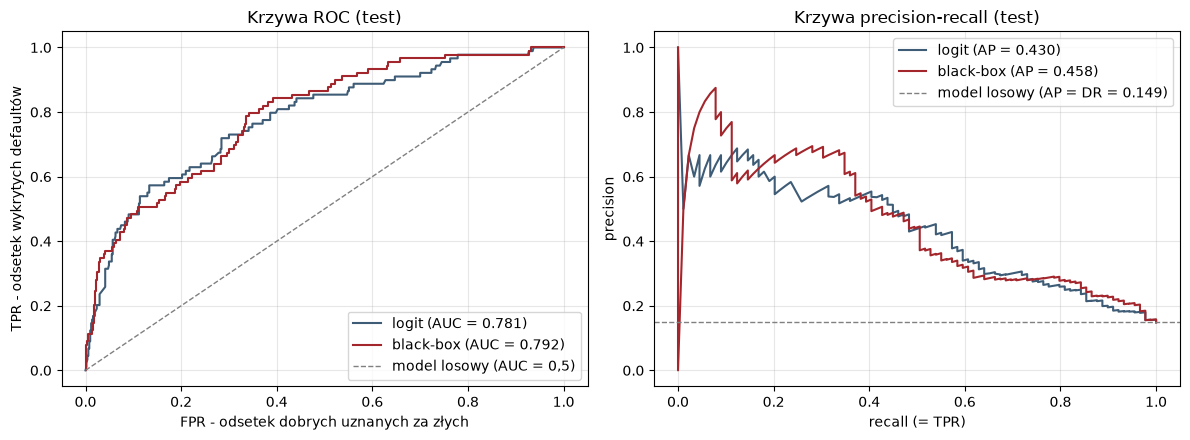

In [28]:
porownanie = pd.DataFrame({f"{m} ({s})": metryki(Y[s], P[m][s]) for s in ["valid", "test"] for m in ["logit", "black-box"]}).T
display(porownanie.drop(columns=["n", "DR"]).round(4))

def bootstrap_roznica_gini(y, p_a, p_b, B=1000, seed=RNG_SEED):     # z Lab 3
    rng = np.random.default_rng(seed); d = []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        d.append(2 * (roc_auc_score(y[i], p_b[i]) - roc_auc_score(y[i], p_a[i])))
    return float(np.mean(d)), np.percentile(d, [2.5, 97.5])

def bootstrap_ci(y, p, B=1000, seed=RNG_SEED):                     # z Lab 3
    rng = np.random.default_rng(seed); w = {"AUC": [], "PR-AUC": [], "KS": [], "log-loss": []}
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        w["AUC"].append(roc_auc_score(y[i], p[i])); w["PR-AUC"].append(average_precision_score(y[i], p[i]))
        w["KS"].append(ks(y[i], p[i])); w["log-loss"].append(log_loss(y[i], np.clip(p[i], EPS, 1 - EPS)))
    return {f"{k} 95% CI": f"[{np.percentile(v, 2.5):.3f}; {np.percentile(v, 97.5):.3f}]" for k, v in w.items()}

display(pd.DataFrame({f"{m} (test)": bootstrap_ci(y_te, P[m]["test"]) for m in ["logit", "black-box"]}).T)
sr, (lo, hi) = bootstrap_roznica_gini(y_te, P["logit"]["test"], P["black-box"]["test"])
print(f"Różnica Gini (black-box - logit) na teście: {sr:+.4f}, 95% przedział bootstrap (sparowany): [{lo:+.4f}; {hi:+.4f}]")
sr_v, (lo_v, hi_v) = bootstrap_roznica_gini(y_va, P["logit"]["valid"], P["black-box"]["valid"])
print(f"Różnica Gini (black-box - logit) na valid:  {sr_v:+.4f}, 95% przedział bootstrap (sparowany): [{lo_v:+.4f}; {hi_v:+.4f}]")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))                  # z Lab 3
for m in ["logit", "black-box"]:
    fpr, tpr, _ = roc_curve(y_te, P[m]["test"])
    axes[0].plot(fpr, tpr, color=KOL[m], label=f"{m} (AUC = {roc_auc_score(y_te, P[m]['test']):.3f})")
    prec, rec, _ = precision_recall_curve(y_te, P[m]["test"])
    axes[1].plot(rec, prec, color=KOL[m], label=f"{m} (AP = {average_precision_score(y_te, P[m]['test']):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray", lw=1, label="model losowy (AUC = 0,5)")
axes[1].axhline(y_te.mean(), ls="--", color="gray", lw=1, label=f"model losowy (AP = DR = {y_te.mean():.3f})")
axes[0].set_xlabel("FPR - odsetek dobrych uznanych za złych"); axes[0].set_ylabel("TPR - odsetek wykrytych defaultów"); axes[0].set_title("Krzywa ROC (test)")
axes[1].set_xlabel("recall (= TPR)"); axes[1].set_ylabel("precision"); axes[1].set_title("Krzywa precision-recall (test)")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("wykresy/roc_pr_test.png", dpi=120); plt.show()

**Wnioski:** black-box ma wyższy Gini: +0,072 na valid (0,667 vs 0,594) i +0,021 na teście (0,583 vs 0,562), nieco niższy log-loss
(0,347 vs 0,350) i Brier (0,104 vs 0,105) na teście. Sparowany przedział bootstrap różnicy Gini na teście obejmuje zero
([-0,048; +0,089]), na valid nie ([+0,019; +0,120]) - **przewaga black-boxa jest niewielka i niepewna**: wyraźna na jednej próbie,
w granicach niepewności na drugiej. Przy DR ≈ 15% losowy model ma PR-AUC ≈ 0,15; modele mają 0,43 (karta) i 0,46 (black-box).

### 6.3 Stabilność obu modeli w 5-krotnej CV (wariancja metryk)

,średnia,odch. std.,min,max
logit: Gini,0.5456,0.1053,0.4333,0.6595
logit: KS,0.4470,0.0940,0.3358,0.5670
logit: PR-AUC,0.4032,0.0770,0.3225,0.5138
logit: log-loss,0.3585,0.0310,0.3233,0.3981
logit: Brier,0.1097,0.0095,0.0971,0.1210
black-box: Gini,0.5810,0.0826,0.4904,0.6579
black-box: KS,0.4812,0.0693,0.4013,0.5457
black-box: PR-AUC,0.4163,0.0730,0.3332,0.5199
black-box: log-loss,0.3502,0.0263,0.3218,0.3807
black-box: Brier,0.1080,0.0085,0.0966,0.1174


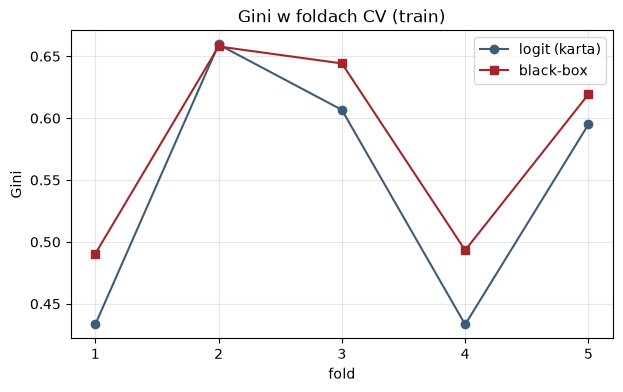

In [29]:
cv_bb, _ = metryki_cv(lambda: model_black_box(**PARAM_BB), FEATURES)
stab = pd.DataFrame({f"{m}: {c}": {"średnia": t[c].mean(), "odch. std.": t[c].std(), "min": t[c].min(), "max": t[c].max()}
                     for m, t in [("logit", cv_logit), ("black-box", cv_bb)] for c in ["Gini", "KS", "PR-AUC", "log-loss", "Brier"]}).T
display(stab.round(4))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cv_logit.index, cv_logit["Gini"], "o-", color=KOL["logit"], label="logit (karta)")
ax.plot(cv_bb.index, cv_bb["Gini"], "s-", color=KOL["black-box"], label="black-box")
ax.set_xticks(cv_bb.index); ax.set_xlabel("fold"); ax.set_ylabel("Gini"); ax.set_title("Gini w foldach CV (train)"); ax.legend(); ax.grid(alpha=0.3); plt.show()

**Wnioski:** w CV black-box ma średnio Gini wyższy o 0,035 (0,581 vs 0,546) przy nieco mniejszym rozrzucie (odch. std. 0,08 vs 0,11),
niższy log-loss (0,350 vs 0,359) i Brier. Rozrzut między foldami (Gini karty od 0,43 do 0,66) jest kilka razy większy niż różnica
między modelami - różnica jakości jest mała w porównaniu z niepewnością wynikającą z małej liczby defaultów.

### 6.4 Złożoność modeli

In [30]:
booster = black_box.named_steps["clf"].get_booster()
drzewa = booster.trees_to_dataframe()
uzyte = (booster.get_score(importance_type="weight"))
zlozonosc = pd.DataFrame({
    "logit (karta)": {"liczba cech wejściowych": len(CECHY_L), "cechy faktycznie używane": len(CECHY_L),
                      "parametry / drzewa": f"{len(CECHY_L) + 1} współczynników",
                      "przedziały / liście": int(sum(len(woe_l.tables_[c]) for c in CECHY_L)),
                      "monotoniczność": "wymuszona (WoE monotoniczne)"},
    "black-box (XGBoost)": {"liczba cech wejściowych": len(FEATURES), "cechy faktycznie używane": len(uzyte),
                            "parametry / drzewa": f"{drzewa['Tree'].nunique()} drzew, głębokość ≤ {PARAM_BB['max_depth']}",
                            "przedziały / liście": int((drzewa["Feature"] == "Leaf").sum()),
                            "monotoniczność": "brak ograniczeń"}})
display(zlozonosc)

,logit (karta),black-box (XGBoost)
liczba cech wejściowych,8,195
cechy faktycznie używane,8,179
parametry / drzewa,9 współczynników,"800 drzew, głębokość ≤ 5"
przedziały / liście,37,7583
monotoniczność,wymuszona (WoE monotoniczne),brak ograniczeń


## 7. Wyjaśnienia globalne

**Ustawienia (Lab 4):** SHAP liczymy w **log-szansach**. Dla karty - wzór zamknięty φ_j = β_j·(WoE_j(x) - E[WoE_j]),
tło = cały train (model liniowy w przestrzeni WoE, więc to dokładne wartości Shapleya przy niezależnych cechach).
Dla XGBoost - `TreeExplainer`, wariant **`interventional`** z tłem 300 firm z train (wartość bazowa = średnie log-szanse na tle).
Wybieramy wariant interwencyjny (wykład 4), bo przy silnie skorelowanych wskaźnikach (219 par z |ρ| > 0,9) `tree_path_dependent`
przybliża warunkową funkcję wartości z dużym błędem, a wzór zamknięty karty też jest interwencyjny - oba modele wyjaśniamy
tą samą funkcją wartości. Wariant `tree_path_dependent` stosujemy tylko do wartości interakcji SHAP (8.4).
Kolumny one-hot jednej cechy sumujemy do cechy źródłowej.

### 7.1 SHAP: wyliczenie i kontrola addytywności

In [31]:
pre_bb, clf_bb = black_box.named_steps["pre"], black_box.named_steps["clf"]
nazwy_bb = list(pre_bb.get_feature_names_out())

def zrodlo(nazwa):                                            # z Lab 4 (zmienione pod nazwy ColumnTransformer)
    if nazwa.startswith("num__"):
        return nazwa[5:]
    return next(c for c in cat_cols if nazwa.startswith(f"cat__{c}_"))

G_bb = np.array([[float(zrodlo(n) == f) for f in FEATURES] for n in nazwy_bb])     # z Lab 4: macierz grupowania kolumn
TLO_SHAP = pre_bb.transform(X_tr.sample(300, random_state=RNG_SEED))          # tło z train (wykład 4)
explainer = shap.TreeExplainer(clf_bb, data=TLO_SHAP, feature_perturbation="interventional", model_output="raw")
sv_te = explainer(pre_bb.transform(X_te))
PHI_BB = sv_te.values @ G_bb
BAZA_BB = float(np.ravel(sv_te.base_values)[0])
blad_bb = np.abs(BAZA_BB + PHI_BB.sum(axis=1) - _z(P["black-box"]["test"])).max()

W_tlo = woe_l.transform(X_tr[CECHY_L]).mean()
def shap_logit(Xw):
    # wzór zamknięty dla modelu liniowego w przestrzeni WoE (Lab 4, sekcja 3)
    return (woe_l.transform(Xw[CECHY_L]) - W_tlo) * lr_l.coef_.ravel()
PHI_LOG = shap_logit(X_te)
BAZA_LOG = float(lr_l.intercept_[0] + (W_tlo * lr_l.coef_.ravel()).sum())
blad_log = np.abs(BAZA_LOG + PHI_LOG.sum(axis=1) - baseline.decision_function(X_te[CECHY_L])).max()
print(f"Addytywność SHAP (maks. |baza + suma φ - f(x)| na teście): black-box {blad_bb:.1e}, karta {blad_log:.1e}")
print(f"Wartość bazowa φ₀ (log-szanse): black-box {BAZA_BB:+.3f}, karta {BAZA_LOG:+.3f} - σ(φ₀) nie jest średnim PD (wykład 4); "
      f"średnie PD na tle / train: {P['black-box']['train'].mean():.1%}")

Addytywność SHAP (maks. |baza + suma φ - f(x)| na teście): black-box 5.2e-06, karta 1.8e-15
Wartość bazowa φ₀ (log-szanse): black-box -2.562, karta -2.215 - σ(φ₀) nie jest średnim PD (wykład 4); średnie PD na tle / train: 14.6%


Addytywność jest spełniona z dokładnością numeryczną - suma wkładów odtwarza log-szanse każdej firmy. Wartość bazowa karty
(log-szanse przy średnim WoE) różni się od logitu średniego PD, bo funkcja logistyczna jest nieliniowa.

### 7.2 Ważność cech: SHAP i permutacja

Dwie miary: średnie |SHAP| na teście (wkład do log-szans) i **ważność permutacyjna** na valid (spadek AUC po
przemieszaniu cechy - Lab 1, Lab 3). Permutacja jest agnostyczna, więc liczymy ją dla obu modeli tą samą metodą.

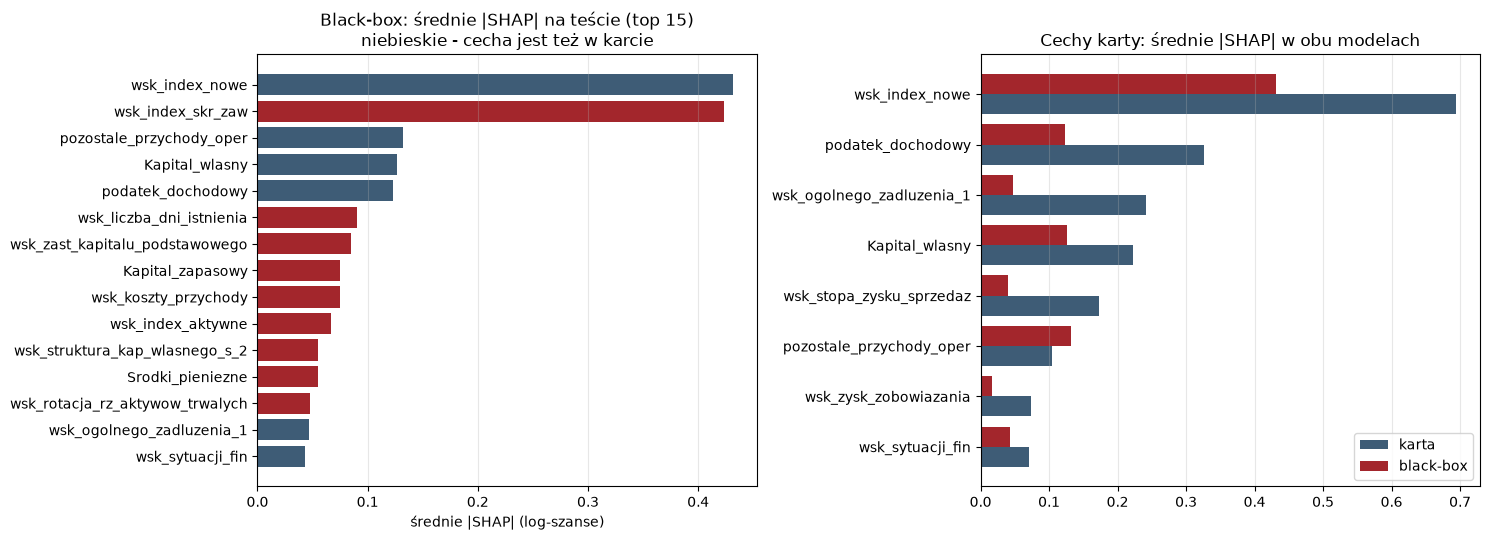

,|SHAP| black-box,ranga SHAP bb,permutacja bb (spadek AUC),± odch. std.,ranga perm. bb
wsk_index_nowe,0.4317,1,0.0404,0.0051,2
wsk_index_skr_zaw,0.4236,2,0.0503,0.0090,1
pozostale_przychody_oper,0.1317,3,-0.0015,0.0020,193
Kapital_wlasny,0.1266,4,-0.0004,0.0023,166
podatek_dochodowy,0.1229,5,0.0028,0.0031,6
wsk_liczba_dni_istnienia,0.0903,6,0.0038,0.0040,4
wsk_zast_kapitalu_podstawowego,0.0846,7,0.0010,0.0015,14
Kapital_zapasowy,0.0752,8,-0.0009,0.0008,182
wsk_koszty_przychody,0.0751,9,-0.0022,0.0019,195
wsk_index_aktywne,0.0670,10,0.0075,0.0032,3


Zgodność metod dla black-boxa (Spearman SHAP vs permutacja, wszystkie cechy): 0.14


,|SHAP| karta,permutacja karta,|SHAP| black-box,ranga w black-boxie (z 192)
Kapital_wlasny,0.2221,0.0050,0.1266,4
podatek_dochodowy,0.3261,0.0213,0.1229,5
pozostale_przychody_oper,0.1049,0.0019,0.1317,3
wsk_index_nowe,0.6944,0.1298,0.4317,1
wsk_ogolnego_zadluzenia_1,0.2417,0.0262,0.0469,14
wsk_stopa_zysku_sprzedaz,0.1725,0.0050,0.0396,17
wsk_sytuacji_fin,0.0713,-0.0007,0.0429,15
wsk_zysk_zobowiazania,0.0738,0.0031,0.0169,63


In [32]:
from sklearn.inspection import permutation_importance

waz_shap_bb = pd.Series(np.abs(PHI_BB).mean(axis=0), index=FEATURES).sort_values(ascending=False)
waz_shap_log = np.abs(PHI_LOG).mean().sort_values(ascending=False)
perm_bb = permutation_importance(black_box, X_va, y_va, scoring="roc_auc", n_repeats=5, random_state=RNG_SEED)   # z Lab 6 (2.1)
perm_log = permutation_importance(baseline, X_va[CECHY_L], y_va, scoring="roc_auc", n_repeats=20, random_state=RNG_SEED)
waz_perm_bb = pd.Series(perm_bb.importances_mean, index=FEATURES)
waz_perm_log = pd.Series(perm_log.importances_mean, index=CECHY_L)

TOP_BB = waz_shap_bb.index[:15].tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
t = waz_shap_bb[TOP_BB][::-1]
axes[0].barh(t.index, t.values, color=[KOL["logit"] if c in CECHY_L else KOL["black-box"] for c in t.index])
axes[0].set_title("Black-box: średnie |SHAP| na teście (top 15)\nniebieskie - cecha jest też w karcie"); axes[0].set_xlabel("średnie |SHAP| (log-szanse)")
t2 = pd.DataFrame({"karta: |SHAP|": waz_shap_log, "black-box: |SHAP| tej cechy": waz_shap_bb[CECHY_L]}).sort_values("karta: |SHAP|")
yy = np.arange(len(t2))
axes[1].barh(yy - 0.2, t2["karta: |SHAP|"], 0.4, color=KOL["logit"], label="karta")
axes[1].barh(yy + 0.2, t2["black-box: |SHAP| tej cechy"], 0.4, color=KOL["black-box"], label="black-box")
axes[1].set_yticks(yy); axes[1].set_yticklabels(t2.index); axes[1].legend(); axes[1].set_title("Cechy karty: średnie |SHAP| w obu modelach")
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig("wykresy/shap_waznosc.png", dpi=120); plt.show()

ranking = pd.DataFrame({"|SHAP| black-box": waz_shap_bb, "ranga SHAP bb": waz_shap_bb.rank(ascending=False).astype(int),
                        "permutacja bb (spadek AUC)": waz_perm_bb, "± odch. std.": pd.Series(perm_bb.importances_std, index=FEATURES), "ranga perm. bb": waz_perm_bb.rank(ascending=False).astype(int)})
display(ranking.sort_values("|SHAP| black-box", ascending=False).head(15).round(4))
print(f"Zgodność metod dla black-boxa (Spearman SHAP vs permutacja, wszystkie cechy): {spearmanr(waz_shap_bb, waz_perm_bb[waz_shap_bb.index])[0]:.2f}")
display(pd.DataFrame({"|SHAP| karta": waz_shap_log, "permutacja karta": waz_perm_log, "|SHAP| black-box": waz_shap_bb[CECHY_L],
                      "ranga w black-boxie (z 192)": waz_shap_bb.rank(ascending=False)[CECHY_L].astype(int)}).round(4))

**Wnioski:**
- Dwie najważniejsze cechy black-boxa według SHAP to wskaźniki branżowe `wsk_index_nowe` i `wsk_index_skr_zaw` (średnie |SHAP|
  ok. 0,43 - ponad 3 razy więcej niż kolejna cecha); są też na 1.-2. miejscu w ważności permutacyjnej. Kolejne trzy
  (`pozostale_przychody_oper`, `Kapital_wlasny`, `podatek_dochodowy`) są w karcie. `wsk_ogolnego_zadluzenia_1` jest dopiero 14.,
  `wsk_sytuacji_fin` 15., `wsk_zysk_zobowiazania` 63. - black-box korzysta z ich skorelowanych odpowiedników.
- W karcie `wsk_index_nowe` odpowiada za ok. 36% sumy |SHAP|. `wsk_index_skr_zaw` nie wszedł do karty (filtr korelacji WoE w 4.2),
  więc jego informację przejmuje częściowo `wsk_index_nowe`.
- Zgodność SHAP i permutacji dla wszystkich cech black-boxa jest niska (ρ ≈ 0,14). Permutacja jednej z kilku skorelowanych cech prawie
  nie zmienia AUC, bo model korzysta z jej „bliźniaków” - ważność permutacyjna zaniża znaczenie skorelowanych cech (np. `Kapital_wlasny`,
  `wsk_koszty_przychody`: wysokie |SHAP|, permutacja ≈ 0). W karcie, gdzie cechy są słabo skorelowane (VIF < 2,2), obie miary
  dają podobny ranking (`wsk_index_nowe`, potem zadłużenie i podatek).

### 7.3 Spójność wyjaśnień black-boxa z kartą

Black-box korzysta ze 192 skorelowanych wskaźników liczbowych (faktycznie używa 179 cech), a karta z 8. Porównanie „cecha do cechy” jest więc niepełne:
SHAP rozdziela wkład między wiele wariantów tej samej miary. Dlatego grupujemy cechy black-boxa **tematycznie**:
do każdej cechy karty przypisujemy cechy black-boxa skorelowane z nią |ρ| ≥ 0,7 (train) i sumujemy ich średnie |SHAP|.

In [33]:
kor_tr = df_train[num_cols].corr(method="spearman")
temat, GRUPY_TEMAT = {}, {}
przypisane = set()
for c in CECHY_L:
    grupa_c = [f for f in num_cols if abs(kor_tr.loc[c, f]) >= 0.7 and f not in przypisane]
    przypisane |= set(grupa_c); GRUPY_TEMAT[c] = grupa_c
    temat[c] = {"cech w grupie": len(grupa_c), "suma |SHAP| grupy (black-box)": waz_shap_bb[grupa_c].sum(),
                "|SHAP| w karcie": waz_shap_log[c]}
reszta = [f for f in FEATURES if f not in przypisane]
GRUPY_TEMAT["pozostałe cechy"] = [f for f in reszta if f in num_cols]
temat["pozostałe cechy"] = {"cech w grupie": len(reszta), "suma |SHAP| grupy (black-box)": waz_shap_bb[reszta].sum(), "|SHAP| w karcie": 0.0}
tab_temat = pd.DataFrame(temat).T
tab_temat["udział w black-boxie"] = tab_temat["suma |SHAP| grupy (black-box)"] / tab_temat["suma |SHAP| grupy (black-box)"].sum()
tab_temat["udział w karcie"] = tab_temat["|SHAP| w karcie"] / tab_temat["|SHAP| w karcie"].sum()
display(tab_temat.round(3))
rho_temat = spearmanr(tab_temat.loc[CECHY_L, "suma |SHAP| grupy (black-box)"], tab_temat.loc[CECHY_L, "|SHAP| w karcie"])[0]
print(f"Korelacja rang ważności grup tematycznych (karta vs black-box): {rho_temat:.2f}")

,cech w grupie,suma |SHAP| grupy (black-box),|SHAP| w karcie,udział w black-boxie,udział w karcie
wsk_index_nowe,1.0,0.432,0.694,0.110,0.364
podatek_dochodowy,2.0,0.135,0.326,0.034,0.171
Kapital_wlasny,8.0,0.306,0.222,0.078,0.116
wsk_ogolnego_zadluzenia_1,17.0,0.325,0.242,0.083,0.127
wsk_zysk_zobowiazania,30.0,0.306,0.074,0.078,0.039
wsk_stopa_zysku_sprzedaz,2.0,0.115,0.173,0.029,0.090
wsk_sytuacji_fin,1.0,0.043,0.071,0.011,0.037
pozostale_przychody_oper,2.0,0.160,0.105,0.041,0.055
pozostałe cechy,132.0,2.115,0.000,0.537,0.000


Korelacja rang ważności grup tematycznych (karta vs black-box): 0.62


**Wnioski:** po zsumowaniu SHAP w grupy tematyczne oba modele opierają się na tych samych obszarach: branża (`wsk_index_nowe`),
zadłużenie, kapitał własny, rentowność, zysk (podatek). Korelacja rang ważności grup wynosi 0,62. W karcie dominuje wskaźnik branżowy
(36% |SHAP|) i podatek (17%); w black-boxie wagi są bardziej rozłożone - największe grupy to `wsk_index_nowe` (11,0%),
zadłużenie (17 wskaźników, 8,3%), kapitał własny i `wsk_zysk_zobowiazania` (po 7,8%). Ponad połowa wkładu black-boxa (54%) pochodzi z cech spoza tematów karty - ok. 1/5
tej reszty to drugi wskaźnik branżowy `wsk_index_skr_zaw` (jego korelacja z `wsk_index_nowe` jest poniżej progu 0,7, więc nie trafił
do grupy), dalej m.in. wiek firmy i kapitał zapasowy. To źródło niewielkiej przewagi black-boxa.

#### 7.3.1 Ważność grup skorelowanych cech: permutacja grupowa i drop-column (Lab 6)

Ważność permutacyjna pojedynczej cechy zaniża znaczenie cech, które mają skorelowanych „bliźniaków” (7.2). Dlatego, jak w Lab 6
(Zadanie 1), mierzymy ważność **całych grup tematycznych** z 7.3 dwiema metodami:
- **permutacja grupowa** - wszystkie cechy grupy mieszamy tą samą permutacją wierszy (valid, 5 powtórzeń) - *czy model z grupy korzysta?*,
- **drop-column grupy** - black-box uczony od nowa bez całej grupy, z tymi samymi hiperparametrami - *czy informację grupy da się zastąpić?*

i porównujemy z sumą ważności permutacyjnych pojedynczych cech. MDI nie liczymy: jest liczone na danych uczących i premiuje
cechy ciągłe o wielu punktach podziału (Lab 6, 2.2), więc przy 190 wskaźnikach ciągłych byłoby obciążone.

In [34]:
AUC_VA_BB = roc_auc_score(y_va, P["black-box"]["valid"])

def perm_grupy(grupa, n_rep=5, seed=RNG_SEED):                # z Lab 6 (Zadanie 1): ta sama permutacja dla całej grupy
    rng = np.random.default_rng(seed); auc = []
    for _ in range(n_rep):
        Xp = X_va.copy()
        Xp[grupa] = X_va[grupa].to_numpy()[rng.permutation(len(X_va))]
        auc.append(roc_auc_score(y_va, black_box.predict_proba(Xp)[:, 1]))
    return AUC_VA_BB - np.mean(auc), np.std(auc)

def drop_column(usun):                                        # z Lab 6 (2.3): model uczony od nowa bez cech
    ce = [f for f in num_cols if f not in usun]
    m = model_black_box(num=ce, **PARAM_BB).fit(X_tr, y_tr)
    return AUC_VA_BB - roc_auc_score(y_va, m.predict_proba(X_va)[:, 1])

wiersze = {}
for g, cechy_g in GRUPY_TEMAT.items():
    sr, sd = perm_grupy(cechy_g)
    wiersze[g] = {"cech": len(cechy_g), "permutacja grupy (spadek AUC)": sr, "± odch. std.": sd,
                  "suma permutacji pojedynczych": waz_perm_bb[cechy_g].sum(), "drop-column grupy (spadek AUC)": drop_column(cechy_g),
                  "suma |SHAP| grupy": waz_shap_bb[cechy_g].sum()}
TAB_GRUPY = pd.DataFrame(wiersze).T.sort_values("permutacja grupy (spadek AUC)", ascending=False)
display(TAB_GRUPY.round(4))
print(f"AUC black-boxa na valid: {AUC_VA_BB:.4f} | Spearman rang grup: permutacja vs SHAP = "
      f"{spearmanr(TAB_GRUPY['permutacja grupy (spadek AUC)'], TAB_GRUPY['suma |SHAP| grupy'])[0]:.2f}, "
      f"permutacja vs drop-column = {spearmanr(TAB_GRUPY['permutacja grupy (spadek AUC)'], TAB_GRUPY['drop-column grupy (spadek AUC)'])[0]:.2f}")

,cech,permutacja grupy (spadek AUC),± odch. std.,suma permutacji pojedynczych,drop-column grupy (spadek AUC),suma |SHAP| grupy
pozostałe cechy,129.0,0.0802,0.0121,0.0609,0.0264,2.0749
wsk_index_nowe,1.0,0.0502,0.0118,0.0404,0.0086,0.4317
wsk_ogolnego_zadluzenia_1,17.0,0.0218,0.0025,0.0022,0.0001,0.3253
podatek_dochodowy,2.0,0.0050,0.0027,0.0027,-0.0020,0.1354
wsk_zysk_zobowiazania,30.0,0.0049,0.0038,0.0027,0.0029,0.3056
wsk_sytuacji_fin,1.0,0.0024,0.0014,0.0018,-0.0026,0.0429
Kapital_wlasny,8.0,0.0022,0.0040,0.0024,-0.0023,0.3058
wsk_stopa_zysku_sprzedaz,2.0,0.0006,0.0023,-0.0033,-0.0033,0.1146
pozostale_przychody_oper,2.0,-0.0018,0.0026,-0.0016,-0.0027,0.1596


AUC black-boxa na valid: 0.8334 | Spearman rang grup: permutacja vs SHAP = 0.70, permutacja vs drop-column = 0.92


**Wnioski:**
- Permutacja grupowa i suma |SHAP| dają podobny ranking grup (ρ = 0,70). Największy spadek AUC daje przemieszanie „pozostałych
  cech” (0,080; zawierają `wsk_index_skr_zaw`) i `wsk_index_nowe` (0,050), potem grupa zadłużenia (0,022). Pozostałe grupy - poniżej 0,01.
- **Grupa zadłużenia pokazuje problem bliźniaków:** suma ważności permutacyjnych jej 17 pojedynczych cech to 0,002, a permutacja całej
  grupy - 0,022, ok. 10 razy więcej. Ważność pojedynczych cech nie widzi grupy, z której model wyraźnie korzysta.
- Drop-column daje dużo mniejsze spadki niż permutacja: po usunięciu grupy i ponownym uczeniu AUC spada najwyżej o 0,026 (pozostałe
  cechy) i 0,009 (`wsk_index_nowe`), a po usunięciu zadłużenia praktycznie wcale (0,0001); dla pozostałych grup zmiana mieści się w ±0,005, czyli w szumie jednego
  uczenia. Informację tych grup **da się zastąpić** innymi wskaźnikami - model z nich korzysta, ale ich nie potrzebuje.
  Najtrudniej zastąpić wskaźniki branżowe. Zgodność rang permutacja vs drop-column: ρ = 0,92.

### 7.4 Beeswarm i wykresy zależności SHAP

Wartości cech na wykresie beeswarm i osi X wykresów zależności są **rangami percentylowymi** (wskaźniki mają skrajne ogony).

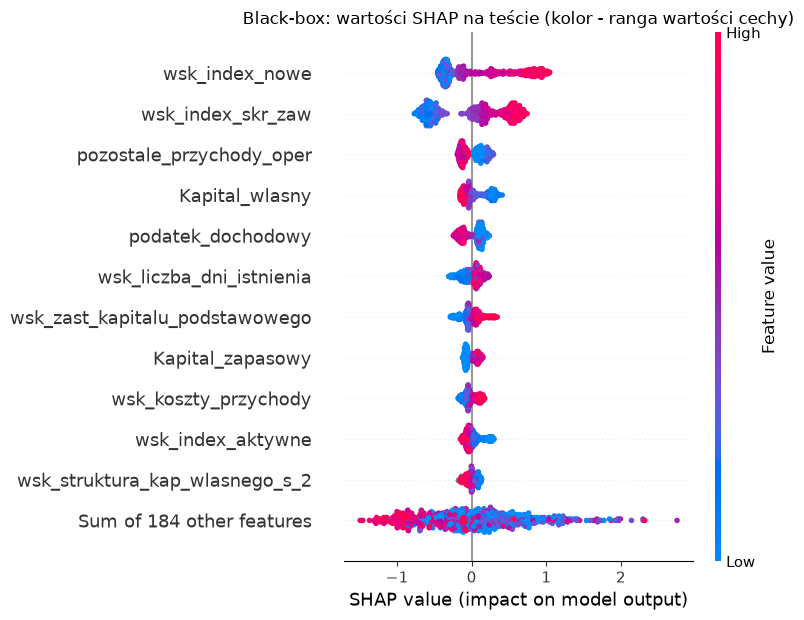

In [35]:
kolor_dane = X_te[num_cols].rank(pct=True).reindex(columns=FEATURES)
E_bb = shap.Explanation(values=PHI_BB, base_values=np.full(len(PHI_BB), BAZA_BB),
                        data=kolor_dane.to_numpy(dtype=float), feature_names=FEATURES)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    shap.plots.beeswarm(E_bb, max_display=12, show=False)
plt.title("Black-box: wartości SHAP na teście (kolor - ranga wartości cechy)"); plt.tight_layout()
plt.savefig("wykresy/shap_beeswarm.png", dpi=120, bbox_inches="tight"); plt.show()

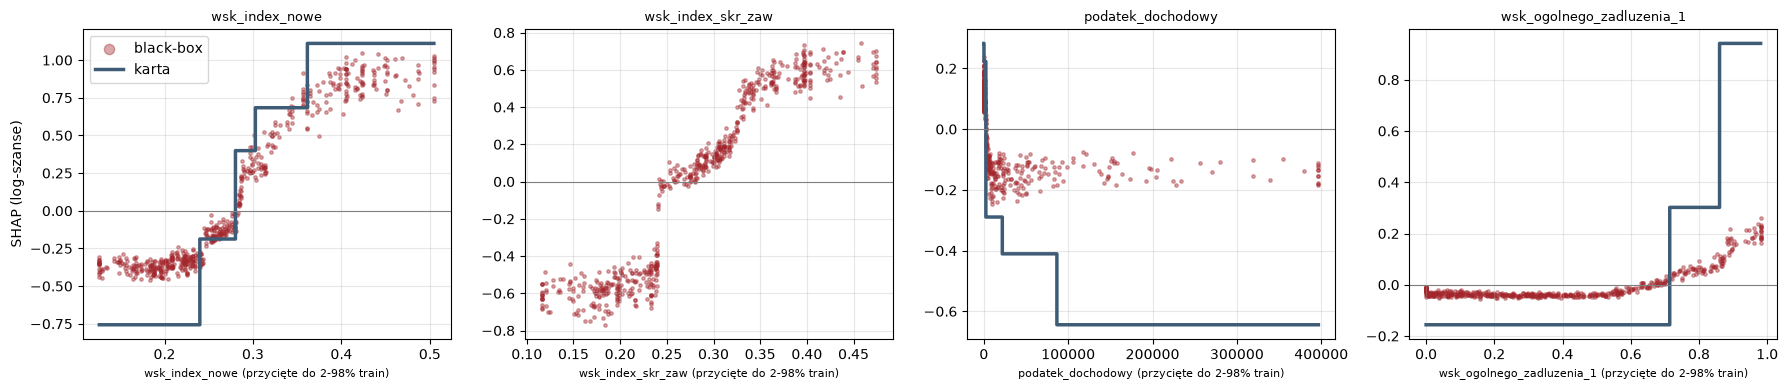

In [36]:
CECHY_DEP = [c for c in TOP_BB if c in num_cols][:2] + [c for c in waz_shap_log.index if c not in TOP_BB[:2]][:2]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, CECHY_DEP):
    j = FEATURES.index(c); xv = X_te[c].to_numpy()
    lo, hi = np.nanpercentile(X_tr[c], [2, 98])
    ax.scatter(np.clip(xv, lo, hi), PHI_BB[:, j], s=6, alpha=0.4, color=KOL["black-box"], label="black-box")
    if c in CECHY_L:
        o = np.argsort(xv)
        ax.step(np.clip(xv[o], lo, hi), PHI_LOG[c].to_numpy()[o], color=KOL["logit"], lw=2.5, where="post", label="karta")
    ax.axhline(0, color="gray", lw=0.8); ax.set_title(c, fontsize=9); ax.set_xlabel(f"{c} (przycięte do 2-98% train)", fontsize=8); ax.grid(alpha=0.3)
axes[0].set_ylabel("SHAP (log-szanse)"); axes[0].legend(markerscale=3)
plt.tight_layout(); plt.savefig("wykresy/shap_zaleznosc.png", dpi=120); plt.show()

**Wnioski:** zależności black-boxa mają ten sam kierunek co schodki karty: wyższe `wsk_index_nowe` i `wsk_index_skr_zaw` podnoszą
ryzyko (wzrost od ok. 0,24 do 0,35-0,4, wkład zmienia się łącznie o ok. 1,2-1,3 log-szansy), dodatni podatek dochodowy je obniża, a zadłużenie
ogólne powyżej ok. 0,6-0,7 podnosi. Różnice: dla podatku black-box odróżnia praktycznie tylko „podatek zerowy” od „dodatniego”, a karta
stopniuje wkład aż do ok. 85 tys. zł; dla zadłużenia wkład black-boxa jest wielokrotnie mniejszy (ok. +0,2 vs +0,9 log-szans w karcie),
bo dzieli go między 17 skorelowanych wskaźników zadłużenia (7.3.1). Pionowy rozrzut punktów przy tej samej wartości cechy jest mały -
interakcje są słabe (8.4).

## 8. Kształt zależności: PDP, ICE, ALE (Lab 5)

Wszystkie krzywe w **log-szansach**, na próbie firm z testu (`XS`), siatka - kwantyle 2-98% z train (bez ekstrapolacji).
Funkcje `pdp`, `ice`, `ale`, `pdp_wysrodkowane` z Lab 5. Dla cech, których nie ma w karcie, krzywa karty jest płaska.

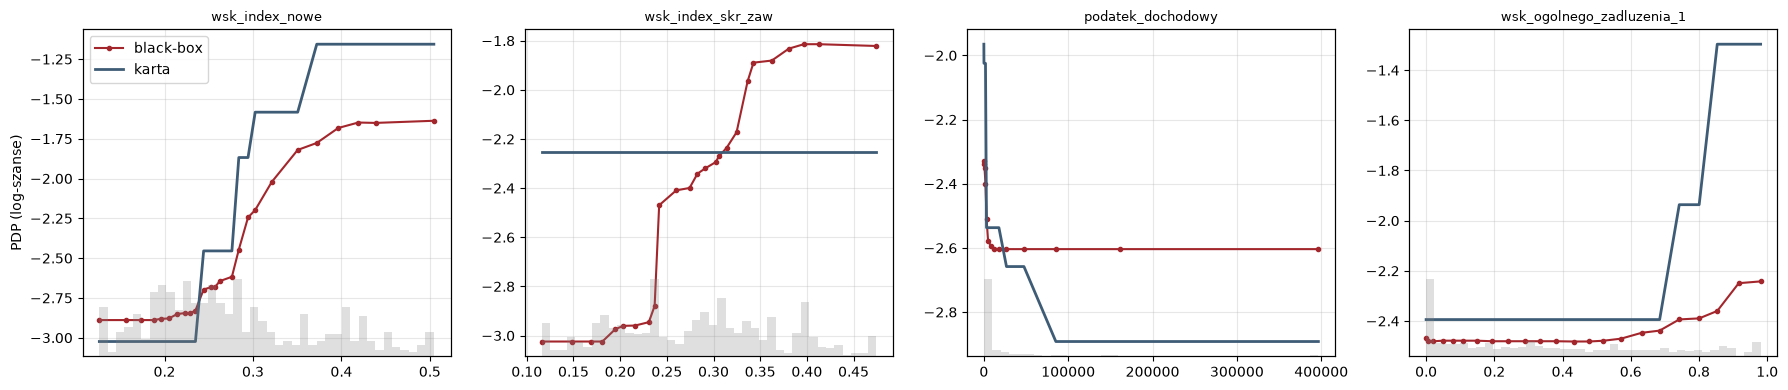

In [37]:
def log_szanse(model, cechy=None):                            # z Lab 4
    return lambda Xw: _z(model.predict_proba(Xw if cechy is None else Xw[cechy])[:, 1])

f_bb, f_lg = log_szanse(black_box), log_szanse(baseline, CECHY_L)
XS = X_te.reset_index(drop=True)

def siatka_kwantyli(cecha, n=25, lo=0.02, hi=0.98):          # z Lab 5
    return np.unique(np.quantile(X_tr[cecha].dropna(), np.linspace(lo, hi, n)))

def pdp(f, X, cecha, siatka):                                 # z Lab 5
    """PDP z definicji: wartość z siatki podstawiamy wszystkim firmom i uśredniamy prognozę."""
    wynik = []
    for v in siatka:
        Xv = X.copy(); Xv[cecha] = v
        wynik.append(np.mean(f(Xv)))
    return np.array(wynik)

def ice(f, X, cecha, siatka):                                 # z Lab 5
    """Macierz ICE (firmy × siatka): prognoza każdej firmy dla każdej wartości cechy."""
    duze = pd.concat([X.assign(**{cecha: v}) for v in siatka], ignore_index=True)
    return np.asarray(f(duze)).reshape(len(siatka), len(X)).T

def ale(f, X, cecha, K=20):                                   # z Lab 5
    """ALE pierwszego rzędu z definicji."""
    x = X[cecha].to_numpy(dtype=float); ok = ~np.isnan(x)
    granice = np.unique(np.quantile(x[ok], np.linspace(0, 1, K + 1)))
    k = np.clip(np.searchsorted(granice, x[ok], side="left") - 1, 0, len(granice) - 2)
    Xd, Xg = X.loc[ok].copy(), X.loc[ok].copy()
    Xd[cecha], Xg[cecha] = granice[k], granice[k + 1]
    roznice = f(Xg) - f(Xd)
    n_k = np.bincount(k, minlength=len(granice) - 1)
    efekt = np.bincount(k, weights=roznice, minlength=len(granice) - 1) / np.maximum(n_k, 1)
    a = np.concatenate([[0.0], np.cumsum(efekt)])
    a -= np.sum((a[:-1] + a[1:]) / 2 * n_k) / n_k.sum()
    return granice, a, n_k

def pdp_wysrodkowane(f, X, cecha, siatka):                    # z Lab 5
    p = pdp(f, X, cecha, siatka)
    return p - np.interp(X[cecha].dropna(), siatka, p).mean()

CECHY_PDP = CECHY_DEP
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, CECHY_PDP):
    s = siatka_kwantyli(c)
    ax.plot(s, pdp(f_bb, XS, c, s), "o-", ms=3, color=KOL["black-box"], label="black-box")
    ax.plot(s, pdp(f_lg, XS, c, s), "-", lw=2, color=KOL["logit"], label="karta")
    ax2 = ax.twinx(); ax2.hist(XS[c].dropna().clip(s.min(), s.max()), bins=40, color="gray", alpha=0.25)
    ax2.set_yticks([]); ax2.set_ylim(0, ax2.get_ylim()[1] * 4)
    ax.set_title(c, fontsize=9); ax.grid(alpha=0.3)
axes[0].set_ylabel("PDP (log-szanse)"); axes[0].legend()
plt.tight_layout(); plt.savefig("wykresy/pdp.png", dpi=120); plt.show()

**Wnioski:** PDP black-boxa i karty mają zgodne kierunki dla wszystkich czterech cech. Dla wskaźników branżowych black-box ma wyraźny
próg ok. 0,24-0,25 i nasycenie powyżej ok. 0,35-0,4 (efekt ok. 1,2 log-szansy); karta ma podobne schodki dla `wsk_index_nowe`, a dla
`wsk_index_skr_zaw`, którego nie zawiera, krzywą płaską. Dla podatku black-box reaguje tylko na przejście przez zero, karta - schodkowo
do ok. 85 tys. zł. Dla zadłużenia oba modele pokazują wzrost powyżej ok. 0,6-0,7 (bliskie zera kapitały własne), ale w black-boxie efekt tej
jednej cechy jest mały, bo rozkłada się na skorelowane wskaźniki zadłużenia.

### 8.1 ICE i c-ICE - czy wszystkie firmy reagują tak samo?

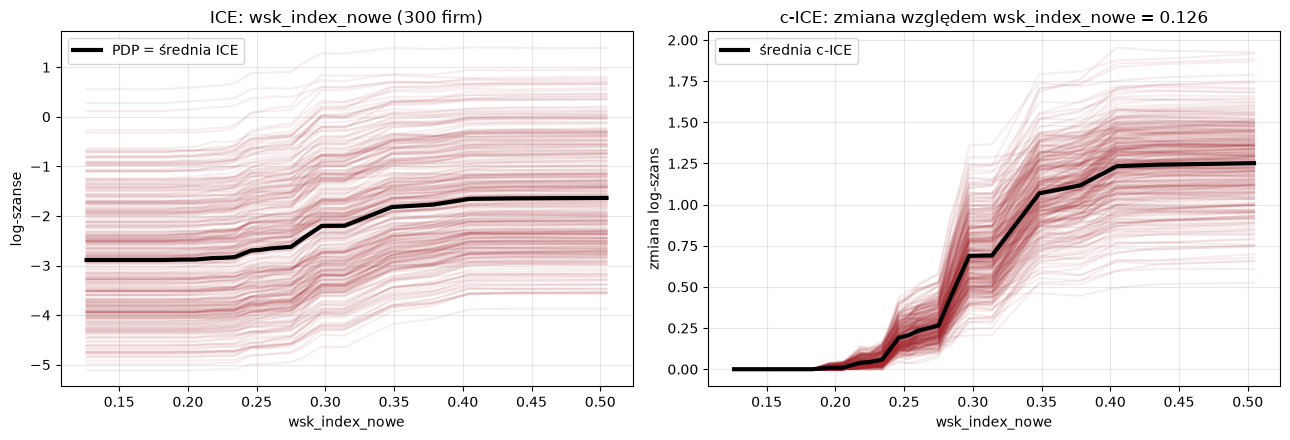

Zmiana wsk_index_nowe z 0.126 do 0.505: średnio +1.252 log-szans; 10% firm: < +0.920, 10% firm: > +1.560
   wielkość = mikro    : średni efekt +1.235 (n = 174)
   wielkość = mała     : średni efekt +1.167 (n = 100)
   wielkość = pozostałe: średni efekt +1.287 (n = 325)


In [38]:
c_ice = CECHY_PDP[0]
S_ICE = siatka_kwantyli(c_ice, n=20)
ICE_M = ice(f_bb, XS, c_ice, S_ICE)
C_ICE = ICE_M - ICE_M[:, [0]]                                 # c-ICE: punkt odniesienia = najniższa wartość z siatki
pokaz = np.random.default_rng(RNG_SEED).choice(len(XS), 300, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(S_ICE, ICE_M[pokaz].T, color=KOL["black-box"], alpha=0.08); axes[0].plot(S_ICE, ICE_M.mean(axis=0), color="black", lw=3, label="PDP = średnia ICE")
axes[0].set_title(f"ICE: {c_ice} (300 firm)"); axes[0].set_ylabel("log-szanse")
axes[1].plot(S_ICE, C_ICE[pokaz].T, color=KOL["black-box"], alpha=0.08); axes[1].plot(S_ICE, C_ICE.mean(axis=0), color="black", lw=3, label="średnia c-ICE")
axes[1].set_title(f"c-ICE: zmiana względem {c_ice} = {S_ICE[0]:.3g}"); axes[1].set_ylabel("zmiana log-szans")
for ax in axes:
    ax.set_xlabel(c_ice); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("wykresy/ice.png", dpi=120); plt.show()
EFEKT = C_ICE[:, -1]
print(f"Zmiana {c_ice} z {S_ICE[0]:.3g} do {S_ICE[-1]:.3g}: średnio {EFEKT.mean():+.3f} log-szans; "
      f"10% firm: < {np.percentile(EFEKT, 10):+.3f}, 10% firm: > {np.percentile(EFEKT, 90):+.3f}")
for nazwa, maska in [("mikro", XS["wielkosc"] == "mikro"), ("mała", XS["wielkosc"] == "mała"), ("pozostałe", XS["wielkosc"] == "pozostałe")]:
    print(f"   wielkość = {nazwa:9s}: średni efekt {EFEKT[maska.to_numpy()].mean():+.3f} (n = {maska.sum()})")

**Wnioski:** c-ICE dla `wsk_index_nowe` (zmiana z 0,13 do 0,51): średnio +1,25 log-szans (szanse defaultu rosną ok. 3,5 raza), dla 80%
firm efekt mieści się między +0,92 a +1,56. Krzywe ICE są prawie równoległe, a średni efekt jest niemal taki sam dla firm mikro (+1,24),
małych (+1,17) i pozostałych (+1,29) - wpływ branży na ryzyko jest w black-boxie prawie addytywny, czyli taki, jaki zakłada karta
(jeden współczynnik na cechę). Słabe interakcje potwierdza statystyka H (8.4).

### 8.2 PDP a ALE przy skorelowanych cechach

PDP podstawia wartość cechy wszystkim firmom, także tam, gdzie takich kombinacji nie ma w danych (cechy są silnie
skorelowane - 3.3). ALE liczy efekty lokalnie, w obrębie przedziałów cechy. Duża różnica PDP - ALE ostrzega, że PDP
ekstrapoluje.

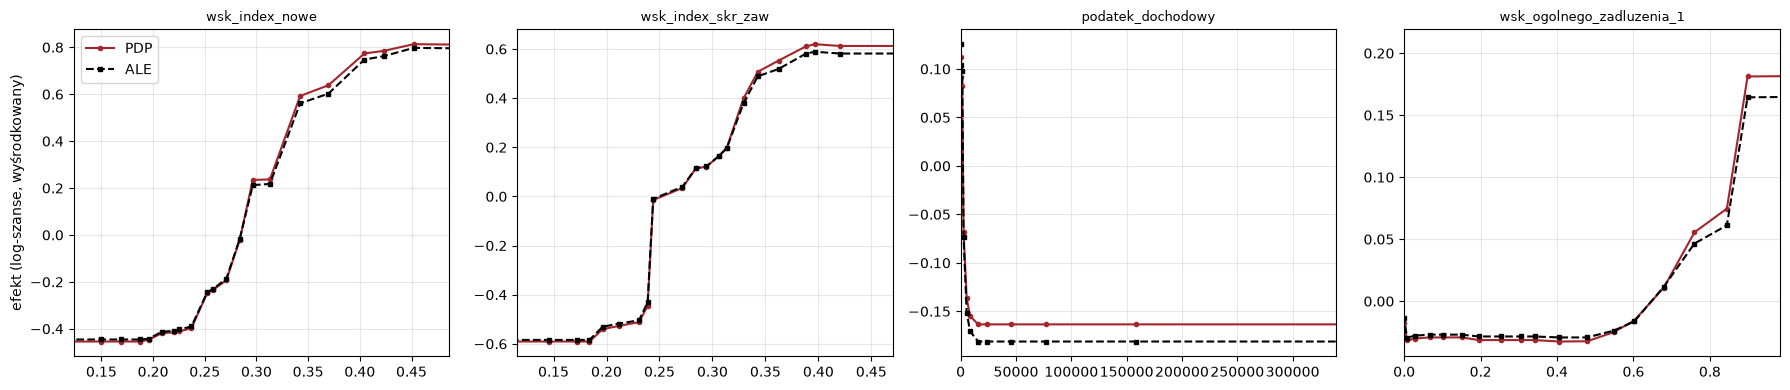

,zakres ALE,maks. |PDP - ALE|,min. liczność przedziału ALE,maks. |ρ| z inną cechą,różnica / zakres
wsk_index_nowe,1.243,0.036,25.0,0.653,0.029
wsk_index_skr_zaw,1.173,0.034,25.0,0.653,0.029
podatek_dochodowy,0.307,0.018,28.0,0.714,0.058
wsk_ogolnego_zadluzenia_1,0.194,0.017,20.0,0.996,0.087


In [39]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4)); roznice = {}
for ax, c in zip(axes, CECHY_PDP):
    gr, a, n_k = ale(f_bb, XS, c, K=20)                      # wykład 5: K = 20-50
    p = pdp_wysrodkowane(f_bb, XS, c, gr)
    ax.plot(gr, p, "o-", ms=3, color=KOL["black-box"], label="PDP"); ax.plot(gr, a, "s--", ms=3, color="black", label="ALE")
    ax.set_xlim(np.nanpercentile(XS[c], [2, 98])); ax.set_title(c, fontsize=9); ax.grid(alpha=0.3)
    w = (gr >= np.nanpercentile(XS[c], 2)) & (gr <= np.nanpercentile(XS[c], 98))
    roznice[c] = {"zakres ALE": np.ptp(a[w]), "maks. |PDP - ALE|": np.abs(p - a)[w].max(),
                  "min. liczność przedziału ALE": int(n_k.min()), "maks. |ρ| z inną cechą": kor_tr.loc[c].drop(c).abs().max() if c in kor_tr else np.nan}
axes[0].set_ylabel("efekt (log-szanse, wyśrodkowany)"); axes[0].legend()
plt.tight_layout(); plt.savefig("wykresy/pdp_ale.png", dpi=120); plt.show()
display(pd.DataFrame(roznice).T.assign(**{"różnica / zakres": lambda t: t["maks. |PDP - ALE|"] / t["zakres ALE"]}).round(3))

**Wnioski:** różnica PDP - ALE to tylko 3-9% zakresu efektu (największa dla zadłużenia: 8,7%, mimo ρ = 0,996 z innym wskaźnikiem
zadłużenia). PDP nie wprowadza tu w błąd, mimo silnych korelacji - zgodnie z prawie addytywnym modelem (8.1, 8.4). ALE liczymy przy
K = 20 przedziałach; najmniejszy przedział ma 20-28 firm, więc krzywe opierają się na wystarczającej liczbie obserwacji (bez pasma
bootstrap - niepewność krzywych nie jest oszacowana). Zakres efektu: wskaźniki branżowe ok. 1,17-1,24 log-szans, podatek 0,31,
zadłużenie 0,19.

### 8.3 Monotoniczność względem intuicji ekonomicznej

Oczekiwany kierunek zapisujemy **przed** analizą wyników, z wiedzy o finansach firmy: wyższe zadłużenie → wyższe ryzyko,
wyższa rentowność, zysk, kapitał własny i podatek (proxy zysku) → niższe ryzyko. Tabela naruszeń z Lab 5:
jaka część zmienności PDP black-boxa idzie w kierunku przeciwnym do oczekiwanego.

In [40]:
EKONOMIA = {"podatek_dochodowy": -1, "Kapital_wlasny": -1, "wsk_ogolnego_zadluzenia_1": +1, "wsk_zysk_zobowiazania": -1,
              "wsk_stopa_zysku_sprzedaz": -1, "wsk_sytuacji_fin": -1, "pozostale_przychody_oper": -1, "wsk_index_skr_zaw": +1, "wsk_index_nowe": +1}   # kierunki z ekonomii / EDA (3.1)
OCZEKIWANY = {c: EKONOMIA.get(c, int(np.sign(spearmanr(df_train[c], df_train[TARGET], nan_policy="omit")[0])))
              for c in CECHY_L + [c for c in TOP_BB[:6] if c not in CECHY_L and c in num_cols]}

def naruszenia(f, kierunki):                                  # z Lab 5
    w = {}
    for c, kier in kierunki.items():
        s = siatka_kwantyli(c)
        d = np.diff(ice(f, XS, c, s).mean(axis=0)) * kier
        w[c] = {"oczekiwany kierunek": "+" if kier > 0 else "-", "zmienność PDP": np.abs(d).sum(),
                "suma naruszeń": float(np.abs(d[d < 0].sum())), "maks. naruszenie": float(np.abs(min(d.min(), 0.0)))}
    t = pd.DataFrame(w).T
    t["udział naruszeń"] = t["suma naruszeń"].astype(float) / t["zmienność PDP"].astype(float)
    return t

tab_mono = naruszenia(f_bb, OCZEKIWANY)
tab_mono["zgodny znak β w karcie"] = [("tak" if c in CECHY_L else "-") for c in tab_mono.index]
display(tab_mono.round(3))

,oczekiwany kierunek,zmienność PDP,suma naruszeń,maks. naruszenie,udział naruszeń,zgodny znak β w karcie
wsk_index_nowe,+,1.258357,0.003321,0.002392,0.003,tak
podatek_dochodowy,-,0.276159,0.0,0.0,0.000,tak
Kapital_wlasny,-,0.425744,0.004559,0.004559,0.011,tak
wsk_ogolnego_zadluzenia_1,+,0.259481,0.017287,0.013986,0.067,tak
wsk_zysk_zobowiazania,-,0.043168,0.0,0.0,0.000,tak
wsk_stopa_zysku_sprzedaz,-,0.162592,0.003603,0.002971,0.022,tak
wsk_sytuacji_fin,-,0.17479,0.043029,0.014549,0.246,tak
pozostale_przychody_oper,-,0.484637,0.133791,0.098785,0.276,tak
wsk_index_skr_zaw,+,1.217342,0.007195,0.007195,0.006,-
wsk_liczba_dni_istnienia,-,0.346125,0.286002,0.086479,0.826,-


**Wnioski:** dla podatku i `wsk_zysk_zobowiazania` PDP black-boxa jest w pełni monotoniczne, dla wskaźników branżowych
prawie (naruszenia 0,3-0,6% zmienności PDP); dla kapitału własnego i rentowności sprzedaży naruszenia są pomijalne (1-2%). Większe udziały naruszeń
mają zadłużenie (7%), `wsk_sytuacji_fin` (25%) i `pozostale_przychody_oper` (28%), ale ich bezwzględna wielkość jest mała (maks.
0,014-0,015 log-szans dla dwóch pierwszych, 0,099 dla pozostałych przychodów) i dotyczy obszarów o małej liczbie firm. Wyraźnie
narusza oczekiwany kierunek wiek firmy (`wsk_liczba_dni_istnienia`): 83% zmienności jego PDP idzie w stronę wyższego ryzyka starszych
firm (maks. 0,086 log-szans). Nie wprowadzamy
ograniczeń monotonicznych w XGBoost - w karcie monotoniczność jest zagwarantowana binningiem; w modelu wdrożeniowym black-boxa warto ją
wymusić (`monotone_constraints`), przede wszystkim dla `pozostale_przychody_oper` i wieku firmy.

### 8.4 Interakcje: kandydaci z SHAP, weryfikacja statystyką H (Lab 4, Lab 6)

Rozrzut c-ICE (8.1) i wykresów zależności SHAP (7.4) to tylko **hipoteza** interakcji. Kandydatów wybieramy z wartości interakcji
SHAP (`shap_interaction_values`, Lab 4; wymagają wariantu `tree_path_dependent`) na 300 firmach z testu - 4 pary o największej
średniej |interakcji|. Każdą parę **weryfikujemy statystyką H Friedmana** (`h_statistic` z Lab 6) w log-szansach, na **dwóch
niezależnych próbach** po 150 firm, razem z **parą kontrolną**: dwiema ważnymi cechami black-boxa o najmniejszej interakcji SHAP -
jej H pokazuje poziom szumu metody. H jest miarą względną: `h_statistic` zwraca pierwiastek, a udział interakcji w wariancji wspólnej funkcji
częściowej zależności to H²; RMS - miarą bezwzględną (log-szanse).

In [41]:
def h_statistic(f, X, j, k):                                  # z Lab 6 (3)
    """H Friedmana dla pary (j, k): wycentrowane funkcje częściowej zależności liczone w punktach próby X."""
    n, Xr = len(X), X.reset_index(drop=True)
    duza = pd.concat([Xr] * n, ignore_index=True)
    def czesciowa(cechy):
        B = duza.copy()
        for c in cechy:
            B[c] = np.repeat(Xr[c].to_numpy(), n)
        v = np.asarray(f(B)).reshape(n, n).mean(axis=1)
        return v - v.mean()
    pjk, pj, pk = czesciowa([j, k]), czesciowa([j]), czesciowa([k])
    reszta = pjk - pj - pk
    return float(np.sqrt(np.sum(reszta ** 2) / np.sum(pjk ** 2))), float(np.sqrt(np.mean(reszta ** 2)))

idx_int = np.random.default_rng(RNG_SEED).choice(len(X_te), 300, replace=False)        # z Lab 4: interakcje SHAP
IV = np.einsum("nij,ia,jb->nab", shap.TreeExplainer(clf_bb).shap_interaction_values(pre_bb.transform(X_te.iloc[idx_int])), G_bb, G_bb)
SILA_INT = pd.DataFrame(2 * np.abs(IV).mean(axis=0), index=FEATURES, columns=FEATURES)
gorne_int = SILA_INT.where(np.triu(np.ones(SILA_INT.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
PARY_H = list(gorne_int.index[:4])
top10 = [c for c in TOP_BB if c in num_cols][:10]
kontrolna = min(itertools.combinations(top10, 2), key=lambda p: SILA_INT.loc[p[0], p[1]])
PARY_H.append(kontrolna)

wiersze = []
for a, b in PARY_H:
    w = {"para": f"{a} × {b}", "rodzaj": "kontrolna" if (a, b) == kontrolna else "kandydat z SHAP",
         "siła interakcji SHAP": SILA_INT.loc[a, b]}
    for s in [1, 2]:
        h, rms = h_statistic(f_bb, X_te.sample(150, random_state=s), a, b)
        w[f"H (próba {s})"], w[f"RMS (próba {s})"] = h, rms
    wiersze.append(w)
TAB_H = pd.DataFrame(wiersze).set_index("para")
display(TAB_H.round(3))

,rodzaj,siła interakcji SHAP,H (próba 1),RMS (próba 1),H (próba 2),RMS (próba 2)
para,,,,,,
wsk_index_nowe × wsk_liczba_dni_istnienia,kandydat z SHAP,0.028,0.061,0.033,0.060,0.030
wsk_index_nowe × podatek_dochodowy,kandydat z SHAP,0.026,0.055,0.030,0.063,0.031
wsk_index_nowe × wsk_sytuacji_fin,kandydat z SHAP,0.026,0.050,0.026,0.053,0.026
wsk_index_skr_zaw × pozostale_przychody_oper,kandydat z SHAP,0.023,0.044,0.023,0.043,0.022
podatek_dochodowy × Kapital_zapasowy,kontrolna,0.000,0.004,0.000,0.003,0.000


**Wnioski:**
- Najsilniejsza interakcja według SHAP to `wsk_index_nowe × wsk_liczba_dni_istnienia`; kolejne dwie pary też zawierają `wsk_index_nowe`
  (z podatkiem i `wsk_sytuacji_fin`), czwarta to `wsk_index_skr_zaw × pozostale_przychody_oper`.
- Statystyka H potwierdza, że te interakcje istnieją: wynik jest powtarzalny na obu próbach (np. 0,061 i 0,060 dla najsilniejszej pary),
  a para kontrolna `podatek_dochodowy × Kapital_zapasowy` ma H = 0,003-0,004, o rząd wielkości mniej - to poziom szumu metody.
- **Interakcje są jednak bardzo słabe:** H ≤ 0,063, czyli interakcja to najwyżej ok. 0,4% wariancji wspólnej funkcji zależności (H²),
  a w liczbach bezwzględnych RMS ≈ 0,02-0,03 log-szans - wobec efektów głównych rzędu 1,2 log-szansy (8.1). Black-box jest w praktyce
  **prawie addytywny**, co tłumaczy, dlaczego addytywna karta niewiele mu ustępuje.

## 9. Wyjaśnienia lokalne: studia przypadków

Cztery firmy z testu, wybrane według PD black-boxa (przed kalibracją PD jest bliskie częstości w próbie, CITL na teście 0,07 - 6.1):
1. **najwyższe PD**, 2. **graniczna** - PD najbliżej progu z funkcji zysku p* = MARGIN / (MARGIN + LGD) = 18,2% (12.2),
3. **typowa przyjęta** - PD najbliżej mediany, 4. **największa niezgodność modeli** - największa różnica rang PD karty i black-boxa.

Dla każdej: wykres kaskadowy SHAP black-boxa, kody przyczyn (top 3), dekompozycja punktów karty i (9.2) LIME.

,wiersz testu,PD black-box,PD karta,punkty karty,default (fakt)
najwyższe PD,102.0,0.803,0.682,465.154,0.0
graniczna (PD ≈ p*),365.0,0.182,0.179,530.998,0.0
typowa przyjęta,449.0,0.072,0.091,553.384,0.0
niezgodność modeli,3.0,0.225,0.034,583.658,1.0



=== najwyższe PD: wiersz 102, PD black-box 80.3%, PD karta 68.2%, default = 0 ===


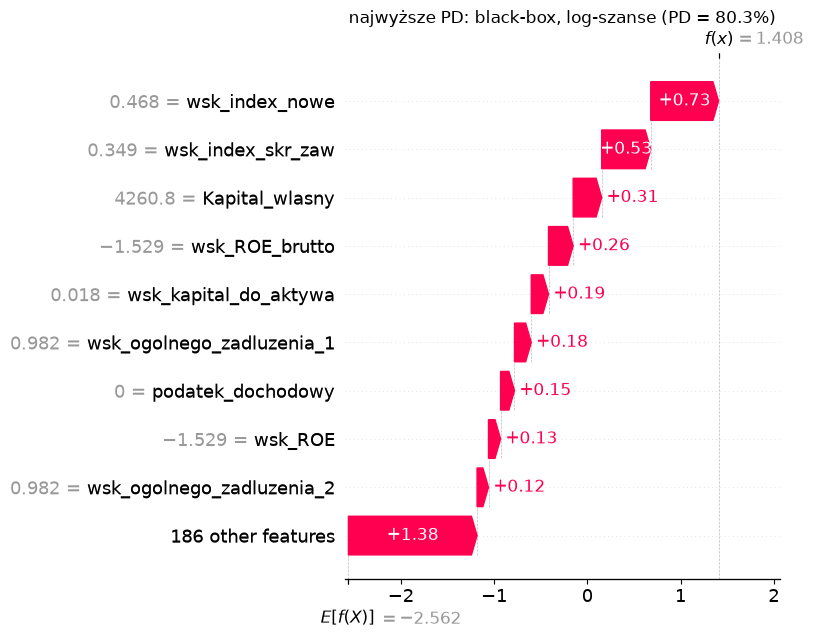

,wartość,SHAP,mnożnik szans e^φ,kierunek
wsk_index_nowe,0.467532,0.727,2.07,podnosi ryzyko
wsk_index_skr_zaw,0.349068,0.526,1.69,podnosi ryzyko
Kapital_wlasny,4260.800000,0.306,1.36,podnosi ryzyko
wsk_ROE_brutto,-1.529365,0.264,1.30,podnosi ryzyko
wsk_kapital_do_aktywa,0.018305,0.185,1.20,podnosi ryzyko
wsk_ogolnego_zadluzenia_1,0.981695,0.180,1.20,podnosi ryzyko


,wartość,punkty,utracone vs maksimum,SHAP karty
wsk_index_nowe,0.467532,41.1,53.9,1.111
wsk_ogolnego_zadluzenia_1,0.981695,41.8,31.7,0.942
podatek_dochodowy,0.0,61.2,26.7,0.282
Kapital_wlasny,4260.8,58.4,21.0,0.356
wsk_stopa_zysku_sprzedaz,-0.019691,65.9,9.7,0.078
pozostale_przychody_oper,0.0,64.5,6.3,0.109
wsk_zysk_zobowiazania,-0.028517,65.5,5.3,0.072
wsk_sytuacji_fin,0.542254,66.8,3.3,0.027



=== graniczna (PD ≈ p*): wiersz 365, PD black-box 18.2%, PD karta 17.9%, default = 0 ===


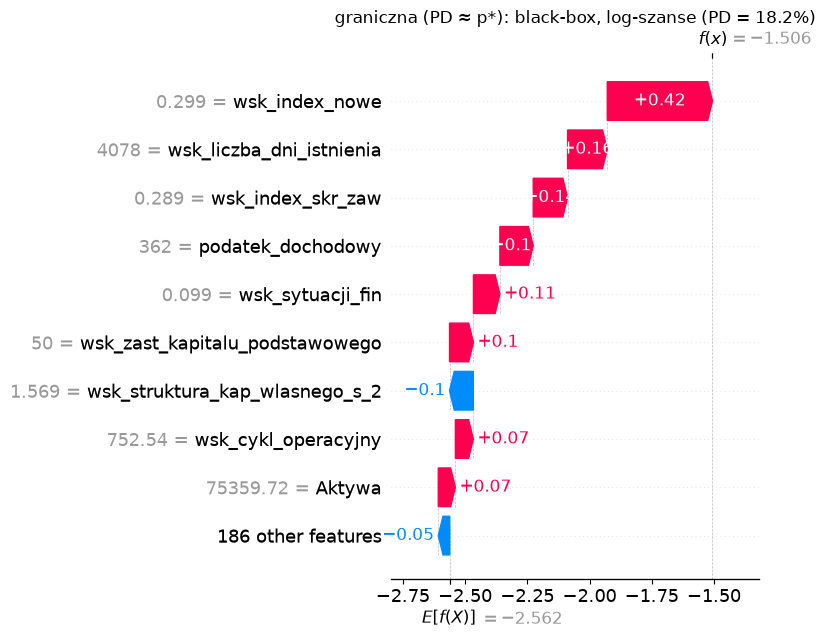

,wartość,SHAP,mnożnik szans e^φ,kierunek
wsk_index_nowe,0.298858,0.423,1.53,podnosi ryzyko
wsk_liczba_dni_istnienia,4078.000000,0.160,1.17,podnosi ryzyko
wsk_index_skr_zaw,0.288732,0.138,1.15,podnosi ryzyko
podatek_dochodowy,362.000000,0.134,1.14,podnosi ryzyko
wsk_sytuacji_fin,0.099198,0.106,1.11,podnosi ryzyko
wsk_zast_kapitalu_podstawowego,50.000000,0.096,1.10,podnosi ryzyko


,wartość,punkty,utracone vs maksimum,SHAP karty
wsk_index_nowe,0.298858,61.6,33.3,0.399
podatek_dochodowy,362.0,63.0,25.0,0.223
Kapital_wlasny,68458.52,65.8,13.6,0.099
pozostale_przychody_oper,0.0,64.5,6.3,0.109
wsk_stopa_zysku_sprzedaz,0.022045,70.3,5.3,-0.074
wsk_zysk_zobowiazania,0.015147,66.3,4.5,0.044
wsk_sytuacji_fin,0.099198,66.1,4.0,0.051
wsk_ogolnego_zadluzenia_1,0.091577,73.5,0.0,-0.156



=== typowa przyjęta: wiersz 449, PD black-box 7.2%, PD karta 9.1%, default = 0 ===


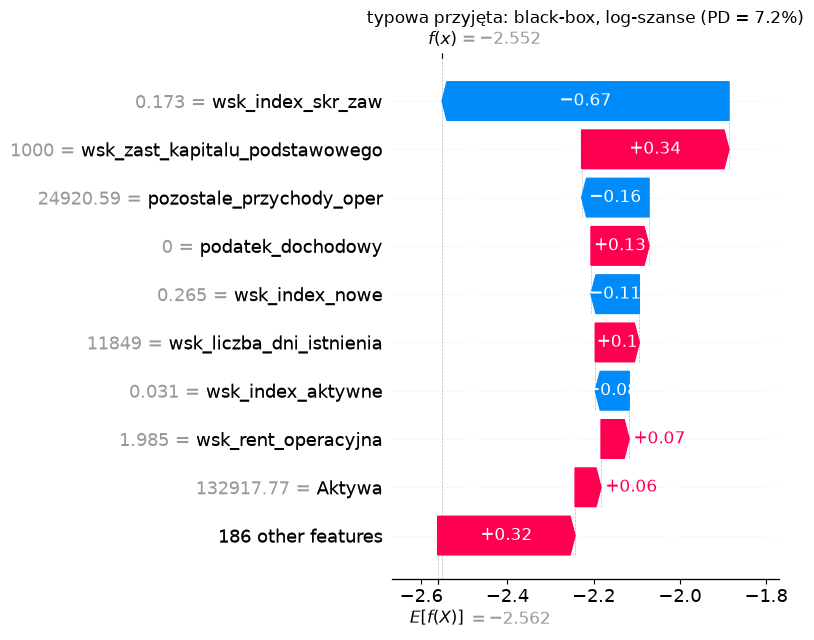

,wartość,SHAP,mnożnik szans e^φ,kierunek
wsk_index_skr_zaw,0.173228,-0.666,0.51,obniża ryzyko
wsk_zast_kapitalu_podstawowego,1000.000000,0.342,1.41,podnosi ryzyko
pozostale_przychody_oper,24920.590000,-0.156,0.86,obniża ryzyko
podatek_dochodowy,0.000000,0.135,1.14,podnosi ryzyko
wsk_index_nowe,0.264516,-0.112,0.89,obniża ryzyko
wsk_liczba_dni_istnienia,11849.000000,0.102,1.11,podnosi ryzyko


,wartość,punkty,utracone vs maksimum,SHAP karty
podatek_dochodowy,0.0,61.2,26.7,0.282
wsk_index_nowe,0.264516,78.5,16.4,-0.187
wsk_stopa_zysku_sprzedaz,-0.141376,65.9,9.7,0.078
Kapital_wlasny,120885.11,71.0,8.4,-0.082
wsk_zysk_zobowiazania,0.0,66.3,4.5,0.044
wsk_sytuacji_fin,0.100464,66.1,4.0,0.051
wsk_ogolnego_zadluzenia_1,0.090527,73.5,0.0,-0.156
pozostale_przychody_oper,24920.59,70.9,0.0,-0.111



=== niezgodność modeli: wiersz 3, PD black-box 22.5%, PD karta 3.4%, default = 1 ===


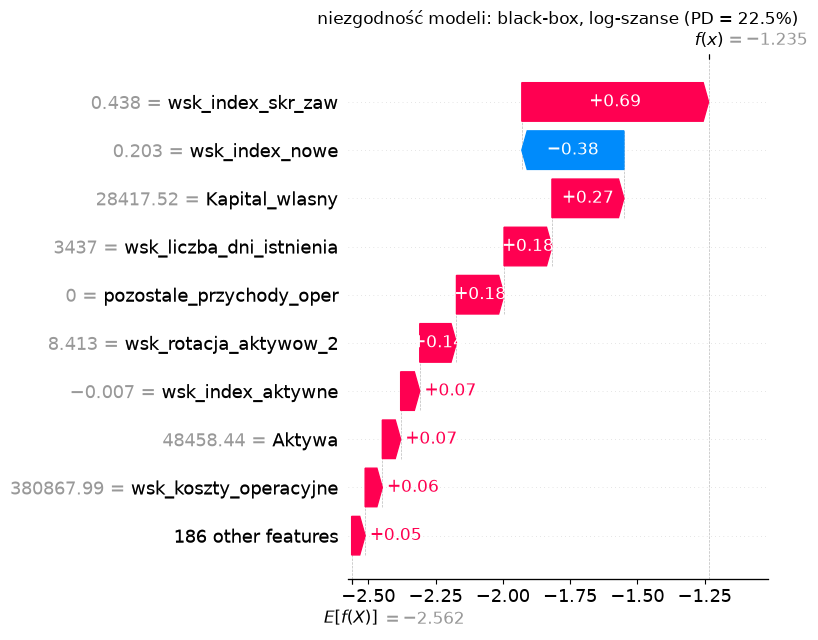

,wartość,SHAP,mnożnik szans e^φ,kierunek
wsk_index_skr_zaw,0.438181,0.694,2.00,podnosi ryzyko
wsk_index_nowe,0.202669,-0.380,0.68,obniża ryzyko
Kapital_wlasny,28417.520000,0.268,1.31,podnosi ryzyko
wsk_liczba_dni_istnienia,3437.000000,0.178,1.19,podnosi ryzyko
pozostale_przychody_oper,0.000000,0.177,1.19,podnosi ryzyko
wsk_rotacja_aktywow_2,8.413057,0.136,1.15,podnosi ryzyko


,wartość,punkty,utracone vs maksimum,SHAP karty
Kapital_wlasny,28417.52,61.0,18.4,0.264
podatek_dochodowy,2413.0,77.7,10.2,-0.289
pozostale_przychody_oper,0.0,64.5,6.3,0.109
wsk_zysk_zobowiazania,0.0,66.3,4.5,0.044
wsk_index_nowe,0.202669,94.9,0.0,-0.757
wsk_ogolnego_zadluzenia_1,0.150557,73.5,0.0,-0.156
wsk_stopa_zysku_sprzedaz,0.065776,75.6,0.0,-0.259
wsk_sytuacji_fin,74.73162,70.0,0.0,-0.087


In [42]:
p_star = MARGIN / (MARGIN + LGD)
pd_bb_te, pd_lg_te = P["black-box"]["test"], P["logit"]["test"]
rangi_bb, rangi_lg = pd.Series(pd_bb_te).rank(pct=True), pd.Series(pd_lg_te).rank(pct=True)
PRZYPADKI = {"najwyższe PD": int(np.argmax(pd_bb_te)),
             "graniczna (PD ≈ p*)": int(np.argmin(np.abs(pd_bb_te - p_star))),
             "typowa przyjęta": int(np.argmin(np.abs(pd_bb_te - np.median(pd_bb_te)))),
             "niezgodność modeli": int((rangi_bb - rangi_lg).abs().idxmax())}
display(pd.DataFrame({k: {"wiersz testu": i, "PD black-box": pd_bb_te[i], "PD karta": pd_lg_te[i],
                          "punkty karty": wynik_model[i], "default (fakt)": y_te[i]} for k, i in PRZYPADKI.items()}).T.round(3))

def powody(i, n=10):
    s = pd.Series(PHI_BB[i], index=FEATURES)
    s = s.reindex(s.abs().sort_values(ascending=False).index)[:n]
    return pd.DataFrame({"wartość": [XS.loc[i, c] for c in s.index], "SHAP": s.round(3).to_numpy(),
                         "mnożnik szans e^φ": np.exp(s).round(2).to_numpy(),
                         "kierunek": np.where(s > 0, "podnosi ryzyko", "obniża ryzyko")}, index=s.index)

def punkty_vs_max(i):
    pk = punkty_firmy(X_te.iloc[[i]]).iloc[0]
    maks = karta_pkt.groupby("cecha")["punkty"].max()
    return pd.DataFrame({"wartość": X_te.iloc[i][CECHY_L], "punkty": pk.round(1), "utracone vs maksimum": (maks[CECHY_L] - pk).round(1),
                         "SHAP karty": PHI_LOG.iloc[i].round(3)}).sort_values("utracone vs maksimum", ascending=False)

for nazwa, i in PRZYPADKI.items():
    print(f"\n=== {nazwa}: wiersz {i}, PD black-box {pd_bb_te[i]:.1%}, PD karta {pd_lg_te[i]:.1%}, default = {y_te[i]} ===")
    shap.plots.waterfall(shap.Explanation(values=PHI_BB[i], base_values=BAZA_BB, data=XS.iloc[i].to_numpy(dtype=object),
                                          feature_names=FEATURES), max_display=10, show=False)
    plt.title(f"{nazwa}: black-box, log-szanse (PD = {pd_bb_te[i]:.1%})"); plt.tight_layout()
    plt.savefig(f"wykresy/waterfall_{list(PRZYPADKI).index(nazwa) + 1}.png", dpi=110, bbox_inches="tight"); plt.show()
    display(powody(i, 6))
    display(punkty_vs_max(i))

**Wnioski z przypadków:**
- **Najwyższe PD** (80%, karta 68%, 465 pkt): oba modele zgodnie. Ryzyko podnoszą przede wszystkim wskaźniki branżowe
  (`wsk_index_nowe` 0,47 i `wsk_index_skr_zaw` 0,35 - branża z dużą dynamiką nowych i skreślanych firm; razem mnożnik szans ok. 3,5),
  a z danych firmy: mały kapitał własny (4,3 tys. zł), ujemny ROE brutto, kapitał własny równy 1,8% aktywów i zadłużenie ogólne 98,2%.
  Karta traci najwięcej punktów na podobnych pozycjach (branża 54 pkt, zadłużenie 32 pkt, zerowy podatek 27 pkt). Firma mimo to
  nie zbankrutowała.
- **Graniczna** (PD 18,2% ≈ p*, karta 17,9%): wszystkie główne wkłady podnoszą ryzyko, każdy umiarkowanie - podwyższony
  `wsk_index_nowe` (0,30; +0,42), wiek firmy, `wsk_index_skr_zaw` (0,29), niski podatek (362 zł) i `wsk_sytuacji_fin`. Karta traci
  najwięcej punktów na branży (33 pkt) i podatku (25 pkt). Firma nie zbankrutowała.
- **Typowa przyjęta** (PD 7,2%, karta 9,1%): wkłady częściowo się znoszą - niski `wsk_index_skr_zaw` (0,17; -0,67), pozostałe
  przychody (24,9 tys. zł) i niski `wsk_index_nowe` obniżają ryzyko, a wysoki `wsk_zast_kapitalu_podstawowego`, zerowy podatek i wiek
  je podnoszą. Karta traci najwięcej punktów na zerowym podatku (27 pkt).
- **Niezgodność modeli** (karta 3,4%, black-box 22,5%): karta widzi tylko niski `wsk_index_nowe` (0,20 - maksimum punktów), a black-box
  także wysoki `wsk_index_skr_zaw` (0,44, mnożnik szans 2,00), którego karta nie ma, oraz kapitał własny (28,4 tys. zł), wiek i zerowe
  pozostałe przychody. **Firma zbankrutowała - trafniej ocenił ją black-box.** Takie firmy (duża różnica ocen dwóch modeli) warto
  kierować do analityka; przypadek pokazuje też koszt użycia w karcie tylko jednego wskaźnika branżowego.

### 9.1 LIME (kilka obserwacji)

`LimeTabularExplainer` dla black-boxa, z próbkowaniem wokół wyjaśnianej firmy (`sample_around_instance=True`) i bez
dyskretyzacji - zastępczy model liniowy w standaryzowanych cechach. Próbki losujemy wokół firmy z pełnym odchyleniem standardowym
każdej cechy z train, w ok. 195 wymiarach, więc „otoczenie” LIME jest szerokie (raczej półglobalne niż lokalne), a domyślne jądro
nadaje próbkom prawie równe wagi. Dwie decyzje wynikają z danych:
- braki uzupełniamy medianą z train (LIME nie obsługuje braków; black-box dostaje te same uzupełnione wartości),
- cechy przycinamy do 1-99 percentyla z train - przy skrajnych ogonach odchylenie standardowe jest ogromne i próbki
  LIME leżałyby daleko poza danymi.

Na wykresie pokazujemy **wkłady** cech: współczynnik LIME × standaryzowana wartość firmy (względem średniej z train; dla cechy
kategorycznej wskaźnik „ta sama kategoria” = 1). Razem z wyrazem wolnym sumują się do lokalnego PD zastępczego modelu i - jak SHAP -
opisują wkład względem przeciętnej firmy, więc można je porównać z SHAP (9.2).

LIME (jak SHAP) wyjaśnia **surowe PD black-boxa**, nie PD po przesunięciu do 4% (11.4). Przesunięcie jest monotoniczne,
więc kierunki i ranking wkładów są te same, ale wielkości wkładów w skali PD się różnią (Lab 6, 5; SHAP modelu końcowego - 12.3.1).

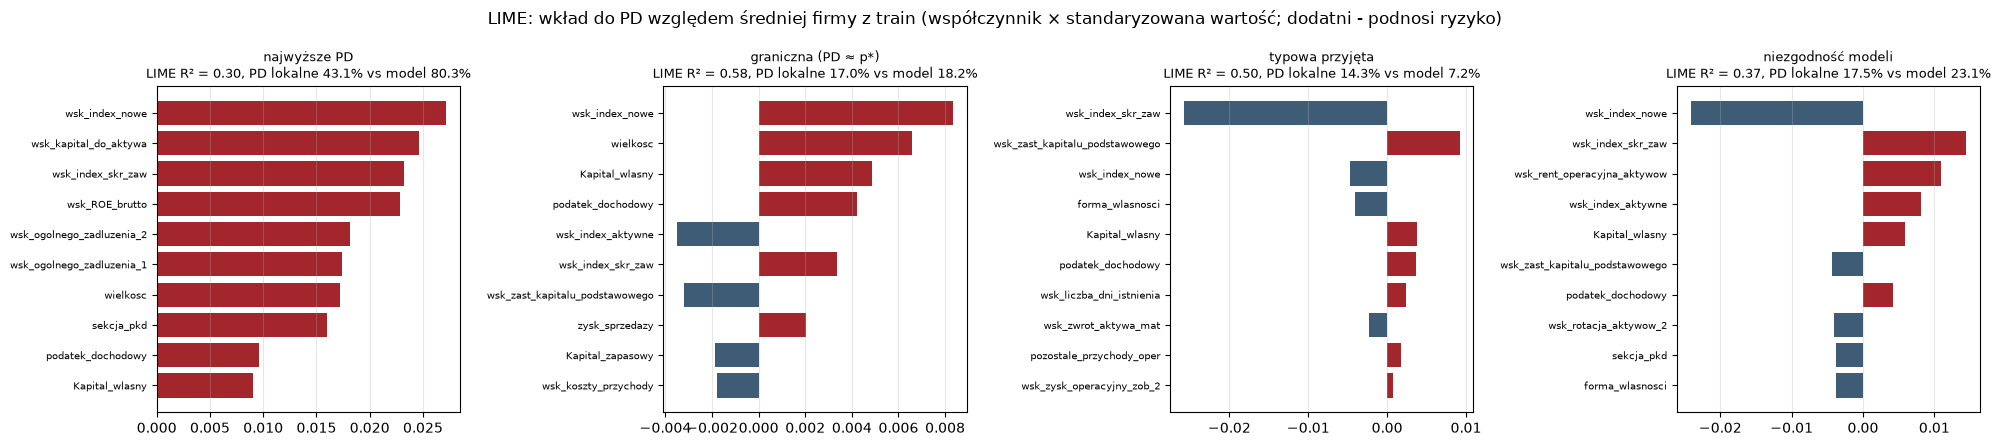

In [43]:
from lime.lime_tabular import LimeTabularExplainer

granice_lime = X_tr[num_cols].quantile([0.01, 0.99])
mediany_lime = X_tr[num_cols].median()
kat_wartosci = {c: sorted(X_tr[c].unique()) for c in cat_cols}

def do_lime(Xw):
    # DataFrame -> macierz LIME: braki = mediana, przycięcie 1-99%, kategorie jako kody całkowite
    A = Xw[num_cols].fillna(mediany_lime).clip(granice_lime.loc[0.01], granice_lime.loc[0.99], axis=1)
    B = pd.DataFrame({c: Xw[c].map({v: k for k, v in enumerate(kat_wartosci[c])}).fillna(0) for c in cat_cols}, index=Xw.index)
    return pd.concat([A, B], axis=1)[FEATURES].to_numpy(dtype=float)

def z_lime(M):
    # macierz LIME -> DataFrame dla black-boxa
    D = pd.DataFrame(M, columns=FEATURES)
    for c in cat_cols:
        D[c] = [kat_wartosci[c][int(round(v))] for v in D[c]]
    return D

def f_lime(M):
    return black_box.predict_proba(z_lime(M))

L_TR, L_TE = do_lime(X_tr), do_lime(X_te)
idx_kat = [FEATURES.index(c) for c in cat_cols]

def lime_explainer(seed, kernel_width=None):
    return LimeTabularExplainer(L_TR, feature_names=FEATURES, categorical_features=idx_kat, class_names=["brak", "default"],
                                discretize_continuous=False, sample_around_instance=True, kernel_width=kernel_width, random_state=seed)

_skaler_lime = lime_explainer(RNG_SEED).scaler
LIME_SREDNIA, LIME_SKALA = _skaler_lime.mean_.copy(), _skaler_lime.scale_.copy()

def lime_wklady(e, x):
    # wkład cechy = współczynnik LIME × standaryzowana wartość firmy (względem średniej train); kategorie: wskaźnik „ta sama kategoria” = 1
    xs = (x - LIME_SREDNIA) / LIME_SKALA
    xs[idx_kat] = 1.0
    return pd.Series({FEATURES[j]: b * xs[j] for j, b in e.local_exp[1]})

def lime_wyjasnij(i, seed=RNG_SEED, num_samples=5000, kernel_width=None, num_features=10):   # z Lab 6 (5), zmienione ustawienia - opis wyżej
    return lime_explainer(seed, kernel_width).explain_instance(L_TE[i], f_lime, num_features=num_features, num_samples=num_samples)

LIME = {}
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (nazwa, i) in zip(axes, PRZYPADKI.items()):
    e = lime_wyjasnij(i); LIME[nazwa] = e
    lst = sorted(lime_wklady(e, L_TE[i]).items(), key=lambda t: abs(t[1]))
    ax.barh([a for a, _ in lst], [b for _, b in lst], color=[KOL["test"] if b > 0 else KOL["train"] for _, b in lst])
    ax.set_title(f"{nazwa}\nLIME R² = {e.score:.2f}, PD lokalne {e.local_pred[0]:.1%} vs model {f_lime(L_TE[[i]])[0, 1]:.1%}", fontsize=9)
    ax.tick_params(axis="y", labelsize=7); ax.grid(axis="x", alpha=0.3)
plt.suptitle("LIME: wkład do PD względem średniej firmy z train (współczynnik × standaryzowana wartość; dodatni - podnosi ryzyko)"); plt.tight_layout(); plt.savefig("wykresy/lime_przypadki.png", dpi=110); plt.show()

### 9.2 Zgodność wyjaśnień lokalnych: SHAP, LIME i karta

Jaccard top-5 cech (SHAP vs LIME dla black-boxa) i zgodność kierunku wpływu dla cech wspólnych.

In [44]:
def top_k(seria, k=5):
    return set(seria.abs().sort_values(ascending=False).index[:k])

wiersze = []
for nazwa, i in PRZYPADKI.items():
    s_shap = pd.Series(PHI_BB[i], index=FEATURES)
    s_lime = lime_wklady(LIME[nazwa], L_TE[i])
    wspolne = top_k(s_shap, 10) & set(s_lime.index)
    wiersze.append({"przypadek": nazwa, "Jaccard top-5 SHAP vs LIME": len(top_k(s_shap) & top_k(s_lime)) / len(top_k(s_shap) | top_k(s_lime)),
                    "wspólne cechy (top-10 SHAP ∩ LIME)": len(wspolne),
                    "zgodny kierunek wśród wspólnych": f"{sum(np.sign(s_shap[c]) == np.sign(s_lime[c]) for c in wspolne)} / {len(wspolne)}",
                    "top-3 SHAP": ", ".join(s_shap.abs().sort_values(ascending=False).index[:3]),
                    "top-3 LIME": ", ".join(s_lime.abs().sort_values(ascending=False).index[:3]),
                    "top-3 karta (utracone pkt)": ", ".join(punkty_vs_max(i).index[:3])})
display(pd.DataFrame(wiersze).set_index("przypadek"))

,Jaccard top-5 SHAP vs LIME,wspólne cechy (top-10 SHAP ∩ LIME),zgodny kierunek wśród wspólnych,top-3 SHAP,top-3 LIME,top-3 karta (utracone pkt)
przypadek,,,,,,
najwyższe PD,0.666667,8,8 / 8,"wsk_index_nowe, wsk_index_skr_zaw, Kapital_wlasny","wsk_index_nowe, wsk_kapital_do_aktywa, wsk_ind...","wsk_index_nowe, wsk_ogolnego_zadluzenia_1, pod..."
graniczna (PD ≈ p*),0.250000,4,3 / 4,"wsk_index_nowe, wsk_liczba_dni_istnienia, wsk_...","wsk_index_nowe, wielkosc, Kapital_wlasny","wsk_index_nowe, podatek_dochodowy, Kapital_wlasny"
typowa przyjęta,0.428571,6,5 / 6,"wsk_index_skr_zaw, wsk_zast_kapitalu_podstawow...","wsk_index_skr_zaw, wsk_zast_kapitalu_podstawow...","podatek_dochodowy, wsk_index_nowe, wsk_stopa_z..."
niezgodność modeli,0.428571,5,4 / 5,"wsk_index_skr_zaw, wsk_index_nowe, Kapital_wlasny","wsk_index_nowe, wsk_index_skr_zaw, wsk_rent_op...","Kapital_wlasny, podatek_dochodowy, pozostale_p..."


**Wnioski:** LIME i SHAP wskazują częściowo różne cechy: Jaccard top-5 od 0,25 (graniczna) do 0,67 (najwyższe PD), ale we
wszystkich czterech przypadkach obie metody stawiają na pierwszym miejscu wskaźnik branżowy, a dla trzech firm mają oba wskaźniki
branżowe w top-3. Kierunek wpływu zgadza się dla prawie wszystkich wspólnych cech (8/8, 3/4, 5/6 i 4/5). Dla firmy granicznej LIME
obok branży wskazuje wielkość firmy i kapitał własny, a SHAP - wiek firmy i drugi wskaźnik branżowy. Przyczyny różnic:
(a) LIME przybliża model liniowo w szerokim otoczeniu 195-wymiarowym, a XGBoost jest schodkowy - lokalne PD LIME potrafi odbiegać
od PD modelu (43% wobec 80% dla firmy z najwyższym PD); (b) wkład LIME to nachylenie z tego otoczenia razy odległość od średniej
z train, a SHAP - wkład względem tła liczony z rzeczywistego kształtu modelu; (c) przy skorelowanych cechach obie metody mogą przypisać
wkład różnym „bliźniakom”. Wierność i stabilność obu metod mierzymy w sekcji 10.

### 9.3 „What-if”: jak zmienia się PD przy zmianie jednej cechy

Dla firmy granicznej zmieniamy kolejno każdą z 4 najważniejszych cech (według jej SHAP) na wartości z siatki kwantyli
train, pozostałe cechy bez zmian (to ICE pojedynczej firmy). Linia przerywana - próg p*.

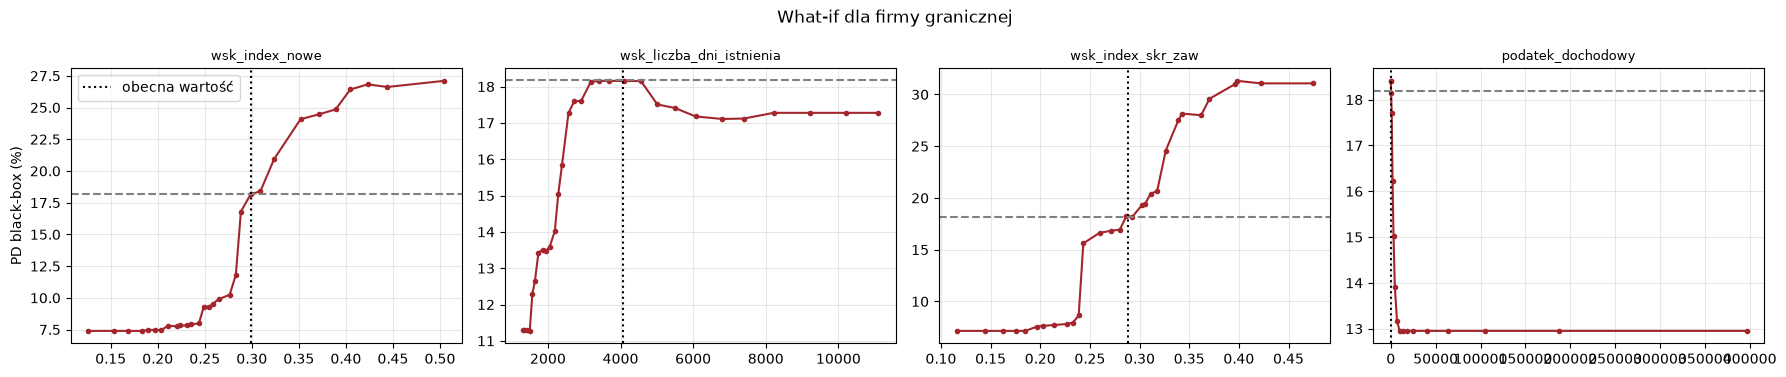

In [45]:
i_gr = PRZYPADKI["graniczna (PD ≈ p*)"]
cechy_wi = [c for c in powody(i_gr, 10).index if c in num_cols][:4]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, c in zip(axes, cechy_wi):
    s = siatka_kwantyli(c, n=30)
    p_wi = black_box.predict_proba(pd.concat([XS.iloc[[i_gr]].assign(**{c: v}) for v in s]))[:, 1]
    ax.plot(s, 100 * p_wi, "o-", ms=3, color=KOL["black-box"]); ax.axhline(100 * p_star, ls="--", color="gray")
    ax.axvline(XS.loc[i_gr, c], ls=":", color="black", label="obecna wartość"); ax.set_title(c, fontsize=9); ax.grid(alpha=0.3)
axes[0].set_ylabel("PD black-box (%)"); axes[0].legend()
plt.suptitle("What-if dla firmy granicznej"); plt.tight_layout(); plt.savefig("wykresy/what_if.png", dpi=110); plt.show()

**Wnioski:** dla firmy granicznej najważniejsze cechy to wskaźniki branżowe, na które firma nie ma wpływu: spadek `wsk_index_nowe`
poniżej ok. 0,28 obniżyłby PD z 18% do 7,5-12%, a wzrost powyżej ok. 0,35 podniósłby je do 24-27%; `wsk_index_skr_zaw` poniżej
ok. 0,24 obniża PD do ok. 7-9%, a powyżej ok. 0,33 podnosi do 25-31%. Z cech zależnych od firmy wyższy podatek dochodowy (kilka tys. zł
zamiast 362 zł, czyli wyższy zysk) obniża PD do ok. 13%. Wiek firmy działa niemonotonicznie (młodsze firmy - niższe PD, do ok. 11%),
co nie ma oczywistej interpretacji ekonomicznej i nie jest dźwignią. To analiza modelu, nie świata:
zmiana jednej pozycji sprawozdania zmienia też powiązane wskaźniki (analiza z zależnościami - sekcja 13).

## 10. Wierność i stabilność wyjaśnień

### 10.1 Wierność SHAP

SHAP jest z konstrukcji **lokalnie dokładny**: baza + Σφ = f(x) (sprawdzone w 7.1 - błąd rzędu 1e-6). Wierność w sensie
„czy wkłady oddają zachowanie modelu” sprawdzamy testem usuwania: zastępujemy k najważniejszych (według SHAP) cech firmy
wartościami z tła (mediana train) i mierzymy zmianę log-szans; porównujemy z zastąpieniem k losowych cech.

In [46]:
mediany_bb = X_tr[num_cols].median()
def usun_cechy(i, cechy):
    x = XS.iloc[[i]].copy()
    for c in cechy:
        x[c] = mediany_bb[c] if c in num_cols else X_tr[c].mode()[0]
    return f_bb(x)[0]

rng_u = np.random.default_rng(RNG_SEED)
proba_u = rng_u.choice(len(XS), 100, replace=False)
wiersze = []
for k in [1, 3, 5, 10]:
    d_shap, d_los = [], []
    for i in proba_u:
        f0 = f_bb(XS.iloc[[i]])[0]
        top = pd.Series(np.abs(PHI_BB[i]), index=FEATURES).sort_values(ascending=False).index[:k]
        d_shap.append(abs(usun_cechy(i, top) - f0))
        d_los.append(abs(usun_cechy(i, rng_u.choice(FEATURES, k, replace=False)) - f0))
    wiersze.append({"k usuniętych cech": k, "średnia |zmiana log-szans|: top-k SHAP": np.mean(d_shap),
                    "średnia |zmiana log-szans|: k losowych": np.mean(d_los)})
display(pd.DataFrame(wiersze).set_index("k usuniętych cech").round(3))

,średnia |zmiana log-szans|: top-k SHAP,średnia |zmiana log-szans|: k losowych
k usuniętych cech,,
1,0.648,0.020
3,0.854,0.077
5,0.909,0.109
10,0.993,0.119


**Wnioski:** zastąpienie jednej najważniejszej według SHAP cechy wartością typową zmienia log-szanse średnio o 0,65, a jednej losowej -
o 0,020 (ok. 32 razy mniej); dla 10 cech: 0,99 vs 0,12. Ranking SHAP wiernie wskazuje cechy, od których zależy prognoza modelu.

### 10.2 Wierność LIME: lokalne R² i błąd aproksymacji

Dla każdej firmy losujemy **nowe** otoczenie tak jak LIME (rozkład normalny wokół firmy w skali cech LIME) i porównujemy
PD black-boxa z prognozą zastępczego modelu liniowego: ważone R² (wagi jądra LIME) i średni błąd bezwzględny (MAE, w pp PD).
Raportujemy też R² zwracane przez LIME (na jego własnych próbkach) i różnicę PD w samym punkcie. Sprawdzamy wpływ
szerokości jądra: o lokalności decyduje skala losowania (pełne odchylenie standardowe cech z train), a jądro tylko waży wylosowane
próbki - przy domyślnej szerokości prawie równo, przy węższej istotną wagę zachowuje niewiele próbek.

In [47]:
def wiernosc_lime(i, e, explainer, n=2000, seed=0):
    rng_f = np.random.default_rng(seed)
    x = L_TE[i]; skala, srednia = explainer.scaler.scale_, explainer.scaler.mean_
    Z = x + rng_f.normal(size=(n, len(x))) * skala
    for j in idx_kat:                                             # kategorie: losowanie według częstości z train (jak w LIME)
        wart, licz = np.unique(L_TR[:, j], return_counts=True)
        Z[:, j] = rng_f.choice(wart, n, p=licz / licz.sum())
    Zs = (Z - srednia) / skala
    for j in idx_kat:
        Zs[:, j] = (Z[:, j] == x[j]).astype(float)
    xs = (x - srednia) / skala
    for j in idx_kat:
        xs[j] = 1.0
    odl = np.sqrt(((Zs - xs) ** 2).sum(axis=1))
    szer = explainer.kernel_width if hasattr(explainer, "kernel_width") else np.sqrt(len(x)) * 0.75
    w = np.sqrt(np.exp(-(odl ** 2) / szer ** 2))
    zast = e.intercept[1] + sum(b * Zs[:, j] for j, b in e.local_exp[1])
    prawdz = f_lime(Z)[:, 1]
    r2 = 1 - np.sum(w * (prawdz - zast) ** 2) / np.sum(w * (prawdz - np.average(prawdz, weights=w)) ** 2)
    return {"R² LIME (własne próbki)": e.score, "R² ważone (nowe otoczenie)": r2, "MAE (pp PD)": 100 * np.mean(np.abs(prawdz - zast)),
            "|PD lokalne - PD modelu| w punkcie (pp)": 100 * abs(e.local_pred[0] - f_lime(L_TE[[i]])[0, 1])}

SZER_DOM = np.sqrt(len(FEATURES)) * 0.75
proba_l = np.random.default_rng(1).choice(len(XS), 20, replace=False)
wiersze = []
for mn in [0.25, 0.5, 1.0, 2.0]:
    for i in proba_l:
        ex = lime_explainer(RNG_SEED, kernel_width=SZER_DOM * mn); ex.kernel_width = SZER_DOM * mn
        e = ex.explain_instance(L_TE[i], f_lime, num_features=10, num_samples=5000)
        wiersze.append({"szerokość jądra": f"{mn} × domyślna", **wiernosc_lime(i, e, ex)})
tab_wiern = pd.DataFrame(wiersze).groupby("szerokość jądra").agg(["median", "min"])
display(tab_wiern.round(3))

R² LIME (własne próbki)        R² ważone (nowe otoczenie)  \
                                 median    min                     median   
szerokość jądra                                                             
0.25 × domyślna                   0.021  0.011                     -2.773   
0.5 × domyślna                    0.463  0.079                      0.468   
1.0 × domyślna                    0.473  0.209                      0.491   
2.0 × domyślna                    0.475  0.210                      0.482   

                        MAE (pp PD)         \
                    min      median    min   
szerokość jądra                              
0.25 × domyślna -10.940       8.987  6.114   
0.5 × domyślna    0.093       3.904  1.710   
1.0 × domyślna    0.249       3.907  1.649   
2.0 × domyślna    0.249       3.907  1.651   

                |PD lokalne - PD modelu| w punkcie (pp)         
                                                 median    min  
szerokość jądra                                                 
0.25 × domyślna                                   0.071  0.033  
0.5 × domyślna                                    7.609  3.448  
1.0 × domyślna                                    8.560  3.514  
2.0 × domyślna                                    8.637  3.527

**Wnioski:**
- Przy domyślnym jądrze lokalne R² LIME wynosi ok. 0,47 (mediana; najgorsza firma 0,21), na nowym otoczeniu 0,49 - zastępczy model
  liniowy wyjaśnia ok. połowę zmienności PD black-boxa w otoczeniu firmy, przy błędzie średnim ok. 3,9 pp PD.
- PD zastępczego modelu w samym punkcie różni się od PD black-boxa o ok. 8,6 pp (mediana, minimum 3,5 pp) - **wyjaśnienie LIME może być
  mylące dla konkretnej firmy**, zwłaszcza blisko progu decyzyjnego.
- Szerokość jądra nie czyni wyjaśnienia bardziej lokalnym, bo próbki są losowane tak samo szeroko. Szersze jądro (2 ×) niczego nie
  zmienia, bo wagi już są prawie płaskie; 0,5 × daje prawie to samo (R² 0,46-0,47, błąd w punkcie 7,6 pp). Przy 0,25 × istotną wagę
  zachowuje tylko sama firma i bardzo nieliczne próbki: PD w punkcie zgadza się (0,07 pp), ale R² na własnych próbkach spada do 0,02,
  a na nowym otoczeniu jest ujemne (-2,77) - zastępczy model niczego nie wyjaśnia.
- Przyczyna: model drzewiasty jest kawałkami stały, a otoczenie ma 195 wymiarów i rozrzut całego train - liniowe przybliżenie jest
  z natury słabe.

### 10.3 Stabilność LIME: te same firmy, różne ziarna losowania

Dla każdego przypadku z sekcji 9: 10 uruchomień LIME z różnymi ziarnami, dla 1 000, 5 000 i 20 000 próbek.
Miary: średni Jaccard top-5 między parami uruchomień i średnia korelacja Spearmana wkładów (na sumie wybranych cech).
Model black-box jest za każdym razem ten sam - więc **zmienność wynika wyłącznie z metody wyjaśniającej** (losowanie próbek).

In [48]:
def stabilnosc_lime(i, num_samples, n_seed=10):              # z Lab 6 (5), 10 ziaren zamiast 5
    wagi = []
    for s in range(n_seed):
        e = lime_wyjasnij(i, seed=s, num_samples=num_samples)
        wagi.append(lime_wklady(e, L_TE[i]))
    jac, rho = [], []
    for a, b in itertools.combinations(range(n_seed), 2):
        ta, tb = top_k(wagi[a]), top_k(wagi[b]); jac.append(len(ta & tb) / len(ta | tb))
        u = wagi[a].index.union(wagi[b].index)
        rho.append(spearmanr(wagi[a].reindex(u).fillna(0), wagi[b].reindex(u).fillna(0))[0])
    return np.mean(jac), np.mean(rho)

wiersze = []
for nazwa, i in PRZYPADKI.items():
    for ns in [1000, 5000, 20000]:
        j_, r_ = stabilnosc_lime(i, ns)
        wiersze.append({"przypadek": nazwa, "liczba próbek": ns, "Jaccard top-5": j_, "Spearman wag": r_})
tab_stab_lime = pd.DataFrame(wiersze).pivot(index="przypadek", columns="liczba próbek")
display(tab_stab_lime.round(3))

Jaccard top-5               Spearman wag              
liczba próbek               1000   5000   20000        1000   5000   20000
przypadek                                                                 
graniczna (PD ≈ p*)         0.584  0.832  0.933        0.690  0.929  0.972
najwyższe PD                0.513  0.763  0.933        0.752  0.759  0.940
niezgodność modeli          0.493  0.560  0.800        0.568  0.773  0.925
typowa przyjęta             0.489  0.762  1.000        0.688  0.842  0.951

**Wnioski:** przy 1 000 próbek top-5 wkładów LIME zmienia się między ziarnami (Jaccard 0,49-0,58, ρ wkładów 0,57-0,75). Przy 5 000
próbek stabilność rośnie (Jaccard 0,56-0,83, ρ wkładów 0,76-0,93), a przy 20 000 jest wysoka (Jaccard 0,80-1,0, ρ wkładów 0,93-0,97).
Ponieważ model się nie zmienia, **niestabilność pochodzi z metody** (losowanie otoczenia) i maleje z liczbą próbek. Stabilność nie
oznacza jednak wierności - stabilne wyjaśnienie może nadal słabo opisywać model (10.2).

### 10.4 Stabilność rankingów ważności (SHAP) przy zmianie danych uczących

TreeSHAP jest deterministyczny, więc tu źródłem zmienności jest **model**: uczymy black-box od nowa na każdym z 5 foldów
treningowych CV i liczymy globalny ranking średniego |SHAP| na tym samym zbiorze testowym. To samo dla karty (binning,
WoE i β od nowa). Miary: Spearman rang (wszystkie cechy) i Jaccard top-k między parami foldów.

In [49]:
rank_bb, rank_lg = [], []
for a, b in FOLDY:
    m = model_black_box(**PARAM_BB).fit(X_tr.iloc[a], y_tr[a])
    pre_f, clf_f = m.named_steps["pre"], m.named_steps["clf"]
    G_f = np.array([[float(zrodlo(n) == f) for f in FEATURES] for n in pre_f.get_feature_names_out()])
    rank_bb.append(pd.Series(np.abs(shap.TreeExplainer(clf_f, data=pre_f.transform(X_tr.sample(300, random_state=RNG_SEED)), feature_perturbation="interventional")(pre_f.transform(X_te)).values @ G_f).mean(axis=0), index=FEATURES))
    mk = karta(CECHY_L).fit(X_tr.iloc[a][CECHY_L], y_tr[a])
    W = mk.named_steps["woe"].transform(X_te[CECHY_L]); Wt = mk.named_steps["woe"].transform(X_tr.iloc[a][CECHY_L]).mean()
    rank_lg.append(np.abs((W - Wt) * mk.named_steps["lr"].coef_.ravel()).mean())

def zgodnosc_rankingow(lista, k):
    jac, rho = [], []
    for s1, s2 in itertools.combinations(lista, 2):
        t1, t2 = set(s1.nlargest(k).index), set(s2.nlargest(k).index)
        jac.append(len(t1 & t2) / len(t1 | t2)); rho.append(spearmanr(s1, s2[s1.index])[0])
    return np.mean(jac), np.min(jac), np.mean(rho)

wiersze = []
for nazwa, lista, ks_ in [("black-box (192 cech)", rank_bb, [5, 10, 20]), ("karta (7 cech)", rank_lg, [3])]:
    for k in ks_:
        jm, jmin, r = zgodnosc_rankingow(lista, k)
        wiersze.append({"model": nazwa, "top-k": k, "Jaccard średni": jm, "Jaccard min": jmin, "Spearman rang (wszystkie cechy)": r})
display(pd.DataFrame(wiersze).set_index(["model", "top-k"]).round(3))
grupy_bb = [pd.Series({c: s[[f for f in num_cols if abs(kor_tr.loc[c, f]) >= 0.7]].sum() for c in CECHY_L}) for s in rank_bb]
jm, jmin, r = zgodnosc_rankingow(grupy_bb, 3)
print(f"Black-box, grupy tematyczne (7.3): Jaccard top-3 średni {jm:.2f} (min {jmin:.2f}), Spearman rang grup {r:.2f}")

Jaccard średni  Jaccard min  \
model                top-k                                
black-box (192 cech) 5               0.581        0.429   
                     10              0.609        0.429   
                     20              0.517        0.429   
karta (7 cech)       3               0.600        0.500   

                            Spearman rang (wszystkie cechy)  
model                top-k                                   
black-box (192 cech) 5                                0.778  
                     10                               0.778  
                     20                               0.778  
karta (7 cech)       3                                0.826

Black-box, grupy tematyczne (7.3): Jaccard top-3 średni 0.70 (min 0.50), Spearman rang grup 0.90


**Wnioski:**
- Ranking SHAP black-boxa zmienia się, gdy model uczymy na innym podzbiorze train: Jaccard top-5 ≈ 0,58 (min 0,43), top-10 ≈ 0,61,
  korelacja rang ≈ 0,78. Przy ustalonym modelu i tle SHAP jest deterministyczny, więc **niestabilność pochodzi z modelu**: przy ponad
  190 skorelowanych wskaźnikach boosting w każdym foldzie wybiera inne „bliźniacze” cechy, a SHAP rozdziela między nie wkład.
- Na poziomie grup tematycznych (7.3) ranking jest stabilniejszy: korelacja rang grup 0,90 (wobec 0,78 dla pojedynczych
  cech), Jaccard top-3 ≈ 0,70 (min 0,50). Karta ma Jaccard top-3 ≈ 0,60 (min 0,50) i korelację rang 0,83. **Dlatego w monitoringu (14.2) śledzimy ważność grup, nie
  pojedynczych cech.**
- **Ograniczenia SHAP / LIME:** przy skorelowanych cechach wkład jest dzielony arbitralnie między warianty tej samej miary; wariant
  `interventional` ocenia model także na kombinacjach cech, których nie ma w danych; wyjaśnienia opisują model, nie przyczyny -
  „obniżenie zadłużenia o X obniży PD o Y” nie wynika z SHAP.

## 11. Kalibracja probabilistyczna

Kolejność z Lab 3 (krok 4): **A. kalibracja statystyczna** (kształt) → **B. dostosowanie do tendencji centralnej 4%**
(poziom). Kalibratory i przesunięcie dopasowujemy na **valid** (dane niewykorzystane do uczenia modeli), test - tylko ocena.

### 11.1 Diagnostyka przed kalibracją (valid)

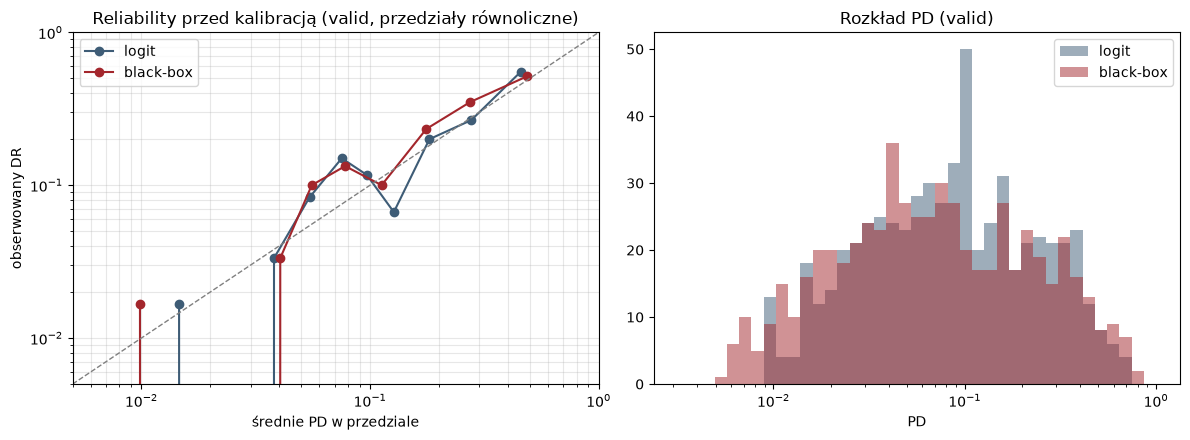

,DR,średnie PD,AUC,Brier,log-loss,ECE,ACE,CITL a,slope b,rzetelność (REL),rozdzielczość (RES),niepewność (UNC)
logit,0.1483,0.1346,0.7972,0.1031,0.3402,0.0291,0.0341,0.1349,1.0578,0.0021,0.0242,0.1263
black-box,0.1483,0.1282,0.8334,0.1000,0.3240,0.0238,0.0336,0.2131,1.0440,0.0016,0.0263,0.1263


In [50]:
from sklearn.calibration import calibration_curve

def reliability(ax, y, p, label, n_bins=10, **kw):           # z Lab 3
    obs, pred = calibration_curve(y, p, n_bins=n_bins, strategy="quantile")
    ax.plot(pred, obs, "o-", label=label, **kw)

def os_log(ax, lo=5e-3, hi=1.0):                              # z Lab 3
    ax.plot([lo, hi], [lo, hi], "--", color="gray", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel("średnie PD w przedziale"); ax.set_ylabel("obserwowany DR"); ax.grid(alpha=0.3, which="both")

def murphy(y, p, n_bins=10):                                  # z Lab 2 - dekompozycja Briera
    edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    idx = np.clip(np.digitize(p, edges[1:-1], right=True), 0, len(edges) - 2)
    o = y.mean(); rel = res = 0.0
    for m in range(len(edges) - 1):
        msk = idx == m
        if msk.any():
            w = msk.mean(); rel += w * (p[msk].mean() - y[msk].mean()) ** 2; res += w * (y[msk].mean() - o) ** 2
    return {"rzetelność (REL)": rel, "rozdzielczość (RES)": res, "niepewność (UNC)": o * (1 - o)}

KOL_KAL = ["DR", "średnie PD", "AUC", "Brier", "log-loss", "ECE", "ACE", "CITL a", "slope b"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for m in ["logit", "black-box"]:
    reliability(axes[0], y_va, P[m]["valid"], m, color=KOL[m])
    axes[1].hist(P[m]["valid"], bins=np.logspace(-2.5, 0, 40), alpha=0.5, label=m, color=KOL[m])
os_log(axes[0]); axes[0].set_title("Reliability przed kalibracją (valid, przedziały równoliczne)"); axes[0].legend()
axes[1].set_xscale("log"); axes[1].set_xlabel("PD"); axes[1].set_title("Rozkład PD (valid)"); axes[1].legend()
plt.tight_layout(); plt.savefig("wykresy/kalibracja_przed.png", dpi=120); plt.show()
display(pd.concat([pd.DataFrame({m: metryki(y_va, P[m]["valid"]) for m in ["logit", "black-box"]}).T[KOL_KAL],
                   pd.DataFrame({m: murphy(y_va, P[m]["valid"]) for m in ["logit", "black-box"]}).T], axis=1).round(4))

**Wnioski:** przed kalibracją oba modele są dobrze skalibrowane do częstości w próbie: na valid średnie PD 12,8-13,5% przy DR 14,8%
(CITL a ≈ 0,13-0,21 - lekkie zaniżenie poziomu, większe w black-boxie), ECE 0,024-0,029, a składnik rzetelności Briera
(REL ≈ 0,002) jest ponad 10 razy mniejszy od rozdzielczości (RES ≈ 0,024-0,026). Nachylenie wynosi 1,06 (karta) i 1,04 (black-box) -
blisko 1, więc kształt PD jest poprawny. Oba modele uczono bez wag klas i bez oversamplingu, więc nie trzeba korekty a priori.

### 11.2 Kształt: Platt, izotoniczna, beta - wybór walidacją krzyżową wewnątrz valid

Kalibrator uczymy na valid, więc nie możemy go na valid oceniać. Jak w Lab 3: **5-krotna CV wewnątrz valid** -
kalibrator uczy się na 4/5 valid, ocena na 1/5. Na valid jest 89 defaultów - izotoniczna (dziesiątki schodków) jest
narażona na przeuczenie (Lab 2, sekcja 6), Platt i beta mają 2-3 parametry.

In [51]:
from sklearn.isotonic import IsotonicRegression

def _beta_cechy(p):                                           # z Lab 3
    p = np.clip(p, EPS, 1 - EPS); return np.column_stack([np.log(p), -np.log(1 - p)])

FIT = {                                                       # z Lab 3 (4.2)
    "bez kalibracji": lambda y, p: None,
    "Platt": lambda y, p: LogisticRegression(C=1e6, max_iter=1000).fit(_z(p).reshape(-1, 1), y),
    "izotoniczna": lambda y, p: IsotonicRegression(out_of_bounds="clip", y_min=EPS, y_max=1 - EPS).fit(p, y),
    "beta": lambda y, p: LogisticRegression(C=1e6, max_iter=1000).fit(_beta_cechy(p), y),
}

def zastosuj(metoda, kal, p):                                 # z Lab 3
    if metoda == "bez kalibracji":
        return np.asarray(p)
    if metoda == "Platt":
        return kal.predict_proba(_z(p).reshape(-1, 1))[:, 1]
    if metoda == "beta":
        return kal.predict_proba(_beta_cechy(p))[:, 1]
    return kal.predict(p)

def cv_miara(metoda, y, p, k=5, miara="log-loss"):            # z Lab 3 (cv_logloss), dodany Brier
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=RNG_SEED); w = []
    for a, b in skf.split(p.reshape(-1, 1), y):
        q = np.clip(zastosuj(metoda, FIT[metoda](y[a], p[a]), p[b]), EPS, 1 - EPS)
        w.append(log_loss(y[b], q) if miara == "log-loss" else brier_score_loss(y[b], q))
    return float(np.mean(w))

wybor_kal = pd.concat({miara: pd.DataFrame({m: {met: cv_miara(met, y_va, P[m]["valid"], miara=miara) for met in FIT}
                                            for m in ["logit", "black-box"]}).T for miara in ["log-loss", "Brier"]}, axis=1)
display(wybor_kal.round(5))

PROSTOTA = ["bez kalibracji", "Platt", "beta", "izotoniczna"]
METODA = {}
for m in ["logit", "black-box"]:
    ll = wybor_kal["log-loss"].loc[m]
    METODA[m] = next(met for met in PROSTOTA if ll[met] <= ll.min() + 0.001)       # najprostsza w granicy 0,001 od najlepszej
print("Wybrana metoda kształtu (najprostsza z log-loss w CV nie gorszym niż najlepszy + 0,001):", METODA)

log-loss                                        Brier  \
          bez kalibracji    Platt izotoniczna     beta bez kalibracji   
logit            0.34017  0.34441     0.40024  0.34465        0.10310   
black-box        0.32399  0.32739     0.34964  0.32803        0.09999   

                                         
             Platt izotoniczna     beta  
logit      0.10398     0.10827  0.10393  
black-box  0.10117     0.10324  0.10151

Wybrana metoda kształtu (najprostsza z log-loss w CV nie gorszym niż najlepszy + 0,001): {'logit': 'bez kalibracji', 'black-box': 'bez kalibracji'}


**Wnioski:** w CV wewnątrz valid najniższy log-loss i Brier ma wariant **bez kalibracji kształtu**; Platt i beta są o 0,003-0,005 gorsze
w log-loss, izotoniczna wyraźnie gorsza (0,350-0,400) - przy 89 defaultach jej schodki są przeuczone (Lab 2, sekcja 6). Kształt PD jest
poprawny i wystarczy korekta poziomu. Wybór jest zgodny z zasadą z Lab 3: przy różnicach w trzecim miejscu po przecinku wybieramy
rozwiązanie najprostsze.

### 11.3 Walidacja po kalibracji statystycznej (test)

DR  średnie PD     AUC   Brier  log-loss  \
logit     bez kalibracji  0.1486      0.1468  0.7810  0.1050    0.3499   
          Platt           0.1486      0.1621  0.7810  0.1054    0.3513   
          izotoniczna     0.1486      0.1645  0.7651  0.1072    0.3697   
          beta            0.1486      0.1622  0.7810  0.1053    0.3504   
black-box bez kalibracji  0.1486      0.1414  0.7915  0.1041    0.3471   
          Platt           0.1486      0.1632  0.7915  0.1057    0.3492   
          izotoniczna     0.1486      0.1648  0.7768  0.1070    0.3817   
          beta            0.1486      0.1625  0.7915  0.1063    0.3510   

                             ECE     ACE  CITL a  slope b  
logit     bez kalibracji  0.0153  0.0299  0.0167   0.9456  
          Platt           0.0288  0.0318 -0.1269   0.8938  
          izotoniczna     0.0423  0.0361 -0.1558   0.6696  
          beta            0.0247  0.0297 -0.1294   0.8956  
black-box bez kalibracji  0.0467  0.0402  0.0742   0.8321  
          Platt           0.0524  0.0471 -0.1472   0.7970  
          izotoniczna     0.0587  0.0565 -0.1711   0.5271  
          beta            0.0584  0.0470 -0.1384   0.7864

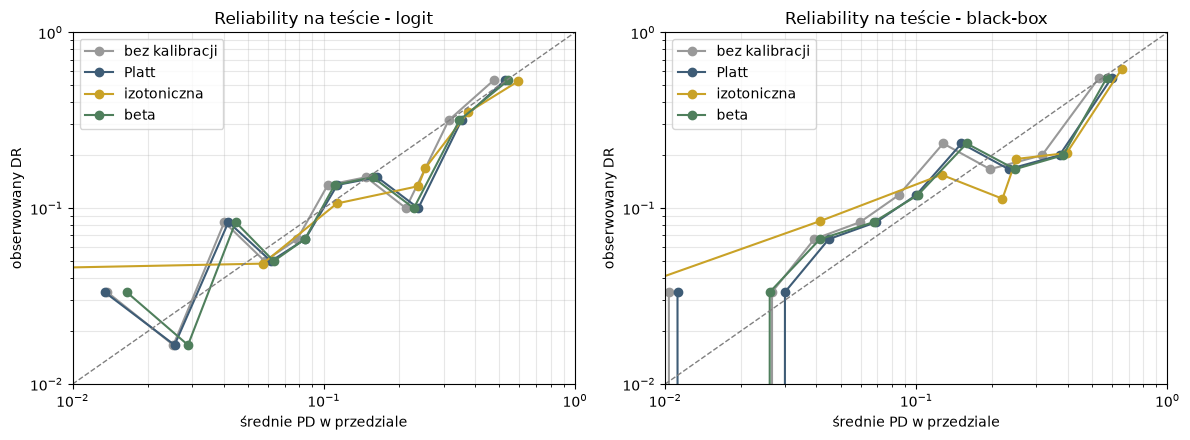

In [52]:
KAL = {m: FIT[METODA[m]](y_va, P[m]["valid"]) for m in P}
PS = {m: {s: zastosuj(METODA[m], KAL[m], P[m][s]) for s in X} for m in P}                     # po kalibracji kształtu
wiersze = {}
for m in P:
    for met in ["bez kalibracji", "Platt", "izotoniczna", "beta"]:
        kal = FIT[met](y_va, P[m]["valid"])
        wiersze[(m, met)] = metryki(y_te, zastosuj(met, kal, P[m]["test"]))
tab_kal_test = pd.DataFrame(wiersze).T[KOL_KAL]
display(tab_kal_test.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, m in zip(axes, P):
    for met, kol in [("bez kalibracji", "#999999"), ("Platt", KOL["logit"]), ("izotoniczna", KOL["valid"]), ("beta", "#4F7F5C")]:
        reliability(ax, y_te, zastosuj(met, FIT[met](y_va, P[m]["valid"]), P[m]["test"]), met, color=kol)
    os_log(ax, lo=1e-2); ax.set_title(f"Reliability na teście - {m}"); ax.legend()
plt.tight_layout(); plt.savefig("wykresy/kalibracja_metody.png", dpi=120); plt.show()

**Wnioski (test):** test potwierdza decyzję z 11.2. Platt i beta, dopasowane na valid (gdzie PD było lekko zaniżone, CITL 0,13-0,21),
przesuwają PD na teście za wysoko (średnie PD 16,2-16,3% przy DR 14,9%, CITL od -0,13 do -0,15), obniżają nachylenie do 0,79-0,90
i nieznacznie pogarszają log-loss i Brier. Izotoniczna pogarsza log-loss (0,370 i 0,382), AUC (remisy w schodkach) i nachylenie
(0,67 i 0,53). PD bez kalibracji kształtu ma na teście najlepsze CITL (0,02 i 0,07) i nachylenie (0,95 i 0,83).

### 11.4 Dostosowanie do tendencji centralnej PD = 4% (calibration-in-the-large)

$$\text{logit}(q) = \text{logit}(p) + \delta$$

4% traktujemy jako zewnętrzne założenie biznesowe o docelowym portfelu (długookresowa średnia DR). Docelowy portfel odtwarzamy,
**przeważając valid do DR = 4%** (`wagi_4`: default 0,04 / DR, brak defaultu 0,96 / (1 - DR)) - zmienia się tylko udział defaultów,
a zależność cech od statusu firmy zostaje ta sama. δ wyznaczamy tak, by **średnie PD na valid ważonym do DR 4%** wyniosło 4%,
i to samo δ stosujemy na teście (Lab 3, 4.3). Dla porównania podajemy δ ze wzoru korekty a priori (Lab 2):
logit(4%) - logit(DR valid). DR w naszych danych to ok. 14,8%, więc δ < 0 - PD po korekcie będzie **niższe od DR w próbie** z założenia.

In [53]:
def delta_do_sredniej(p, cel, w=None, lo=-15.0, hi=15.0, iters=100):   # z Lab 3, z wagami portfela docelowego
    z = _z(p)
    for _ in range(iters):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if np.average(expit(z + mid), weights=w) < cel else (lo, mid)
    return (lo + hi) / 2

def wagi_4(y):                                                # portfel docelowy: DR = 4% (wagi: default 0,04 / DR, brak defaultu 0,96 / (1 - DR))
    return np.where(y == 1, TARGET_PD / y.mean(), (1 - TARGET_PD) / (1 - y.mean()))

W_VA4, W_TE4 = wagi_4(y_va), wagi_4(y_te)
DELTA = {m: delta_do_sredniej(PS[m]["valid"], TARGET_PD, W_VA4) for m in P}
P4 = {m: {s: expit(_z(PS[m][s]) + DELTA[m]) for s in X} for m in P}                       # po kalibracji do 4%

def pd_koncowe(Xw, m="black-box"):
    # pełny łańcuch: model -> kalibracja kształtu -> przesunięcie do 4%
    p = black_box.predict_proba(Xw)[:, 1] if m == "black-box" else baseline.predict_proba(Xw[CECHY_L])[:, 1]
    return expit(_z(zastosuj(METODA[m], KAL[m], p)) + DELTA[m])

for m in P:
    print(f"{m:9s}: kształt = {METODA[m]}, δ = {DELTA[m]:+.3f} (wzór korekty a priori: {_z(np.array([TARGET_PD]))[0] - _z(np.array([y_va.mean()]))[0]:+.3f}) | "
          f"średnie PD po δ na valid ważonym do DR 4%: {np.average(P4[m]['valid'], weights=W_VA4):.2%} | "
          f"na valid bez wag: {P4[m]['valid'].mean():.2%} (DR valid {y_va.mean():.2%})")
wiersze = {}
for m in P:
    wiersze[(m, "1. model")] = metryki(y_te, P[m]["test"])
    wiersze[(m, f"2. kształt: {METODA[m]}")] = metryki(y_te, PS[m]["test"])
    wiersze[(m, "3. kształt + 4%")] = metryki(y_te, P4[m]["test"])
tab_4 = pd.DataFrame(wiersze).T[KOL_KAL + ["Gini"]]
display(tab_4.round(4))

logit    : kształt = bez kalibracji, δ = -1.280 (wzór korekty a priori: -1.430) | średnie PD po δ na valid ważonym do DR 4%: 4.00% | na valid bez wag: 4.80% (DR valid 14.83%)
black-box: kształt = bez kalibracji, δ = -1.218 (wzór korekty a priori: -1.430) | średnie PD po δ na valid ważonym do DR 4%: 4.00% | na valid bez wag: 5.00% (DR valid 14.83%)


DR  średnie PD     AUC   Brier  \
logit     1. model                    0.1486      0.1468  0.7810  0.1050   
          2. kształt: bez kalibracji  0.1486      0.1468  0.7810  0.1050   
          3. kształt + 4%             0.1486      0.0532  0.7810  0.1208   
black-box 1. model                    0.1486      0.1414  0.7915  0.1041   
          2. kształt: bez kalibracji  0.1486      0.1414  0.7915  0.1041   
          3. kształt + 4%             0.1486      0.0568  0.7915  0.1169   

                                      log-loss     ECE     ACE  CITL a  \
logit     1. model                      0.3499  0.0153  0.0299  0.0167   
          2. kształt: bez kalibracji    0.3499  0.0153  0.0299  0.0167   
          3. kształt + 4%               0.4200  0.0954  0.0954  1.2963   
black-box 1. model                      0.3471  0.0467  0.0402  0.0742   
          2. kształt: bez kalibracji    0.3471  0.0467  0.0402  0.0742   
          3. kształt + 4%               0.4133  0.0920  0.0928  1.2922   

                                      slope b   Gini  
logit     1. model                     0.9456  0.562  
          2. kształt: bez kalibracji   0.9456  0.562  
          3. kształt + 4%              0.9461  0.562  
black-box 1. model                     0.8321  0.583  
          2. kształt: bez kalibracji   0.8321  0.583  
          3. kształt + 4%              0.8325  0.583

**Wnioski:**
- δ = -1,280 (karta) i -1,218 (black-box), mniej co do modułu niż wzór korekty a priori (-1,430), bo na valid PD było już lekko zaniżone
  (CITL 0,13-0,21, 11.1). Średnie PD na valid ważonym do DR 4% wynosi 4,0%, na valid bez wag 4,8-5,0%, a na teście bez wag 5,3-5,7%.
- **AUC i Gini się nie zmieniają** (Gini 0,562 i 0,583 - przesunięcie jest monotoniczne) - ranking ryzyka i kolejność firm są te same.
- Na teście bez wag (DR 14,9%) kalibracja statystyczna się **pogarsza**: CITL a ≈ 1,29-1,30, Brier 0,105 → 0,121 (karta) i 0,104 → 0,117
  (black-box), log-loss 0,350 → 0,420 i 0,347 → 0,413. To skutek założenia, nie błąd modelu: 4% to tendencja centralna docelowego portfela,
  a nasza próba ma DR 3,7 razy wyższy.
- Nachylenie się nie zmienia (0,95 i 0,83) - δ przesuwa poziom, nie kształt (krzywe reliability przesuwają się równolegle w lewo).

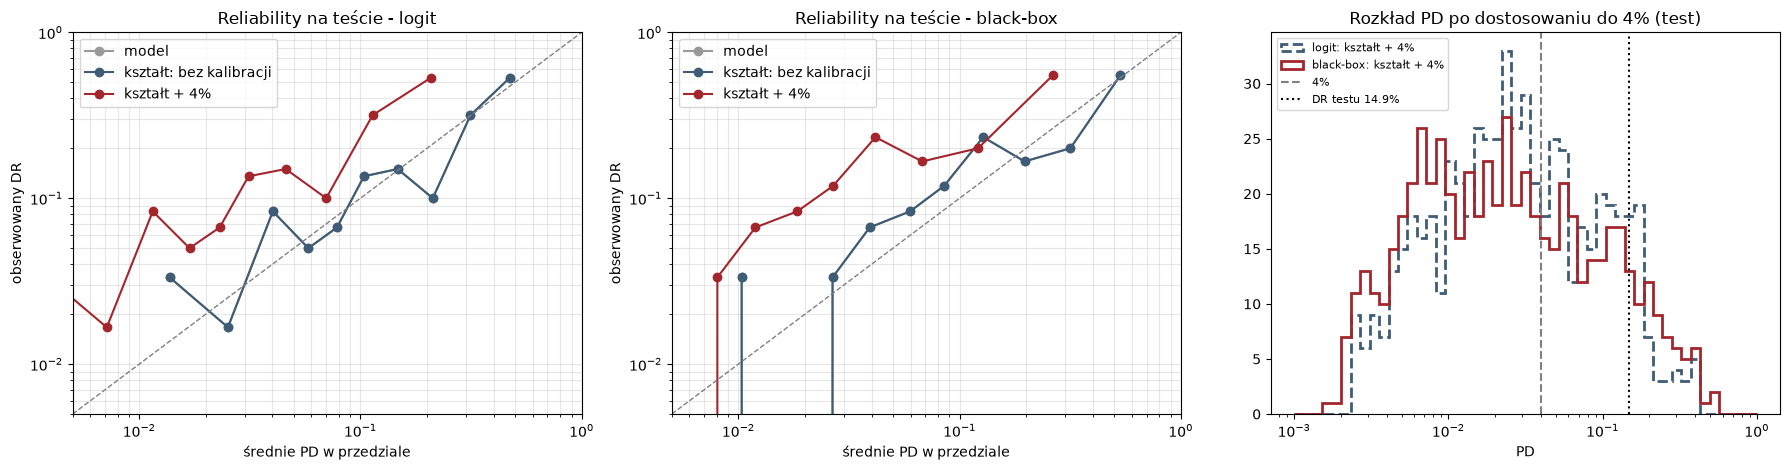

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, m in zip(axes[:2], P):
    for p, lab, col in [(P[m]["test"], "model", "#999999"), (PS[m]["test"], f"kształt: {METODA[m]}", KOL["logit"]), (P4[m]["test"], "kształt + 4%", KOL["test"])]:
        reliability(ax, y_te, p, lab, color=col)
    os_log(ax, lo=5e-3); ax.set_title(f"Reliability na teście - {m}"); ax.legend()
for m, ls in [("logit", "--"), ("black-box", "-")]:
    axes[2].hist(P4[m]["test"], bins=np.logspace(-3, 0, 50), histtype="step", lw=2, ls=ls, label=f"{m}: kształt + 4%", color=KOL[m])
axes[2].axvline(TARGET_PD, ls="--", color="gray", label="4%"); axes[2].axvline(y_te.mean(), ls=":", color="black", label=f"DR testu {y_te.mean():.1%}")
axes[2].set_xscale("log"); axes[2].set_xlabel("PD"); axes[2].set_title("Rozkład PD po dostosowaniu do 4% (test)"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig("wykresy/kalibracja_4proc.png", dpi=120); plt.show()

### 11.5 Czy PD = 4% jest skalibrowane dla docelowego portfela?

Przesunięcie logitu o δ odpowiada **korekcie a priori** (Lab 2): zmianie częstości klas z π = 14,8% na 4% przy tej samej
zależności cech od statusu firmy. Jeśli docelowy portfel różni się od próby tylko udziałem defaultów, PD po δ dopasowanym na valid
ważonym do DR 4% powinno być skalibrowane także na teście **przeważonym tak samo** (wagi z 11.4, liczone z DR testu).

In [55]:
w_te = W_TE4
def miary_wazone(y, p, w):
    z = _z(p)
    a = brentq(lambda d: np.average(expit(z + d), weights=w) - np.average(y, weights=w), -15, 15)
    b = LogisticRegression(C=1e6, max_iter=1000).fit(z.reshape(-1, 1), y, sample_weight=w).coef_[0, 0]
    return {"DR (ważony)": np.average(y, weights=w), "średnie PD (ważone)": np.average(p, weights=w),
            "Brier (ważony)": np.average((p - y) ** 2, weights=w), "log-loss (ważony)": log_loss(y, np.clip(p, EPS, 1 - EPS), sample_weight=w),
            "CITL a": a, "slope b": b}
display(pd.DataFrame({(m, wariant): miary_wazone(y_te, p, w_te) for m in P
                      for wariant, p in [("kształt (bez δ)", PS[m]["test"]), ("kształt + 4%", P4[m]["test"])]}).T.round(4))

DR (ważony)  średnie PD (ważone)  Brier (ważony)  \
logit     kształt (bez δ)         0.04               0.1286          0.0498   
          kształt + 4%            0.04               0.0450          0.0357   
black-box kształt (bez δ)         0.04               0.1203          0.0499   
          kształt + 4%            0.04               0.0462          0.0356   

                           log-loss (ważony)  CITL a  slope b  
logit     kształt (bez δ)             0.1978 -1.4118   0.9711  
          kształt + 4%                0.1456 -0.1322   0.9703  
black-box kształt (bez δ)             0.1915 -1.3844   0.8513  
          kształt + 4%                0.1446 -0.1664   0.8541

**Wnioski:** na teście przeważonym do DR = 4% PD po δ jest skalibrowane z niewielkim zawyżeniem: średnie PD 4,5% (karta) i 4,6%
(black-box) przy ważonym DR 4,0%, CITL a ≈ -0,13 i -0,17, nachylenie 0,97 i 0,85, Brier 0,036. Zawyżenie wynika z miejsca dopasowania δ:
na valid PD było zaniżone (CITL 0,13-0,21), więc δ wyszło mniejsze co do modułu, a na teście PD przed δ jest prawie skalibrowane
(CITL 0,02-0,07) - to samo δ przesuwa je więc trochę za mało w dół. Błąd jest w stronę ostrożną (PD wyższe od DR). PD bez δ jest tam
zawyżone ok. 3 razy (średnie PD 12,0-12,9%, CITL ≈ -1,38 do -1,41). Dostosowanie do 4% jest więc poprawne **pod warunkiem**, że docelowy portfel
różni się od próby tylko udziałem defaultów, a zależność wskaźników finansowych od statusu firmy jest taka sama. Jeśli próba jest
nadreprezentowana w defaultach przez dobór (np. celowe dobranie upadłych firm), to założenie jest rozsądne; jeśli wysoki DR wynika
ze złego okresu - PD po δ będzie zaniżone w podobnych okresach (filozofia TTC, nie PIT).

## 12. Progi decyzyjne i mapowanie PD → rating

### 12.1 Skala główna i rozkład firm

Skala z Lab 3: 7 klas dla firm bez defaultu (AAA ... CCC), granice rosnące geometrycznie, klasa **D** zarezerwowana dla
stwierdzonego defaultu (nie przypisujemy jej w dniu oceny). PD po dostosowaniu do 4%.

In [56]:
RATING_BINS = [0.00, 0.01, 0.02, 0.05, 0.08, 0.12, 0.20, 1.0 + 1e-9]       # z Lab 3
RATING_LABELS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC"]

def rating(p):
    return pd.Categorical(pd.cut(np.asarray(p), bins=RATING_BINS, labels=RATING_LABELS, right=False), categories=RATING_LABELS, ordered=True)

skala = pd.DataFrame({"klasa": RATING_LABELS,
                      "przedział PD": [f"{100 * RATING_BINS[k]:.0f}% - {100 * RATING_BINS[k + 1]:.0f}%" if k < 6 else "≥ 20%" for k in range(7)]}).set_index("klasa")
R = {m: {s: rating(P4[m][s]) for s in X} for m in P}
for m in P:
    udz = pd.Series(W_TE4).groupby(np.asarray(R[m]["test"]).astype(str)).sum().reindex(RATING_LABELS).fillna(0) / W_TE4.sum()
    skala[f"udział - {m} (test ważony do DR 4%)"] = (100 * udz).round(1)
    skala[f"HHI {m}"] = round(float((udz ** 2).sum()), 3)
display(skala)

,przedział PD,udział - logit (test ważony do DR 4%),HHI logit,udział - black-box (test ważony do DR 4%),HHI black-box
klasa,,,,,
AAA,0% - 1%,23.5,0.193,34.4,0.213
AA,1% - 2%,20.9,0.193,16.4,0.213
A,2% - 5%,25.9,0.193,21.5,0.213
BBB,5% - 8%,11.7,0.193,9.8,0.213
BB,8% - 12%,8.6,0.193,6.8,0.213
B,12% - 20%,7.4,0.193,7.5,0.213
CCC,≥ 20%,1.9,0.193,3.7,0.213


**Wnioski:** na portfelu docelowym (test ważony do DR 4%) ok. 70-72% firm trafia do klas AAA-A, do klas BB-CCC ok. 18%.
W karcie najliczniejsza jest klasa A (25,9%), w black-boxie AAA (34,4%). Koncentracja (HHI 0,19 karta, 0,21 black-box) jest wyższa
od równomiernej (0,14); żadna klasa karty nie przekracza 26% portfela, a klasa AAA black-boxa obejmuje ponad jedną trzecią.
Black-box ma większy udział klas skrajnych: AAA (34,4% vs 23,5%) i CCC (3,7% vs 1,9%).

### 12.2 Backtest per klasa: monotoniczność, test Jeffreysa, światła (test ważony do DR 4%)

Backtest robimy na portfelu, do którego skalibrowano PD: test przeważony do DR 4% (wagi z 11.4). Liczba firm i defaultów w klasie
to sumy wag, więc test Jeffreysa jest tu przybliżony. Dla porównania liczymy backtest próby: test bez wag i PD bez δ.


logit: portfel docelowy (test ważony do DR 4%, PD po δ) - DR rośnie monotonicznie między klasami: True | światła: {'zielone': 7} | dla porównania próba (test bez wag, PD bez δ): {'zielone': 7}


,firm,defaultów,n (ważone),defaulty (ważone),oczekiwane,średnie PD,DR,p Jeffreysa,światło
klasa,,,,,,,,,
AAA,128,4,140.8905,1.0769,0.8080,0.0057,0.0076,0.3174,zielone
AA,118,9,125.3236,2.4229,1.8536,0.0148,0.0193,0.3010,zielone
A,150,16,155.3964,4.3074,4.7810,0.0308,0.0277,0.5587,zielone
BBB,69,9,70.0747,2.4229,4.2604,0.0608,0.0346,0.8187,zielone
BB,54,11,51.4451,2.9613,5.0905,0.0990,0.0576,0.8410,zielone
B,59,26,44.2080,6.9996,6.7173,0.1519,0.1583,0.4338,zielone
CCC,21,14,11.6617,3.7690,3.4451,0.2954,0.3232,0.4014,zielone



black-box: portfel docelowy (test ważony do DR 4%, PD po δ) - DR rośnie monotonicznie między klasami: False | światła: {'zielone': 7} | dla porównania próba (test bez wag, PD bez δ): {'zielone': 5, 'żółte': 1, 'czerwone': 1}


,firm,defaultów,n (ważone),defaulty (ważone),oczekiwane,średnie PD,DR,p Jeffreysa,światło
klasa,,,,,,,,,
AAA,186,4,206.2872,1.0769,1.1731,0.0057,0.0052,0.4687,zielone
AA,93,8,97.9937,2.1537,1.3931,0.0142,0.0220,0.2312,zielone
A,131,22,128.8234,5.9227,3.9269,0.0305,0.0460,0.1518,zielone
BBB,58,8,58.5302,2.1537,3.6235,0.0619,0.0368,0.7785,zielone
BB,40,5,40.8096,1.3461,4.0392,0.0990,0.0330,0.9365,zielone
B,51,15,44.6293,4.0382,6.7550,0.1514,0.0905,0.8761,zielone
CCC,40,27,21.9266,7.2688,6.7370,0.3073,0.3315,0.3922,zielone


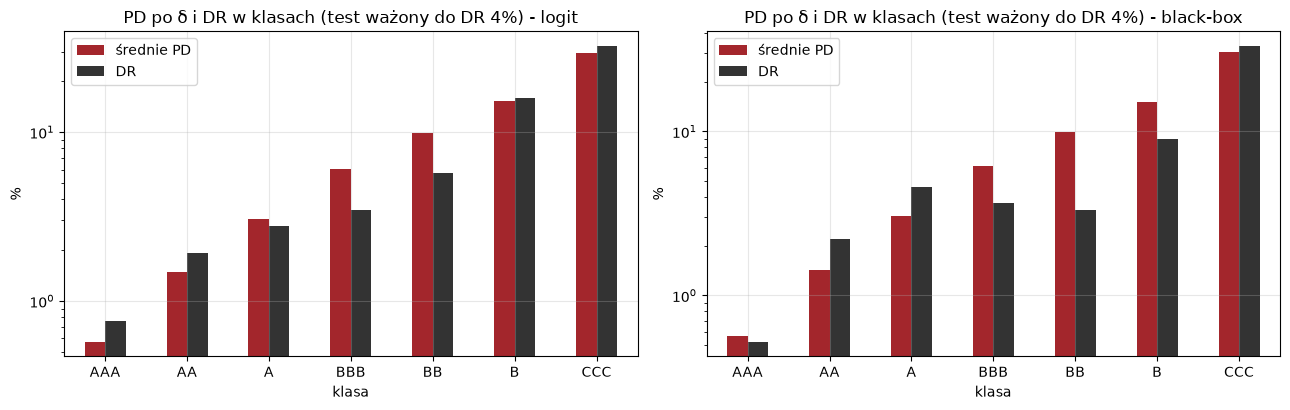

In [57]:
def swiatlo(p):                                               # z Lab 3
    return "zielone" if p >= 0.05 else ("żółte" if p >= 0.01 else "czerwone")

def backtest(y, p, r, w=None):                                # z Lab 3; w - wagi portfela docelowego (n i defaulty to sumy wag)
    w = np.ones(len(y)) if w is None else np.asarray(w, dtype=float)
    rows = []
    for lab in RATING_LABELS:
        msk = np.asarray(r == lab)
        if not msk.any():
            continue
        n_k, d_k = float(w[msk].sum()), float((w[msk] * y[msk]).sum())
        pd_k = float(np.average(p[msk], weights=w[msk]))
        pj = float(beta_dist.cdf(pd_k, d_k + 0.5, n_k - d_k + 0.5))
        rows.append({"klasa": lab, "firm": int(msk.sum()), "defaultów": int(y[msk].sum()), "n (ważone)": n_k, "defaulty (ważone)": d_k,
                     "oczekiwane": n_k * pd_k, "średnie PD": pd_k, "DR": d_k / n_k, "p Jeffreysa": pj, "światło": swiatlo(pj)})
    return pd.DataFrame(rows).set_index("klasa")

BT, BT_PROBA = {}, {}
for m in P:
    BT[m] = backtest(y_te, P4[m]["test"], R[m]["test"], W_TE4)
    BT_PROBA[m] = backtest(y_te, PS[m]["test"], R[m]["test"])
    print(f"\n{m}: portfel docelowy (test ważony do DR 4%, PD po δ) - DR rośnie monotonicznie między klasami: "
          f"{bool(np.all(np.diff(BT[m]['DR'].to_numpy()) >= 0))} | światła: {BT[m]['światło'].value_counts().to_dict()} | "
          f"dla porównania próba (test bez wag, PD bez δ): {BT_PROBA[m]['światło'].value_counts().to_dict()}")
    display(BT[m].round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, m in zip(axes, P):
    (100 * BT[m][["średnie PD", "DR"]]).plot.bar(ax=ax, rot=0, color=[KOL["test"], "#333333"])
    ax.set_yscale("log"); ax.set_ylabel("%"); ax.set_title(f"PD po δ i DR w klasach (test ważony do DR 4%) - {m}"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("wykresy/backtest.png", dpi=120); plt.show()

**Wnioski:**
- W karcie DR rośnie monotonicznie między klasami (od 0,8% w AAA do 32,3% w CCC). W black-boxie monotoniczność jest naruszona:
  BBB (DR 3,7%) i BB (3,3%) mają niższy DR niż A (4,6%). W tych klasach jest po 5-22 defaultów bez wag, więc odwrócenie może być
  przypadkowe, ale karta szereguje klasy czytelniej.
- Na portfelu docelowym wszystkie 7 klas ma zielone światło w obu modelach (p Jeffreysa 0,30-0,84 w karcie i 0,15-0,94 w black-boxie).
  W klasach BBB-BB oczekiwana liczba defaultów jest wyższa od zaobserwowanej - PD po δ jest tam raczej ostrożne. Ważone liczby defaultów
  w klasach są małe (1-7), więc moc testu jest niska.
- Dla porównania backtest próby (test bez wag, PD bez δ): karta - 7 zielonych świateł, black-box - 5 zielonych, 1 żółte i 1 czerwone.

### 12.3 Funkcja zysku i próg operacyjny

Brak kolumny z ekspozycją, więc przyjmujemy **jednakową ekspozycję EAD = 1** dla każdej firmy (wyniki - na jednostkę
ekspozycji). Ekonomia z Lab 3: przyjęty dobry klient daje zysk MARGIN = 10%, przyjęty zły - stratę LGD = 45%, odrzucenie - 0.

| | default | brak defaultu |
|---|---|---|
| **przyjęty** | FN: strata −LGD | TN: zysk +MARGIN |
| **odrzucony** | TP: 0 (uniknięta strata) | FP: 0 (utracony zysk MARGIN) |

Próg teoretyczny dla skalibrowanego PD: p* = MARGIN / (MARGIN + LGD) = 18,2% (wykład 3: najpierw δ, potem p*). Próg empiryczny
szukamy na **valid przeważonym do DR = 4%** (wagi z 11.4) - tylko wtedy PD po δ jest skalibrowane względem portfela, na którym
liczymy zysk, i próg empiryczny powinien wyjść w pobliżu p*. Dla porównania pokazujemy wariant „portfel jak próba” (DR 14,8%):
PD bez δ z progiem p*. Wyniki zysku dla portfela 4% są ważone (liczby firm to sumy wag).

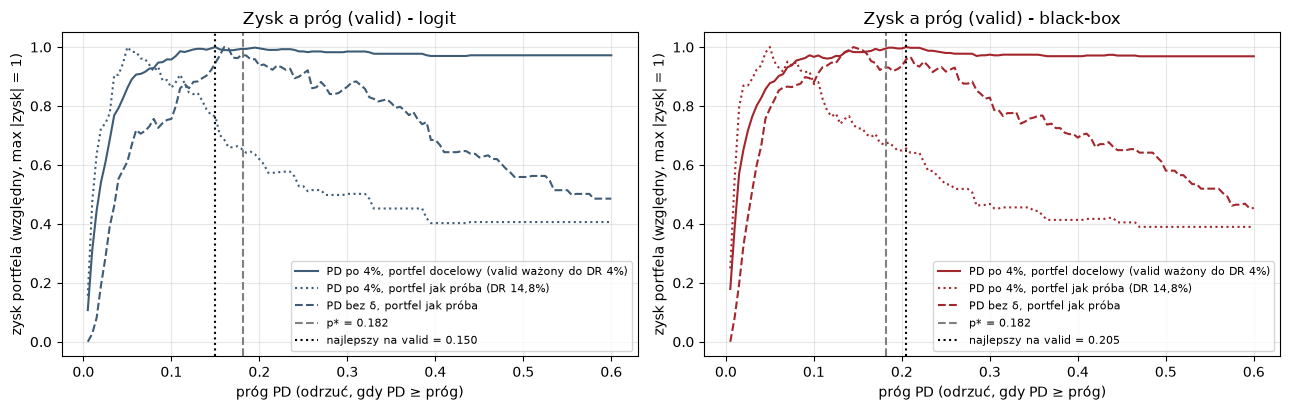

próg  stopa akceptacji  \
model     wariant                                                           
logit     portfel 4%: próg z valid (PD 4%)        0.150             0.939   
          portfel 4%: p* (PD 4%)                  0.182             0.974   
          portfel 4%: przyjmij wszystkich         1.010             1.000   
          portfel jak próba: p* (PD bez δ)        0.182             0.725   
          portfel jak próba: przyjmij wszystkich  1.010             1.000   
black-box portfel 4%: próg z valid (PD 4%)        0.205             0.965   
          portfel 4%: p* (PD 4%)                  0.182             0.948   
          portfel 4%: przyjmij wszystkich         1.010             1.000   
          portfel jak próba: p* (PD bez δ)        0.182             0.738   
          portfel jak próba: przyjmij wszystkich  1.010             1.000   

                                                  DR wśród przyjętych  \
model     wariant                                                       
logit     portfel 4%: próg z valid (PD 4%)                      0.028   
          portfel 4%: p* (PD 4%)                                0.034   
          portfel 4%: przyjmij wszystkich                       0.040   
          portfel jak próba: p* (PD bez δ)                      0.078   
          portfel jak próba: przyjmij wszystkich                0.149   
black-box portfel 4%: próg z valid (PD 4%)                      0.029   
          portfel 4%: p* (PD 4%)                                0.027   
          portfel 4%: przyjmij wszystkich                       0.040   
          portfel jak próba: p* (PD bez δ)                      0.084   
          portfel jak próba: przyjmij wszystkich                0.149   

                                                  TP (odrzucone złe)  \
model     wariant                                                      
logit     portfel 4%: próg z valid (PD 4%)                     8.076   
          portfel 4%: p* (PD 4%)                               4.307   
          portfel 4%: przyjmij wszystkich                      0.000   
          portfel jak próba: p* (PD bez δ)                    55.000   
          portfel jak próba: przyjmij wszystkich               0.000   
black-box portfel 4%: próg z valid (PD 4%)                     7.269   
          portfel 4%: p* (PD 4%)                               8.346   
          portfel 4%: przyjmij wszystkich                      0.000   
          portfel jak próba: p* (PD bez δ)                    52.000   
          portfel jak próba: przyjmij wszystkich               0.000   

                                                  FP (odrzucone dobre)  \
model     wariant                                                        
logit     portfel 4%: próg z valid (PD 4%)                      28.188   
          portfel 4%: p* (PD 4%)                                11.275   
          portfel 4%: przyjmij wszystkich                        0.000   
          portfel jak próba: p* (PD bez δ)                     110.000   
          portfel jak próba: przyjmij wszystkich                 0.000   
black-box portfel 4%: próg z valid (PD 4%)                      13.530   
          portfel 4%: p* (PD 4%)                                22.551   
          portfel 4%: przyjmij wszystkich                        0.000   
          portfel jak próba: p* (PD bez δ)                     105.000   
          portfel jak próba: przyjmij wszystkich                 0.000   

                                                  FN (przyjęte złe)  \
model     wariant                                                     
logit     portfel 4%: próg z valid (PD 4%)                   15.884   
          portfel 4%: p* (PD 4%)                             19.653   
          portfel 4%: przyjmij wszystkich                    23.960   
          portfel jak próba: p* (PD bez δ)                   34.000   
          portfel jak próba: przyjmij wszystkich             89.000  

Odpowiednik progów w klasach ratingu: {'logit': 'odrzucamy od PD ≥ 15.0%', 'black-box': 'odrzucamy od PD ≥ 20.5%'}


In [58]:
def ekonomia(y, p, prog, margin=MARGIN, lgd=LGD, w=None):      # z Lab 3 (5.4), EAD = 1; w - wagi portfela docelowego
    w = np.ones(len(y)) if w is None else np.asarray(w, dtype=float)
    przyj = p < prog
    licz = lambda m: float(np.sum(w[m]))
    tp, fp, fn, tn = licz(~przyj & (y == 1)), licz(~przyj & (y == 0)), licz(przyj & (y == 1)), licz(przyj & (y == 0))
    return {"próg": prog, "stopa akceptacji": licz(przyj) / w.sum(), "DR wśród przyjętych": fn / (fn + tn) if przyj.any() else np.nan,
            "TP (odrzucone złe)": tp, "FP (odrzucone dobre)": fp, "FN (przyjęte złe)": fn, "TN (przyjęte dobre)": tn,
            "EL przyjętych (oczekiwana)": float(np.sum(w[przyj] * p[przyj] * lgd)), "strata zrealizowana": lgd * fn,
            "zysk": margin * tn - lgd * fn}

progi = np.linspace(0.005, 0.6, 120)
PROG = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, m in zip(axes, P):
    for p_s, w_s, lab, ls in [(P4[m]["valid"], wagi_4(y_va), "PD po 4%, portfel docelowy (valid ważony do DR 4%)", "-"),
                              (P4[m]["valid"], None, "PD po 4%, portfel jak próba (DR 14,8%)", ":"),
                              (PS[m]["valid"], None, "PD bez δ, portfel jak próba", "--")]:
        z = np.array([ekonomia(y_va, p_s, t, w=w_s)["zysk"] for t in progi])
        ax.plot(progi, z / np.abs(z).max(), ls, color=KOL[m], label=lab)
        if ls == "-":
            PROG[m] = float(progi[int(np.argmax(z))])
    ax.axvline(p_star, ls="--", color="gray", label=f"p* = {p_star:.3f}"); ax.axvline(PROG[m], ls=":", color="black", label=f"najlepszy na valid = {PROG[m]:.3f}")
    ax.set_xlabel("próg PD (odrzuć, gdy PD ≥ próg)"); ax.set_ylabel("zysk portfela (względny, max |zysk| = 1)"); ax.set_title(f"Zysk a próg (valid) - {m}"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("wykresy/prog_zysk.png", dpi=120); plt.show()

tab_prog = pd.DataFrame([{"model": m, "wariant": w, **ekonomia(y_te, p, t, w=ww)} for m in P for w, p, t, ww in [
    ("portfel 4%: próg z valid (PD 4%)", P4[m]["test"], PROG[m], W_TE4), ("portfel 4%: p* (PD 4%)", P4[m]["test"], p_star, W_TE4),
    ("portfel 4%: przyjmij wszystkich", P4[m]["test"], 1.01, W_TE4),
    ("portfel jak próba: p* (PD bez δ)", PS[m]["test"], p_star, None), ("portfel jak próba: przyjmij wszystkich", P4[m]["test"], 1.01, None)]]
                        ).set_index(["model", "wariant"])
display(tab_prog.round(3))
print("Odpowiednik progów w klasach ratingu:", {m: f"odrzucamy od PD ≥ {PROG[m]:.1%}" for m in P})

**Wnioski:**
- Na portfelu docelowym (valid przeważony do DR 4%) najlepszy próg wynosi **15,0% dla karty i 20,5% dla black-boxa**. Krzywa zysku jest
  płaska w szerokim zakresie progów, więc położenie maksimum jest niepewne; oba progi leżą w pobliżu teoretycznego p* = 18,2%
  w granicach tej płaskości i szumu.
- Na teście ważonym do 4% próg z valid przyjmuje 93,9% (karta) i 96,5% (black-box) firm, obniża DR wśród przyjętych z 4,0% do 2,8%
  i 2,9% i daje zysk 47,5 i 48,6 wobec 46,7 przy przyjęciu wszystkich (na jednostkę ekspozycji, suma wag = 599). Przy DR 4% odrzucamy
  niewiele firm i zysk z modelu jest mały (+2-4%); p* daje prawie ten sam zysk (47,5 i 48,2).
- Wariant „portfel jak próba” (DR 14,9%, PD bez δ, próg p*): akceptacja 72,5% i 73,8%, DR wśród przyjętych 7,8% i 8,4%, zysk 24,7
  i 23,9 wobec 11,0 przy przyjęciu wszystkich - tu model daje dużo więcej, bo złych firm jest więcej.
- Wniosek: próg operacyjny trzeba wyznaczać na portfelu, do którego skalibrowano PD. PD po δ (4%) z progiem z valid zastosowane do
  portfela o DR 15% dawałoby zbyt wysoką akceptację (12.4).

#### 12.3.1 Firma graniczna dla progu operacyjnego: SHAP modelu końcowego (wykład 4)

Studia przypadków (9) wyjaśniają modele w skali próby. Decyzję podejmujemy jednak na PD po przesunięciu do 4% i progu z 12.3,
a modelem końcowym jest karta scoringowa (rekomendacja - sekcja 15), więc firmę graniczną wybieramy właśnie tam: PD karty po δ
najbliżej jej progu operacyjnego (15,0%). Kalibracji kształtu nie stosujemy (11.2), a δ jest stałym przesunięciem logitu, więc
**SHAP modelu końcowego = te same wkłady φ karty, wartość bazowa φ₀ + δ** (wykład 4). Obok wkładów podajemy punkty karty
i punkty utracone względem maksimum w każdej cesze.

Firma graniczna: wiersz testu 318, PD końcowe 14.99% (próg 15.0%), rating B, default = 0 | black-box: PD po 4% 12.88%
Kontrola: φ₀ + δ + Σφ = -1.736 | logit PD końcowego = -1.736


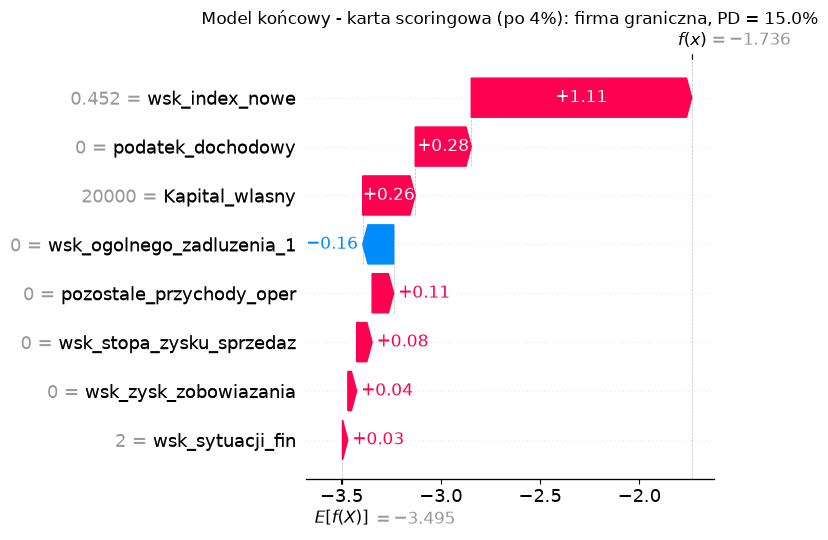

,wartość,punkty,utracone vs maksimum,SHAP karty
wsk_index_nowe,0.452055,41.1,53.9,1.111
podatek_dochodowy,0.0,61.2,26.7,0.282
Kapital_wlasny,20000.0,61.0,18.4,0.264
wsk_stopa_zysku_sprzedaz,0.0,65.9,9.7,0.078
pozostale_przychody_oper,0.0,64.5,6.3,0.109
wsk_zysk_zobowiazania,0.0,66.3,4.5,0.044
wsk_sytuacji_fin,2.0,66.8,3.3,0.027
wsk_ogolnego_zadluzenia_1,0.0,73.5,0.0,-0.156


In [59]:
pd_kon_te = P4["logit"]["test"]
I_GRAN = int(np.argmin(np.abs(pd_kon_te - PROG["logit"])))
phi0_kon = BAZA_LOG + DELTA["logit"]
print(f"Firma graniczna: wiersz testu {I_GRAN}, PD końcowe {pd_kon_te[I_GRAN]:.2%} (próg {PROG['logit']:.1%}), "
      f"rating {R['logit']['test'][I_GRAN]}, default = {y_te[I_GRAN]} | black-box: PD po 4% {P4['black-box']['test'][I_GRAN]:.2%}")
print(f"Kontrola: φ₀ + δ + Σφ = {phi0_kon + PHI_LOG.iloc[I_GRAN].sum():+.3f} | logit PD końcowego = {_z(pd_kon_te[I_GRAN:I_GRAN + 1])[0]:+.3f}")
shap.plots.waterfall(shap.Explanation(values=PHI_LOG.iloc[I_GRAN].to_numpy(), base_values=phi0_kon,
                                      data=X_te.iloc[I_GRAN][CECHY_L].to_numpy(dtype=object), feature_names=CECHY_L), max_display=10, show=False)
plt.title(f"Model końcowy - karta scoringowa (po 4%): firma graniczna, PD = {pd_kon_te[I_GRAN]:.1%}"); plt.tight_layout()
plt.savefig("wykresy/waterfall_graniczna_4proc.png", dpi=110, bbox_inches="tight"); plt.show()
display(punkty_vs_max(I_GRAN))

**Wnioski:** firma graniczna dla progu operacyjnego karty (wiersz 318) ma PD końcowe 14,99% przy progu 15,0% - zostaje przyjęta; rating B,
bez defaultu (black-box daje jej PD 12,9%, też poniżej swojego progu). W modelu końcowym wartość bazowa to φ₀ + δ ≈ -3,50 log-szans
(PD ≈ 2,9%), a suma wkładów +1,76 podnosi PD do 15,0% (kontrola addytywności zgodna). Wkłady φ są te same co przed δ, więc **powody
decyzji nie zależą od kalibracji** - zmienia się tylko punkt odniesienia. Główny powód to wskaźnik branżowy `wsk_index_nowe` (0,45: +1,11,
mnożnik szans 3,0; 53,9 pkt mniej od maksimum) - ok. 63% sumy wkładów, na który firma nie ma wpływu. Dalej czynniki firmy: zerowy podatek,
czyli brak zysku (+0,28; 26,7 pkt straty), mały kapitał własny (20 tys. zł, +0,26; 18,4 pkt), zerowe pozostałe przychody operacyjne (+0,11)
i zerowa rentowność sprzedaży (+0,08). Ryzyko obniża tylko brak zadłużenia (`wsk_ogolnego_zadluzenia_1` = 0: -0,16, maksimum punktów).
Kody przyczyn dla klienta powinny oddzielać czynniki branżowe od tych, które firma może poprawić.

### 12.4 Tabela decyzyjna: wpływ progu na wyniki biznesowe (karta, test)

In [60]:
tab_dec = pd.DataFrame([ekonomia(y_te, P4["logit"]["test"], t) for t in [0.03, 0.05, 0.08, 0.12, PROG["logit"], 0.20, 1.01]]).set_index("próg")
display(tab_dec.round(3))

,stopa akceptacji,DR wśród przyjętych,TP (odrzucone złe),FP (odrzucone dobre),FN (przyjęte złe),TN (przyjęte dobre),EL przyjętych (oczekiwana),strata zrealizowana,zysk
próg,,,,,,,,,
0.03,0.548,0.055,71.0,200.0,18.0,310.0,2.050,8.10,22.90
0.05,0.661,0.073,60.0,143.0,29.0,367.0,3.225,13.05,23.65
0.08,0.776,0.082,51.0,83.0,38.0,427.0,5.112,17.10,25.60
0.12,0.866,0.094,40.0,40.0,49.0,470.0,7.532,22.05,24.95
0.15,0.908,0.108,30.0,25.0,59.0,485.0,9.036,26.55,21.95
0.20,0.965,0.130,14.0,7.0,75.0,503.0,11.573,33.75,16.55
1.01,1.000,0.149,0.0,0.0,89.0,510.0,14.345,40.05,10.95


**Wnioski:** tabela dotyczy karty na teście bez przeważenia (portfel jak próba, DR 14,9%) i PD po δ. Obniżanie progu z 20% do 3% zmniejsza
stopę akceptacji z 96,5% do 54,8% i DR wśród przyjętych z 13,0% do 5,5%. Na takim portfelu zysk jest najwyższy przy progu 8% (25,6),
a przy progu operacyjnym 15% wynosi 22,0 - bo PD po δ jest zaniżone względem DR próby, a próg 15% wybrano dla portfela 4% (12.3).
Przy marży 10% i LGD 45% jeden uniknięty default „równoważy” odrzucenie 4,5 dobrej firmy: między progami 8% a 3% odrzucamy 20 złych
więcej, ale aż 117 dobrych więcej - zysk spada z 25,6 do 22,9. Tabela pokazuje, jak wrażliwy jest próg na założenie o DR portfela.

### 12.5 Porównanie decyzji: karta a black-box (test)

In [61]:
dec = {m: np.where(P4[m]["test"] < PROG[m], "przyjęty", "odrzucony") for m in P}
display(pd.crosstab(pd.Series(dec["logit"], name="karta"), pd.Series(dec["black-box"], name="black-box"), margins=True))
krz = pd.crosstab(pd.Series(R["logit"]["test"], name="rating karty"), pd.Series(R["black-box"]["test"], name="rating black-boxa"))
display(krz)
kod_l, kod_b = np.asarray(R["logit"]["test"].codes), np.asarray(R["black-box"]["test"].codes)
niezg = dec["logit"] != dec["black-box"]
print(f"Zgodność decyzji: {np.mean(~niezg):.1%} | ten sam rating: {np.mean(kod_l == kod_b):.1%} | różnica ≤ 1 klasa: {np.mean(np.abs(kod_l - kod_b) <= 1):.1%}")
tylko_l, tylko_b = (dec["logit"] == "odrzucony") & (dec["black-box"] == "przyjęty"), (dec["logit"] == "przyjęty") & (dec["black-box"] == "odrzucony")
print(f"Firmy z różną decyzją: {niezg.sum()} | odrzucone tylko przez kartę: {tylko_l.sum()} (DR {y_te[tylko_l].mean() if tylko_l.any() else np.nan:.1%}), "
      f"tylko przez black-box: {tylko_b.sum()}")

black-box,odrzucony,przyjęty,All
karta,,,
odrzucony,24,31,55
przyjęty,15,529,544
All,39,560,599


rating black-boxa,AAA,AA,A,BBB,BB,B,CCC
rating karty,,,,,,,
AAA,109,15,3,1,0,0,0
AA,60,29,25,3,0,1,0
A,16,45,60,22,4,2,1
BBB,1,4,26,18,16,4,0
BB,0,0,9,9,14,15,7
B,0,0,8,4,6,27,14
CCC,0,0,0,1,0,2,18


Zgodność decyzji: 92.3% | ten sam rating: 45.9% | różnica ≤ 1 klasa: 88.5%
Firmy z różną decyzją: 46 | odrzucone tylko przez kartę: 31 (DR 41.9%), tylko przez black-box: 15


Progi z valid się różnią (15,0% i 20,5%), a karta odrzuca więcej firm (55 vs 39), więc porównanie powyżej miesza dwie rzeczy: jakość rankingu i
wybór progu. Dlatego porównujemy też decyzje **przy tej samej stopie akceptacji** - każdy model odrzuca ten sam odsetek
najgorszych firm (stopa black-boxa i stopa karty z progów z valid).

In [62]:
wiersze = []
for stopa in [np.mean(P4["black-box"]["test"] < PROG["black-box"]), np.mean(P4["logit"]["test"] < PROG["logit"])]:
    d_ = {}
    for m in P:
        prog_m = np.quantile(P4[m]["test"], stopa)
        d_[m] = P4[m]["test"] < prog_m
        wiersze.append({"stopa akceptacji": round(stopa, 3), "model": m, **{k: v for k, v in ekonomia(y_te, P4[m]["test"], prog_m).items() if k != "próg"}})
    wiersze[-1]["zgodność decyzji"] = wiersze[-2]["zgodność decyzji"] = np.mean(d_["logit"] == d_["black-box"])
display(pd.DataFrame(wiersze).set_index(["stopa akceptacji", "model"]).round(3))

DR wśród przyjętych  TP (odrzucone złe)  \
stopa akceptacji model                                                
0.926544         logit                    0.119                23.0   
0.934891         black-box                0.111                27.0   
0.908180         logit                    0.108                30.0   
                 black-box                0.103                33.0   

                            FP (odrzucone dobre)  FN (przyjęte złe)  \
stopa akceptacji model                                                
0.926544         logit                      21.0               66.0   
0.934891         black-box                  12.0               62.0   
0.908180         logit                      25.0               59.0   
                 black-box                  22.0               56.0   

                            TN (przyjęte dobre)  EL przyjętych (oczekiwana)  \
stopa akceptacji model                                                        
0.926544         logit                    489.0                       9.795   
0.934891         black-box                498.0                       9.902   
0.908180         logit                    485.0                       9.036   
                 black-box                488.0                       8.566   

                            strata zrealizowana   zysk  zgodność decyzji  
stopa akceptacji model                                                    
0.926544         logit                    29.70  19.20             0.938  
0.934891         black-box                27.90  21.90             0.938  
0.908180         logit                    26.55  21.95             0.923  
                 black-box                25.20  23.60             0.923

**Wnioski:** przy progach z valid decyzje obu modeli zgadzają się dla 92,3% firm testu; z 46 różnych decyzji 31 to firmy odrzucone
tylko przez kartę (DR 41,9%, prawie trzy razy więcej niż w całym teście), a 15 - tylko przez black-box. Przy tej samej stopie akceptacji
co black-box (93,5%; karta przez remisy punktów przyjmuje 92,7%) zgodność wynosi 93,8%, a black-box odrzuca więcej złych (27 vs 23) i mniej
dobrych firm (12 vs 21) - zysk 21,9 vs 19,2 (test bez przeważenia); przy akceptacji karty (90,8%) zgodność wynosi 92,3%, a zysk 23,6 vs 22,0.
Ratingi: ten sam dla 46% firm, różnica najwyżej o jedną klasę dla 89%. Różnice decyzji dotyczą kilkudziesięciu firm w ogonie rozkładu
i są zgodne z niewielką przewagą rankingu black-boxa.

### 12.6 Global surrogate: płytkie drzewo naśladujące black-box (Lab 6)

Drzewo regresyjne uczone na **log-szansach black-boxa** w train (nie na defaultach) - opisuje model, nie dane. Wierność na
teście: R² między log-szansami drzewa i black-boxa, zgodność decyzji przy progu operacyjnym z 12.3, **odsetek firm odrzuconych
przez black-box, które odrzuca też drzewo** (ważniejszy niż zgodność ogółem, bo większość firm jest przyjmowana) i zgodność
klas ratingowych. PD drzewa przechodzi ten sam łańcuch kalibracji i przesunięcia do 4% co black-box. Surogat służy tylko do
komunikacji (reguły dla komitetu kredytowego) - nie do decyzji.

In [63]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import r2_score

Z_tr_s, Z_te_s = pre_bb.transform(X_tr), pre_bb.transform(X_te)
f_tr_s, f_te_s = _z(P["black-box"]["train"]), _z(P["black-box"]["test"])      # log-szanse black-boxa
NAZWY_S = [n.split("__", 1)[1] for n in nazwy_bb]
pd_z_logit = lambda g: expit(_z(zastosuj(METODA["black-box"], KAL["black-box"], expit(g))) + DELTA["black-box"])
odrz_bb = P4["black-box"]["test"] >= PROG["black-box"]
klasy_bb = np.asarray(R["black-box"]["test"]).astype(str)

def surogat(glebokosc):                                       # z Lab 6 (4); min. liść 50 firm (train ma 1 800 firm)
    return DecisionTreeRegressor(max_depth=glebokosc, min_samples_leaf=50, random_state=RNG_SEED).fit(Z_tr_s, f_tr_s)

wiersze = []
for d in [2, 3, 4, 5, 6, 8]:
    s = surogat(d); g_te = s.predict(Z_te_s); pd_s = pd_z_logit(g_te)
    wiersze.append({"głębokość": d, "liczba liści": s.get_n_leaves(), "wierność R² (test)": r2_score(f_te_s, g_te),
                    "zgodność decyzji": np.mean((pd_s >= PROG["black-box"]) == odrz_bb),
                    "odrzuceni przez black-box - odrzuceni też przez surogat": np.mean(pd_s[odrz_bb] >= PROG["black-box"]) if odrz_bb.any() else np.nan,
                    "zgodność klas ratingowych": np.mean(np.asarray(rating(pd_s)).astype(str) == klasy_bb),
                    "Gini surogatu (test)": 2 * roc_auc_score(y_te, g_te) - 1})
TAB_SUR = pd.DataFrame(wiersze).set_index("głębokość")
display(TAB_SUR.round(3))
print(f"Firm odrzuconych przez black-box na teście: {odrz_bb.sum()} | Gini (test): black-box {2 * roc_auc_score(y_te, f_te_s) - 1:.3f}, "
      f"karta {2 * roc_auc_score(y_te, P['logit']['test']) - 1:.3f}")

,liczba liści,wierność R² (test),zgodność decyzji,odrzuceni przez black-box - odrzuceni też przez surogat,zgodność klas ratingowych,Gini surogatu (test)
głębokość,,,,,,
2,4,0.525,0.935,0.000,0.412,0.350
3,8,0.631,0.950,0.359,0.399,0.426
4,16,0.700,0.947,0.205,0.426,0.489
5,22,0.733,0.947,0.205,0.491,0.493
6,28,0.737,0.947,0.205,0.477,0.473
8,28,0.737,0.947,0.205,0.477,0.473


Firm odrzuconych przez black-box na teście: 39 | Gini (test): black-box 0.583, karta 0.562


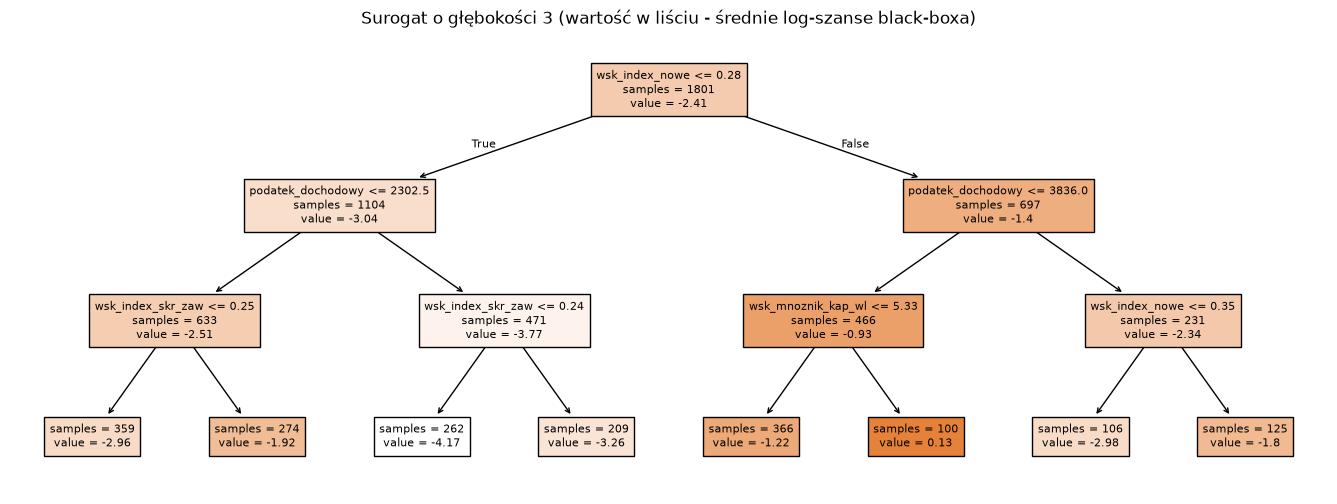

,reguła,udział firm (train),PD modelu końcowego
0,wsk_index_nowe ≤ 0.282 i podatek_dochodowy > 2.3e+03 i wsk_index_skr_zaw ≤ 0.24,0.145,0.005
1,wsk_index_nowe ≤ 0.282 i podatek_dochodowy > 2.3e+03 i wsk_index_skr_zaw > 0.24,0.116,0.011
2,wsk_index_nowe > 0.282 i podatek_dochodowy > 3.84e+03 i wsk_index_nowe ≤ 0.352,0.059,0.015
3,wsk_index_nowe ≤ 0.282 i podatek_dochodowy ≤ 2.3e+03 i wsk_index_skr_zaw ≤ 0.252,0.199,0.015
4,wsk_index_nowe ≤ 0.282 i podatek_dochodowy ≤ 2.3e+03 i wsk_index_skr_zaw > 0.252,0.152,0.042
5,wsk_index_nowe > 0.282 i podatek_dochodowy > 3.84e+03 i wsk_index_nowe > 0.352,0.069,0.047
6,wsk_index_nowe > 0.282 i podatek_dochodowy ≤ 3.84e+03 i wsk_mnoznik_kap_wl ≤ 5.33,0.203,0.080
7,wsk_index_nowe > 0.282 i podatek_dochodowy ≤ 3.84e+03 i wsk_mnoznik_kap_wl > 5.33,0.056,0.253


In [64]:
def reguly(drzewo, nazwy):                                    # z Lab 6 (4)
    # liście drzewa jako reguły „jeżeli ... to PD” (braki danych: kierunek wyuczony przez drzewo, pomijany w opisie)
    t, wyn = drzewo.tree_, []
    def idz(w, war):
        if t.children_left[w] == -1:
            wyn.append({"reguła": " i ".join(war), "udział firm (train)": t.n_node_samples[w] / t.n_node_samples[0],
                        "PD modelu końcowego": float(pd_z_logit(np.array([t.value[w][0][0]]))[0])})
            return
        c, prog = nazwy[t.feature[w]], t.threshold[w]
        idz(t.children_left[w], war + [f"{c} ≤ {prog:.3g}"]); idz(t.children_right[w], war + [f"{c} > {prog:.3g}"])
    idz(0, [])
    return pd.DataFrame(wyn).sort_values("PD modelu końcowego").reset_index(drop=True)

sur3 = surogat(3)
fig, ax = plt.subplots(figsize=(17, 6))
plot_tree(sur3, feature_names=NAZWY_S, filled=True, impurity=False, precision=2, fontsize=8, ax=ax)
ax.set_title("Surogat o głębokości 3 (wartość w liściu - średnie log-szanse black-boxa)")
plt.savefig("wykresy/surogat.png", dpi=110, bbox_inches="tight"); plt.show()
with pd.option_context("display.max_colwidth", 140):
    display(reguly(sur3, NAZWY_S).round(3))

**Wnioski:**
- Wierność rośnie z głębokością: R² 0,53 (głębokość 2), 0,63 (3), 0,70 (4) i ok. 0,73-0,74 (5-8, nasycenie przy min. 50 firmach w liściu).
- Zgodność decyzji ogółem (93,5-95%) jest myląca, bo black-box odrzuca tylko 39 z 599 firm. Kluczowa miara - **odsetek odrzuconych przez
  black-box, których odrzuca też surogat** - wynosi 0% dla głębokości 2, 35,9% dla głębokości 3 i 20,5% dla głębszych drzew: surogat
  odtwarza ogólny kształt log-szans, ale nie granicę decyzji w ogonie. Zgodność klas ratingowych to tylko 40-49%.
- Drzewo o głębokości 3 daje czytelne reguły: pierwszy podział to `wsk_index_nowe` ≤ 0,282, dalej podatek dochodowy (2,3 tys. zł
  i 3,84 tys. zł), `wsk_index_skr_zaw` (ok. 0,24-0,25), ponownie `wsk_index_nowe` (0,352) i `wsk_mnoznik_kap_wl` (5,33). Najwyższe PD
  (25,3%, powyżej progów obu modeli) ma liść: wysokie `wsk_index_nowe`, podatek ≤ 3,84 tys. zł i `wsk_mnoznik_kap_wl` > 5,33 (6% firm).
- Gini surogatu (0,43 przy głębokości 3, maks. 0,49) jest niższy niż karty (0,562) - **surogat nie zastępuje karty**; służy tylko do
  opisu black-boxa i potwierdza, że jego główna logika to branża, zysk i struktura finansowania.

## 13. Analiza kontrfaktyczna

**Pytanie:** jakie możliwie najmniejsze zmiany sytuacji finansowej poprawiłyby rating firmy o jedną klasę (BB → BBB)?

**Zależności między cechami.** Black-box używa 179 wskaźników, z których wiele to warianty tej samej miary (3.3).
Zmiana jednego wskaźnika przy stałych pozostałych tworzy firmę, która nie istnieje (np. inne zadłużenie ogólne, ale to samo
zadłużenie krótkoterminowe). Dlatego zmieniamy **dźwignie** - grupy cech skorelowanych |ρ| ≥ 0,7 z cechą karty (7.3).
Wszystkie cechy dźwigni przesuwamy o tę samą liczbę **percentyli rozkładu z train** w kierunku niższego ryzyka.
Cechy niezmienne (sekcja PKD, forma własności, wielkość, wiek firmy, wskaźniki branżowe `wsk_index_*`) zostają bez zmian. Podatek dochodowy
też nie jest dźwignią: to skutek wyniku finansowego, nie decyzja firmy, a zmiana podatku bez zmiany zysku tworzy firmę niemożliwą
księgowo. Wynik firmy zmieniamy dźwignią zysku (`wsk_zysk_zobowiazania`), a podatek idzie za nim: rośnie o 19% (CIT) przyrostu
dodatniego zysku brutto. Koszt zmiany = suma przesunięć w percentylach.

In [65]:
from scipy.stats import rankdata
R_TR = {c: np.sort(X_tr[c].dropna().to_numpy()) for c in num_cols}

def przesun(x, c, delta_pct, kier):
    # przesunięcie wartości cechy c o delta_pct percentyli w kierunku kier (+1 w górę, -1 w dół) rozkładu z train
    if pd.isna(x):
        return x
    r = np.searchsorted(R_TR[c], x, side="right") / len(R_TR[c])
    return float(np.quantile(R_TR[c], np.clip(r + kier * delta_pct, 0, 1)))

KIER_RYZYKA = {c: OCZEKIWANY[c] for c in CECHY_L}            # +1: wyższa wartość = wyższe ryzyko
NIE_DZWIGNIE = set(WSK_INDEX) | {"podatek_dochodowy"}        # branża - poza wpływem firmy; podatek - skutek wyniku, nie decyzja
DZWIGNIE = {}
for c in [c for c in CECHY_L if c not in NIE_DZWIGNIE]:
    czl = [f for f in num_cols if abs(kor_tr.loc[c, f]) >= 0.7 and f not in NIE_DZWIGNIE]
    DZWIGNIE[c] = {f: -KIER_RYZYKA[c] * int(np.sign(kor_tr.loc[c, f])) for f in czl}    # kierunek zmiany obniżający ryzyko
display(pd.DataFrame({"liczba cech w dźwigni": {c: len(v) for c, v in DZWIGNIE.items()},
                      "kierunek zmiany cechy wiodącej": {c: "w górę" if v[c] > 0 else "w dół" for c, v in DZWIGNIE.items()}}))

def jako_df(x):
    return x.to_frame().T.astype(X_te.dtypes.to_dict())

def zastosuj_dzwignie(x, zmiany):
    x = x.copy()
    for d, delta in zmiany.items():
        zb0 = x.get("zysk_brutto")
        for f, kier in DZWIGNIE[d].items():
            x[f] = przesun(x[f], f, delta, kier)
        if "zysk_brutto" in DZWIGNIE[d] and pd.notna(zb0) and pd.notna(x["podatek_dochodowy"]):
            # podatek idzie za zyskiem: 19% CIT od przyrostu dodatniego zysku brutto
            x["podatek_dochodowy"] += 0.19 * max(0.0, max(x["zysk_brutto"], 0.0) - max(zb0, 0.0))
    return x

oba_bb = (np.asarray(R["black-box"]["test"]).astype(str) == "BB") & (np.asarray(R["logit"]["test"]).astype(str) == "BB")
kandydaci_bb = np.where(oba_bb)[0] if oba_bb.any() else np.where(np.asarray(R["black-box"]["test"]).astype(str) == "BB")[0]   # BB w obu modelach
i_cf = int(kandydaci_bb[np.argmin(np.abs(P4["black-box"]["test"][kandydaci_bb] - 0.10))])            # BB, PD w środku klasy
print(f"Firm z ratingiem BB w obu modelach: {oba_bb.sum()}")
x_cf = X_te.iloc[i_cf]
print(f"Firma: wiersz testu {i_cf}, PD po 4% = {P4['black-box']['test'][i_cf]:.2%}, rating {R['black-box']['test'][i_cf]}, "
      f"karta: PD = {P4['logit']['test'][i_cf]:.2%}, rating {R['logit']['test'][i_cf]}, default = {y_te[i_cf]}")
display(x_cf[CECHY_L].to_frame("wartość").T)

,liczba cech w dźwigni,kierunek zmiany cechy wiodącej
Kapital_wlasny,8,w górę
wsk_ogolnego_zadluzenia_1,18,w dół
wsk_zysk_zobowiazania,31,w górę
wsk_stopa_zysku_sprzedaz,2,w górę
wsk_sytuacji_fin,1,w górę
pozostale_przychody_oper,4,w górę


Firm z ratingiem BB w obu modelach: 14
Firma: wiersz testu 574, PD po 4% = 10.01%, rating BB, karta: PD = 8.45%, rating BB, default = 0


,wsk_index_nowe,podatek_dochodowy,Kapital_wlasny,wsk_ogolnego_zadluzenia_1,wsk_zysk_zobowiazania,wsk_stopa_zysku_sprzedaz,wsk_sytuacji_fin,pozostale_przychody_oper
wartość,0.361512,0.0,230990.74,0.0,0.0,-15.375,23.099074,0.0


In [66]:
KROKI = np.round(np.arange(0.05, 0.81, 0.05), 2)
wyniki_cf = []
for d in DZWIGNIE:                                            # pojedyncze dźwignie
    for delta in KROKI:
        p = pd_koncowe(zastosuj_dzwignie(x_cf, {d: delta}).pipe(jako_df))[0]
        wyniki_cf.append({"dźwignie": d, "przesunięcie (percentyle)": f"{delta:.2f}", "koszt": delta, "PD": p, "rating": rating([p])[0]})
for d1, d2 in itertools.combinations(DZWIGNIE, 2):           # pary dźwigni, równe przesunięcia
    for delta in KROKI[:8]:
        p = pd_koncowe(zastosuj_dzwignie(x_cf, {d1: delta, d2: delta}).pipe(jako_df))[0]
        wyniki_cf.append({"dźwignie": f"{d1} + {d2}", "przesunięcie (percentyle)": f"{delta:.2f} + {delta:.2f}", "koszt": 2 * delta, "PD": p, "rating": rating([p])[0]})
cf = pd.DataFrame(wyniki_cf)
cel = cf[cf["rating"].astype(str).isin(["BBB", "A", "AA", "AAA"])]
najtansze = cel.sort_values("koszt").groupby("dźwignie").head(1).sort_values("koszt").head(8)
display(najtansze.round(4))

,dźwignie,przesunięcie (percentyle),koszt,PD,rating
33,wsk_zysk_zobowiazania,0.10,0.1,0.0770,BBB
177,wsk_zysk_zobowiazania + wsk_sytuacji_fin,0.10 + 0.10,0.2,0.0765,BBB
169,wsk_zysk_zobowiazania + wsk_stopa_zysku_sprzedaz,0.10 + 0.10,0.2,0.0753,BBB
105,Kapital_wlasny + wsk_zysk_zobowiazania,0.10 + 0.10,0.2,0.0766,BBB
137,wsk_ogolnego_zadluzenia_1 + wsk_zysk_zobowiazania,0.10 + 0.10,0.2,0.0736,BBB
186,wsk_zysk_zobowiazania + pozostale_przychody_oper,0.15 + 0.15,0.3,0.0740,BBB
164,wsk_ogolnego_zadluzenia_1 + pozostale_przychod...,0.25 + 0.25,0.5,0.0785,BBB
132,Kapital_wlasny + pozostale_przychody_oper,0.25 + 0.25,0.5,0.0759,BBB


**Wnioski:** analizujemy firmę z ratingiem BB w obu modelach (14 takich firm na teście; wybrana - wiersz 574: PD 10,0% w black-boxie
i 8,5% w karcie, bez defaultu). Najtańsza zmiana to dźwignia **zysku względem zobowiązań** (31 miar zysku i rentowności): przesunięcie
o 10 percentyli poprawia rating z BB na BBB (PD 10,0% → 7,7%). Pary z tą dźwignią po 10 percentyli (z zadłużeniem, rentownością
sprzedaży, kapitałem własnym albo `wsk_sytuacji_fin`, PD 7,4-7,7%) są droższe. Pary bez dźwigni zysku wymagają po 25 percentyli,
a żadna inna dźwignia sama nie wystarcza w badanym zakresie (do 80 percentyli). Wskaźniki branżowe są niezmienne, a podatek zmienia się
tylko razem z zyskiem.

### 13.1 Realność kontrfaktu i porównanie z SHAP / LIME

Realność sprawdzamy w przybliżeniu: odległością do najbliższej prawdziwej firmy z train (w przestrzeni rang percentylowych
20 najważniejszych cech black-boxa), w porównaniu z typową odległością firm testowych do train. Miara nie sprawdza tożsamości
księgowych między pozycjami sprawozdania.

In [67]:
from sklearn.neighbors import NearestNeighbors
TOP20 = [c for c in TOP_BB if c in num_cols][:20] + [c for c in waz_shap_bb.index if c in num_cols and c not in TOP_BB][:max(0, 20 - len([c for c in TOP_BB if c in num_cols]))]
def rangi_pct(Xw):
    return np.column_stack([np.searchsorted(R_TR[c], Xw[c].fillna(np.nanmedian(R_TR[c])).to_numpy(), side="right") / len(R_TR[c]) for c in TOP20])
nn = NearestNeighbors(n_neighbors=1).fit(rangi_pct(X_tr))
odl_typowe = nn.kneighbors(rangi_pct(X_te))[0].ravel()
najl_cf = najtansze.iloc[0]
zm = {d.strip(): float(v) for d, v in zip(najl_cf["dźwignie"].split("+"), najl_cf["przesunięcie (percentyle)"].split("+"))}
x_nowe = zastosuj_dzwignie(x_cf, zm)
odl_cf = nn.kneighbors(rangi_pct(x_nowe.pipe(jako_df)))[0][0, 0]
print(f"Najtańszy kontrfakt: {najl_cf['dźwignie']} o {najl_cf['przesunięcie (percentyle)']} percentyli -> PD {najl_cf['PD']:.2%}, rating {najl_cf['rating']}")
print(f"Odległość do najbliższej firmy z train: kontrfakt {odl_cf:.3f} | firmy testowe: mediana {np.median(odl_typowe):.3f}, 90. percentyl {np.percentile(odl_typowe, 90):.3f}")
kol_cf = list(DZWIGNIE[list(zm)[0]])[:8] + ["podatek_dochodowy"]
display(pd.DataFrame({"przed": x_cf[kol_cf], "po": x_nowe[kol_cf]}).round(3))

s_shap = pd.Series(PHI_BB[i_cf], index=FEATURES)
e_cf = lime_wyjasnij(i_cf)
s_lime = lime_wklady(e_cf, L_TE[i_cf])
dz_shap = pd.Series({d: s_shap[list(DZWIGNIE[d])].sum() for d in DZWIGNIE})
dz_lime = pd.Series({d: s_lime.reindex(list(DZWIGNIE[d])).fillna(0).sum() for d in DZWIGNIE})
display(pd.DataFrame({"suma SHAP cech dźwigni": dz_shap, "suma wkładów LIME cech dźwigni": dz_lime,
                      "najtańszy kontrfakt z tą dźwignią (koszt)": cel.groupby("dźwignie")["koszt"].min().reindex(list(DZWIGNIE))}).round(3))

Najtańszy kontrfakt: wsk_zysk_zobowiazania o 0.10 percentyli -> PD 7.70%, rating BBB
Odległość do najbliższej firmy z train: kontrfakt 0.534 | firmy testowe: mediana 0.555, 90. percentyl 0.717


,przed,po
Zysk_netto,0.0,19189.479289
zysk_brutto,0.0,20381.347562
zysk_netto,0.0,16749.217435
wsk_marza_brutto_1,0.0,0.021269
wsk_marza_brutto_2,0.0,0.02237
wsk_ROS,0.0,0.01946
wsk_ROA,0.0,0.024692
wsk_s_ROA,0.0,0.025956
podatek_dochodowy,0.0,3872.456037


,suma SHAP cech dźwigni,suma wkładów LIME cech dźwigni,najtańszy kontrfakt z tą dźwignią (koszt)
Kapital_wlasny,0.049,0.004,NaN
wsk_ogolnego_zadluzenia_1,-0.021,0.009,NaN
wsk_zysk_zobowiazania,0.074,0.000,0.1
wsk_stopa_zysku_sprzedaz,0.108,0.000,NaN
wsk_sytuacji_fin,-0.076,0.000,NaN
pozostale_przychody_oper,0.030,0.000,NaN


**Wnioski:**
- Dźwignia zysku to w praktyce **wyjście z zerowego wyniku na niewielki zysk**: zysk brutto z 0 do ok. 20,4 tys. zł, podatek z 0 do
  ok. 3,9 tys. zł (19%), zysk netto z 0 do ok. 16,7 tys. zł (wariant `Zysk_netto`: 19,2 tys. zł), ROS z 0 do 0,02, ROA z 0 do 0,02.
- Kontrfakt jest bliżej prawdziwych firm niż typowa firma testowa (0,53 vs mediana 0,55; 90. percentyl 0,72), więc w przestrzeni
  rang 20 cech nie jest nietypowy. To jednak nie dowodzi, że firma jest możliwa: odległość nie sprawdza tożsamości księgowych.
  Zysk brutto, podatek i zysk netto są w przybliżeniu spójne, ale dwa warianty zysku netto się rozchodzą (16,7 i 19,2 tys. zł),
  a cechy innych dźwigni (np. `wsk_stopa_zysku_sprzedaz` = -15,4) się nie zmieniają. **Wynik należy traktować jako kierunek, nie gwarancję.**
- Porównanie z SHAP: największą sumę SHAP ma dźwignia rentowności sprzedaży (+0,11), dalej zysku względem zobowiązań (+0,07) i kapitału
  własnego (+0,05), a `wsk_sytuacji_fin` obniża ryzyko (-0,08). Rentowność sprzedaży sama nie wystarcza nawet przy 80 percentylach -
  **ranking SHAP nie jest rankingiem najtańszych zmian**: SHAP mówi, co podnosi ryzyko względem przeciętnej firmy, kontrfakt - gdzie
  najbliżej jest próg modelu. LIME przypisuje cechom dźwigni prawie zerowe wagi (|w| ≤ 0,01) - kolejny przykład niskiej wierności LIME (10.2).
- Ograniczenia: kontrfakt opisuje model, nie przyczynowość; nie uwzględnia kosztu i wykonalności zmiany ani reakcji innych pozycji
  sprawozdania; przy skorelowanych cechach zależy od definicji dźwigni.

### 13.2 Kontrfakt w karcie scoringowej

W karcie odpowiedź jest dokładna: rating zależy od sumy punktów, więc wystarczy policzyć, ile punktów brakuje do granicy
klasy BBB i które przejście do sąsiedniego przedziału daje najwięcej punktów.

In [68]:
pd_lim = RATING_BINS[RATING_LABELS.index("BB")]                 # granica BBB / BB
p_l = P4["logit"]["test"][i_cf]
z0 = baseline.decision_function(X_te.iloc[[i_cf]][CECHY_L])[0]
pd_z_modelu = lambda t: expit(_z(zastosuj(METODA["logit"], KAL["logit"], np.array([expit(z0 + t)]))) + DELTA["logit"])[0] - (pd_lim - 1e-4)
dz = brentq(pd_z_modelu, -10, 0) if p_l >= pd_lim else 0.0    # wymagana zmiana logitu karty (łańcuch kalibracji uwzględniony)
potrzebne_pkt = -factor * dz
wiersze = []
kody_cf = woe_l.codes(X_te.iloc[[i_cf]][CECHY_L]).iloc[0]
for c in [c for c in CECHY_L if c not in NIE_DZWIGNIE]:
    tab = woe_l.tables_[c]; k = int(kody_cf[c])
    for k2 in range(len(tab)):
        if k2 == k or tab["przedział"].iloc[k2] == "BRAK":
            continue
        d_pkt = factor * (-betas[c]) * (tab["WoE"].iloc[k2] - tab["WoE"].iloc[k])
        if d_pkt > 0:
            wiersze.append({"cecha": c, "z przedziału": tab["przedział"].iloc[k], "do przedziału": tab["przedział"].iloc[k2],
                            "skok przedziałów": abs(k2 - k), "zmiana punktów": d_pkt, "wystarczy sama": d_pkt >= potrzebne_pkt})
ruchy = pd.DataFrame(wiersze).sort_values(["skok przedziałów", "zmiana punktów"], ascending=[True, False])
print(f"Karta: PD po 4% = {p_l:.2%} ({R['logit']['test'][i_cf]}) | do ratingu BBB potrzeba PD < {pd_lim:.0%}, "
      f"czyli {potrzebne_pkt:.1f} pkt więcej (wynik {wynik_model[i_cf]:.0f} -> {wynik_model[i_cf] + potrzebne_pkt:.0f} pkt)")
display(ruchy.head(8).round(1))

Karta: PD po 4% = 8.45% (BB) | do ratingu BBB potrzeba PD < 8%, czyli 1.7 pkt więcej (wynik 519 -> 521 pkt)


,cecha,z przedziału,do przedziału,skok przedziałów,zmiana punktów,wystarczy sama
0,Kapital_wlasny,[1.176e+05; 1.685e+06),[1.685e+06; inf),1,8.4,True
3,wsk_stopa_zysku_sprzedaz,[-inf; -8.79),[-8.79; -0.4397),1,2.8,True
1,wsk_zysk_zobowiazania,[0; 0.04593),[0.04593; 0.1627),1,1.8,True
7,pozostale_przychody_oper,[-inf; 19),[19; 2009),1,0.6,False
4,wsk_stopa_zysku_sprzedaz,[-inf; -8.79),[-0.4397; 0.006048),2,6.9,True
8,pozostale_przychody_oper,[-inf; 19),[2009; 7500),2,5.4,True
2,wsk_zysk_zobowiazania,[0; 0.04593),[0.1627; inf),2,4.5,True
5,wsk_stopa_zysku_sprzedaz,[-inf; -8.79),[0.006048; 0.03185),3,11.3,True


**Wnioski:** karta daje tej firmie PD 8,45% (BB), tuż nad granicą klasy; do BBB brakuje 1,7 pkt (519 → 521 pkt). Wystarczają trzy pojedyncze
przejścia do sąsiedniego przedziału: **kapitał własny** powyżej 1,685 mln zł (+8,4 pkt; firma ma 231 tys. zł, więc to zmiana ok. 7-krotna),
**rentowność sprzedaży** z poniżej -8,79 do [-8,79; -0,44) (+2,8 pkt; firma ma -15,4) i **zysk względem zobowiązań** z [0; 0,046)
do [0,046; 0,163) (+1,8 pkt). Pozostałe przychody operacyjne (+0,6 pkt) same nie wystarczają, a zadłużenie jest już w najlepszym
przedziale. Oba modele wskazują dźwignię zysku jako wystarczającą samodzielnie; karta nagradza też poprawę rentowności sprzedaży
albo kapitału własnego, a w black-boxie te dźwignie same nie wystarczają w badanym zakresie. Karta podaje odpowiedź dokładną i łatwą do zakomunikowania klientowi.

## 14. Audyt podgrup, monitoring i podsumowanie

### 14.1 Szybki audyt podgrup (test)

Dane nie zawierają cech osób fizycznych (płeć, wiek), więc audyt dotyczy segmentów firm: wielkości jednostki, sekcji PKD
i formy własności. Przy kilkunastu defaultach w grupie różnice mogą być przypadkowe - AUC liczymy tylko przy ≥ 10 defaultach.

In [69]:
def audyt(kol, maks_grup=6):
    g_te = X_te[kol].where(X_te[kol].isin(X_te[kol].value_counts().index[:maks_grup]), "INNE")
    rows = []
    for g in g_te.unique():
        msk = (g_te == g).to_numpy()
        w = {"segment": f"{kol} = {g}", "n": int(msk.sum()), "defaulty": int(y_te[msk].sum()), "DR": y_te[msk].mean()}
        for m in P:
            w[f"śr. PD bez δ ({m})"] = PS[m]["test"][msk].mean()
            w[f"DR / PD bez δ ({m})"] = y_te[msk].mean() / PS[m]["test"][msk].mean()
            w[f"Brier ({m})"] = brier_score_loss(y_te[msk], PS[m]["test"][msk])
            w[f"AUC ({m})"] = roc_auc_score(y_te[msk], P[m]["test"][msk]) if y_te[msk].sum() >= 10 and (1 - y_te[msk]).sum() >= 10 else np.nan
        rows.append(w)
    return pd.DataFrame(rows).set_index("segment").sort_values("n", ascending=False)

tab_audyt = pd.concat([audyt(k) for k in ["wielkosc", "sekcja_pkd", "forma_wlasnosci"]])
display(tab_audyt.round(3))

,n,defaulty,DR,śr. PD bez δ (logit),DR / PD bez δ (logit),Brier (logit),AUC (logit),śr. PD bez δ (black-box),DR / PD bez δ (black-box),Brier (black-box),AUC (black-box)
segment,,,,,,,,,,,
wielkosc = pozostałe,325,52,0.160,0.137,1.166,0.115,0.781,0.140,1.140,0.113,0.778
wielkosc = mikro,174,23,0.132,0.175,0.757,0.083,0.859,0.166,0.797,0.083,0.870
wielkosc = mała,100,14,0.140,0.130,1.080,0.111,0.725,0.102,1.366,0.112,0.775
sekcja_pkd = INNE,149,23,0.154,0.156,0.991,0.110,0.815,0.153,1.007,0.111,0.815
sekcja_pkd = G,124,15,0.121,0.119,1.012,0.095,0.771,0.122,0.995,0.097,0.764
sekcja_pkd = M,94,12,0.128,0.165,0.773,0.078,0.920,0.155,0.825,0.067,0.914
sekcja_pkd = C,82,14,0.171,0.101,1.693,0.139,0.636,0.092,1.847,0.135,0.699
sekcja_pkd = F,50,9,0.180,0.186,0.968,0.116,NaN,0.153,1.176,0.123,NaN
sekcja_pkd = J,50,10,0.200,0.181,1.105,0.119,0.768,0.181,1.108,0.111,0.812


**Wnioski:**
- Wielkość: firmy mikro mają DR 13,2% przy PD 16,6-17,5% - oba modele **zawyżają** ich ryzyko (DR / PD ≈ 0,76-0,80), a dla pozostałych
  zaniżają (1,14-1,17); dla małych black-box zaniża bardziej (1,37 vs 1,08). AUC w grupach wielkości 0,73-0,87.
- Forma własności F216 ma DR 22,4% przy PD 11,3-12,2% (DR / PD 1,8-2,0) i niższe AUC (0,68) - kandydat do korekty segmentowej
  (Lab 3, Zadanie 5), ale przy 13 defaultach różnica może być przypadkowa. F215 mieści się w granicach losowości (1,10-1,19).
- Sekcja C (przetwórstwo) ma DR 17,1% przy PD 9-10% (DR / PD ≈ 1,7-1,8) i najniższe AUC (0,64-0,70), mimo wskaźników branżowych
  w modelach; sekcje M i L są przeszacowane (0,75-0,83). Pozostałe sekcje są w granicach losowości.
- Oba modele mają ten sam wzorzec błędów w segmentach - brak systematycznej dyskryminacji segmentu przez jeden z modeli. Korekta
  segmentowa dla wielkości firmy, sekcji C i formy F216 jest warta rozważenia na większej próbie.

### 14.2 Stabilność populacji (PSI) i plan monitoringu

PSI z Lab 3 (train jako populacja referencyjna). Przy podziale losowym PSI powinno być bliskie zera - to kontrola
poprawności podziału, a po wdrożeniu ta sama miara na nowych danych służy do monitoringu.

In [70]:
def psi(ref, cur, n_bins=10):                                 # z Lab 3
    ref, cur = pd.Series(ref), pd.Series(cur)
    if not pd.api.types.is_numeric_dtype(ref):
        kat = ref.astype(str).value_counts(normalize=True)
        e = kat.to_numpy(); a = cur.astype(str).value_counts(normalize=True).reindex(kat.index).fillna(0).to_numpy()
    else:
        ref, cur = ref.dropna(), cur.dropna()
        edges = np.unique(np.quantile(ref, np.linspace(0, 1, n_bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
        e = np.histogram(ref, edges)[0] / len(ref); a = np.histogram(cur, edges)[0] / len(cur)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

wiersze = [{"zmienna": f"PD ({m})", "PSI valid": psi(P4[m]["train"], P4[m]["valid"]), "PSI test": psi(P4[m]["train"], P4[m]["test"])} for m in P]
for c in CECHY_L + [c for c in TOP_BB[:5] if c not in CECHY_L] + cat_cols:
    wiersze.append({"zmienna": c, "PSI valid": psi(X_tr[c], X_va[c]), "PSI test": psi(X_tr[c], X_te[c])})
tab_psi = pd.DataFrame(wiersze).set_index("zmienna")
tab_psi["ocena (test)"] = pd.cut(tab_psi["PSI test"], [-np.inf, 0.10, 0.25, np.inf], labels=["stabilnie", "obserwuj", "istotna zmiana"])
display(tab_psi.round(4))

,PSI valid,PSI test,ocena (test)
zmienna,,,
PD (logit),0.0160,0.0094,stabilnie
PD (black-box),0.0289,0.0206,stabilnie
wsk_index_nowe,0.0181,0.0101,stabilnie
podatek_dochodowy,0.0110,0.0187,stabilnie
Kapital_wlasny,0.0108,0.0078,stabilnie
wsk_ogolnego_zadluzenia_1,0.0161,0.0109,stabilnie
wsk_zysk_zobowiazania,0.0105,0.0212,stabilnie
wsk_stopa_zysku_sprzedaz,0.0242,0.0293,stabilnie
wsk_sytuacji_fin,0.0067,0.0191,stabilnie


**Wnioski:** PSI wyniku i cech jest < 0,05 (najwyższe ok. 0,04 dla sekcji PKD i formy własności) - podział losowy daje zbiory o tej samej
strukturze, zgodnie z oczekiwaniem. Po wdrożeniu PSI liczone na nowych firmach będzie pierwszym sygnałem zmiany portfela (np. innego
udziału firm mikro). Szczególnie ważne jest PSI wskaźników `wsk_index_*`: są liczone dla branży i okresu, więc po zmianie okresu ich
rozkład przesunie się dla wszystkich firm naraz.

| Obszar | Miara | Częstotliwość | Próg alarmowy |
|---|---|---|---|
| populacja | PSI wyniku i CSI cech karty / top-10 SHAP | kwartalnie | > 0,10 obserwuj, > 0,25 przegląd modelu |
| dyskryminacja | Gini, KS na nowych defaultach | rocznie (po 12 mies.) | spadek Gini > 0,10 względem walidacji |
| kalibracja | średnie PD vs DR portfela, Brier, ECE, test Jeffreysa per klasa | rocznie | czerwone światło w ≥ 2 klasach (względem DR portfela docelowego) |
| wyjaśnienia | średnie \|SHAP\| grup tematycznych (7.3) względem walidacji, znaki β karty | kwartalnie | względna zmiana ważności grupy > 30% albo zmiana znaku β |
| dane branżowe | aktualność i PSI `wsk_index_*` | przy każdym nowym okresie | brak aktualizacji na bieżący okres albo PSI > 0,25 |
| decyzje | stopa akceptacji, DR wśród przyjętych | miesięcznie | odchylenie > 5 pp od planu |

Wyjaśnienia monitorujemy na poziomie grup, nie pojedynczych cech: Jaccard top-5 cech black-boxa już między foldami CV wynosi
średnio 0,58, a w najgorszej parze 0,43 (10.4, wykład 4), więc próg „Jaccard < 0,5” alarmowałby bez zmiany modelu; ranking grup jest
stabilniejszy (Jaccard top-3 0,70, korelacja rang grup 0,90).

### 14.3 Podsumowanie porównania modeli

In [71]:
podsum = pd.DataFrame({
    m: {"Gini test": 2 * roc_auc_score(y_te, P[m]["test"]) - 1, "AUC test 95% CI": bootstrap_ci(y_te, P[m]["test"])["AUC 95% CI"],
        "Gini CV (średnia ± odch.)": f"{(cv_logit if m == 'logit' else cv_bb)['Gini'].mean():.3f} ± {(cv_logit if m == 'logit' else cv_bb)['Gini'].std():.3f}",
        "KS test": ks(y_te, P[m]["test"]), "PR-AUC test": average_precision_score(y_te, P[m]["test"]),
        "log-loss test (po kształcie)": log_loss(y_te, PS[m]["test"]), "Brier test (po kształcie)": brier_score_loss(y_te, PS[m]["test"]),
        "metoda kalibracji kształtu": METODA[m], "δ do 4%": DELTA[m], "średnie PD po 4% (test ważony do DR 4%)": np.average(P4[m]["test"], weights=W_TE4),
        "liczba cech": len(CECHY_L) if m == "logit" else len(uzyte),
        "zysk na teście ważonym do DR 4% (próg z valid)": ekonomia(y_te, P4[m]["test"], PROG[m], w=W_TE4)["zysk"],
        "stabilność rankingu ważności (Jaccard top-k)": f"{zgodnosc_rankingow(rank_lg, 3)[0]:.2f} (top-3)" if m == "logit" else f"{zgodnosc_rankingow(rank_bb, 5)[0]:.2f} (top-5)",
        "wyjaśnienie lokalne": "dokładne (punkty karty)" if m == "logit" else "SHAP dokładny addytywnie; LIME - niska wierność"} for m in P}).T
display(podsum.round(3) if hasattr(podsum, "round") else podsum)
podsum.to_csv("wyniki/podsumowanie_modeli.csv")
pd.DataFrame({"logit": P4["logit"]["test"], "black-box": P4["black-box"]["test"], "y": y_te}).to_csv("wyniki/pd_test.csv", index=False)

,Gini test,AUC test 95% CI,Gini CV (średnia ± odch.),KS test,PR-AUC test,log-loss test (po kształcie),Brier test (po kształcie),metoda kalibracji kształtu,δ do 4%,średnie PD po 4% (test ważony do DR 4%),liczba cech,zysk na teście ważonym do DR 4% (próg z valid),stabilność rankingu ważności (Jaccard top-k),wyjaśnienie lokalne
logit,0.561974,[0.724; 0.833],0.546 ± 0.105,0.4397,0.42997,0.349916,0.104989,bez kalibracji,-1.279637,0.045001,8,47.537558,0.60 (top-3),dokładne (punkty karty)
black-box,0.583036,[0.737; 0.842],0.581 ± 0.083,0.456576,0.457593,0.347133,0.104143,bez kalibracji,-1.218025,0.046157,179,48.639909,0.58 (top-5),SHAP dokładny addytywnie; LIME - niska wierność


## 15. Wnioski końcowe

| Kryterium | Karta scoringowa (WoE + logit) | Black-box (XGBoost) |
|---|---|---|
| Dyskryminacja (test) | Gini 0,562, KS 0,44 | Gini 0,583, KS 0,46; różnica +0,021, 95% CI [-0,048; +0,089] (valid: +0,072 [+0,019; +0,120]) |
| Stabilność w CV | Gini 0,546 ± 0,105 | Gini 0,581 ± 0,083 |
| Złożoność | 8 cech, 9 parametrów, 37 przedziałów | 179 używanych cech, 800 drzew (głębokość ≤ 5), 7 583 liści |
| Interpretowalność | bezpośrednia: punkty, WoE, znaki β zgodne z ekonomią (5 z 8 β istotnych) | pośrednia: SHAP, PDP / ALE, LIME, surogat (drzewo gł. 3: R² 0,63, odtwarza 36% odrzuceń) |
| Główny czynnik ryzyka | `wsk_index_nowe` (36% sumy \|SHAP\|) | `wsk_index_nowe` i `wsk_index_skr_zaw` (1. i 2. miejsce w SHAP i permutacji) |
| Wierność wyjaśnień lokalnych | dokładna (suma punktów = wynik) | SHAP dokładny addytywnie; LIME R² ≈ 0,47, błąd w punkcie ok. 8,6 pp |
| Stabilność wyjaśnień | Jaccard top-3 ≈ 0,60, znaki β stabilne (39 / 40 w foldach) | Jaccard top-5 ≈ 0,58, min 0,43 (wybór skorelowanych cech); grupy tematyczne: Jaccard top-3 0,70, korelacja rang 0,90 |
| Kalibracja | bez korekty kształtu; δ = -1,280; średnie PD na teście ważonym do DR 4%: 4,5% (CITL -0,13) | bez korekty kształtu; δ = -1,218; średnie PD na teście ważonym do DR 4%: 4,6% (CITL -0,17) |
| Ratingi (test ważony do DR 4%) | DR monotoniczny w klasach, 7 zielonych świateł | DR niemonotoniczny (BBB i BB poniżej A), 7 zielonych świateł |
| Decyzje (portfel 4%, próg z valid) | próg 15,0%, akceptacja 93,9%, zysk 47,5 | próg 20,5%, akceptacja 96,5%, zysk 48,6; zgodność decyzji z kartą 92,3% (test bez wag) |

**Czy poprawa jakości black-boxa uzasadnia utratę bezpośredniej interpretowalności? - Nie w tym zastosowaniu.**
Przewaga black-boxa na teście jest mała i niepewna (+0,021 Gini, przedział bootstrap od -0,048 do +0,089); na valid różnica jest istotna
(+0,072 [+0,019; +0,120]), a na portfelu 4% black-box daje zysk wyższy o ok. 2% (48,6 vs 47,5). Rekomendacja opiera się więc nie na braku
różnicy, lecz na interpretowalności i stabilności: karta jest dokładnie wyjaśnialna (suma punktów = wynik, kontrfakt liczony wprost), ma
stabilne znaki β i monotoniczny DR w klasach ratingowych, a oba modele opierają się na tym samym głównym czynniku - kondycji branży -
i tych samych obszarach finansowych (zysk, zadłużenie, kapitał własny). Interakcje w black-boxie są słabe (H ≤ 0,06), więc addytywna karta
traci niewiele, a jego wyjaśnienia są mniej stabilne na poziomie cech i - w przypadku LIME - mało wierne.
**Rekomendujemy kartę scoringową jako model ratingowy**, a XGBoost jako model kontrolny (*challenger*): do monitoringu i do wskazywania
firm, dla których modele się różnią (sekcja 9, przypadek 4: firma, która zbankrutowała, a którą trafniej ocenił black-box dzięki
drugiemu wskaźnikowi branżowemu) - takie firmy warto kierować do analityka.

**Najważniejsze założenia i ograniczenia:**
- wskaźniki branżowe `wsk_index_*` są najsilniejszymi cechami, ale wymagają aktualizacji dla każdego okresu, a firma nie ma na nie wpływu
  (kody przyczyn i kontrfakty muszą je oddzielać od czynników firmy),
- selekcja cech karty (IV, filtr korelacji) na całym train, a dopiero liczba cech w CV - lekki optymizm wyników CV karty,
- brak ograniczeń monotonicznych w XGBoost (drobne naruszenia monotoniczności, 8.3),
- krzywe ALE bez pasma bootstrap (niepewność kształtu nie jest oszacowana),
- podział grupowy oparty na heurystyce (brak identyfikatora firmy),
- jednakowa ekspozycja w ekonomii progu,
- kotwica 4% przy DR próby 14,8% - PD po δ jest skalibrowane tylko dla portfela różniącego się od próby udziałem defaultów (11.5),
- mała liczba defaultów (89 w valid i 89 w teście) - szerokie przedziały niepewności i mało wiarygodny audyt podgrup.